# EP3 - Pipeline Integrado y Optimización de Deep Learning (TLY1101)


> **Procedencia y reproducibilidad:** este archivo registra una ejecución completa: sus 31 celdas de código tienen contadores consecutivos (1–31) y no presentan salidas de error. Incluye la búsqueda, el experimento controlado de regularización de la sección 9.7, la evaluación final, la auditoría y XAI. Entorno registrado: Python 3.13.18, TensorFlow 2.21.0 y sin GPU disponible (entrenamiento en CPU). Las métricas y visualizaciones conservadas pertenecen a esta corrida; otros entornos pueden producir variaciones.

**Integrantes:** Karla Hoch y Sebastián Huaiquimilla

**Dataset:** Oxford-IIIT Pet. **Variante:** clasificación de 5 razas de gatos parecidas entre sí (Birman, Ragdoll, Siamese, Persian y Maine_Coon), comparando una MLP y una CNN.

## 1. Introducción y arquitectura del Pipeline Integrado

### 1.1 Problema de negocio
Una clínica veterinaria quiere agilizar el registro de pacientes. A partir de una fotografía de un gato, el sistema propone su **raza** para prellenar la ficha clínica (la raza condiciona controles preventivos y riesgos conocidos), y el personal confirma o corrige. Es una herramienta de **apoyo con confirmación humana**, no de decisión automática.

### 1.2 Objetivos
1. Implementar un pipeline modular y reutilizable que integre carga de datos, EDA, preprocesamiento, construcción del modelo, entrenamiento, regularización, evaluación, auditoría y optimización.
2. Evaluar cada configuración con validación cruzada estratificada de 5 folds, reportando media ± desviación estándar.
3. Medir el impacto de las técnicas de regularización y optimizar hiperparámetros con experimentos controlados (un factor a la vez) y una regla de selección fijada antes de ejecutar.
4. Auditar los modelos: métricas múltiples, matrices de confusión, curvas de aprendizaje, sesgos y explicabilidad (Grad-CAM).
5. Comparar la MLP y la CNN y justificar el modelo recomendado.

### 1.3 KPIs
Se mantienen los KPIs de la EP2 para poder comparar entre entregas. Se miden en el conjunto de prueba, con 5 semillas.

| KPI | Meta | Tipo |
|---|---|---|
| F1 macro en prueba | ≥ 0,40 | Principal |
| Recall de la raza peor reconocida | ≥ 0,20 | Secundario |

La línea base del azar con 5 razas balanceadas es una accuracy de 0,20. **Origen de las metas.** La meta de F1 ≥ 0,40 equivale al doble del rendimiento del azar y la de recall mínimo ≥ 0,20 equivale al nivel del azar (cada raza debe reconocerse al menos tan bien como al adivinar); ambas se mantienen desde la EP1, según declara la EP2, para poder comparar entre entregas. No se derivaron de un costo ni de un beneficio de negocio medido, por lo que son metas de referencia técnica y no umbrales operativos. Su cumplimiento se verifica e interpreta en la sección 14.1b.

### 1.4 Fuentes de datos
Oxford-IIIT Pet Dataset (Parkhi et al., 2012): 7.349 imágenes anotadas de 37 razas de perros y gatos, con variabilidad de iluminación, postura y fondo. Incluye máscaras (*trimaps*) de animal, fondo y borde, que se usan en la auditoría de explicabilidad. Se descarga automáticamente desde el sitio oficial del Oxford VGG. La raza de cada imagen se obtiene del nombre del archivo.

### 1.5 Trazabilidad con las entregas anteriores
Para evitar ambigüedades, se declara qué se hizo en cada entrega y qué se mantiene:
- **EP1 (versión entregada):** clasificación binaria perro vs gato con una MLP. El modelo quedó sesgado por el desbalance de clases (67,5% perros contra 32,5% gatos): accuracy de 69%, pero F1 de solo 0,12 para "gato".
- **EP1 (versión rehecha):** para eliminar el desbalance se redefinió el problema a **5 razas de gatos balanceadas**, en dos subconjuntos (PARECIDAS y DISTINTAS) que permiten estudiar el efecto del parecido visual. Se usan 184 imágenes por raza, partición 70/15/15 con semilla 2604, y una MLP con resultados en prueba de F1 macro 0,363 (PARECIDAS) y 0,487 (DISTINTAS) con 5 semillas.
- **EP2:** se aplicó una CNN (3 bloques Conv-Pool de 32, 64 y 128 filtros, 101.836 parámetros) al mismo problema y se comparó con la MLP.
- **EP3 (este notebook):** se mantiene la variante, la partición y las semillas de la EP1 rehecha, y se agrega validación cruzada, optimización controlada, regularización medida, auditoría y explicabilidad.

**En el resto de este notebook, "EP1" designa la versión rehecha**, que es la base de la variante y de la comparación con la MLP.

### 1.6 Metodología (CRISP-DM)
Se sigue el modelo CRISP-DM (Chapman et al., 2000), con las fases y secciones de la tabla.

| Fase | Qué se hizo | Secciones |
|---|---|---|
| Comprensión del negocio | Problema, objetivos y KPIs | 1 |
| Comprensión de los datos | Carga, balance, ejemplos, dimensiones y calidad | 2 y 5 |
| Preparación de los datos | Muestreo, test separado, folds y tensores | 3, 4 y 6 |
| Modelado | Construcción de la MLP y la CNN con regularización | 7 |
| Evaluación | Validación cruzada, optimización, prueba final, auditoría, XAI y sesgos | 8 a 13 |
| Despliegue (propuesta) | Uso con abstención y confirmación humana, mejoras | 14 a 16 |

### 1.7 Arquitectura del Pipeline Integrado
Un pipeline es una línea de ensamblaje: cada etapa recibe lo que dejó la anterior y entrega algo listo para la siguiente. Se organiza en funciones reutilizables, de modo que la misma línea sirve para la MLP y para la CNN y los resultados son comparables.

| Etapa | Propósito | Recibe | Entrega |
|---|---|---|---|
| 1. Configuración | Reproducibilidad | Nada | Semillas, constantes y `guardar_fig` |
| 2. Carga de datos | Leer el dataset | URL del dataset | `lista` (imagen, especie, raza, ruta) |
| 3. Partición | Separar el test y armar los folds | `lista` y las razas | `dev`, `test` y 5 folds estratificados |
| 4. Preprocesamiento | Convertir imágenes en tensores | `dev` y `test` | `X_dev`, `y_dev`, `X_test`, `y_test` |
| 5. EDA | Conocer los datos antes de modelar | `dev` y `X_dev` | Figuras y decisiones de diseño |
| 6. Alcance | Fijar el subconjunto de trabajo | Particiones de ambos subconjuntos | PARECIDAS como caso principal |
| 7. Construcción del modelo | Armar MLP o CNN | Hiperparámetros y entrenamiento del fold | Modelo compilado |
| 8. Entrenamiento y validación cruzada | Entrenar con Early Stopping y medir | Modelo y folds | Tabla por fold y media ± desviación |
| 9. Optimización | Elegir configuración | Resultados de cada configuración | `ELEGIDA_MLP` y `ELEGIDA_CNN` |
| 10. Evaluación final | Medir una sola vez en test | Configuraciones elegidas | Probabilidades, métricas y modelos guardados |
| 11 a 13. Auditoría, XAI y sesgos | Entender dónde y por qué falla | Probabilidades y modelos | Matrices, mapas, pruebas y mitigaciones |
| 14. Comparación | Decidir el modelo | Todo lo anterior | Tabla final y recomendación |

**Cómo interactúan las etapas.** El flujo es lineal de la 1 a la 6. Las etapas 7, 8 y 9 forman un ciclo: la optimización llama una y otra vez a la construcción y a la validación cruzada con distintos hiperparámetros. El conjunto de prueba solo se usa después de que ese ciclo termina (etapa 10) y nunca participa en la selección. La auditoría y la comparación se hacen sobre los modelos ya elegidos.


## Guía de ejecución y reproducibilidad

Ejecuta las celdas en orden desde el inicio. El dataset se descarga si no está presente. Fuera de Colab, queda bajo la carpeta local de datos; cambia la ubicación con la variable de entorno OXFORD_PETS_DIR. Los artefactos se guardan en images/, models/ y resultados/.

El checkpoint es opcional: por defecto se busca en work/respaldo_local fuera de Colab y en /content/respaldo_local en Colab. En Colab, el respaldo local no sobrevive al reinicio; para conservarlo, configura EP3_BACKUP_DIR antes de ejecutar. Solo se reanudan resultados si el checkpoint coincide con la versión del pipeline. La copia final de artefactos a Drive está desactivada por defecto; es opcional en la celda de respaldo. Los modelos para evaluación y XAI deben generarse en las celdas 10.1 y 10.2 o provenir de un checkpoint compatible, nunca de una recuperación externa no verificada.

La ejecución desde cero requiere TensorFlow/Keras, scikit-learn, pandas, NumPy, Matplotlib, Seaborn, Pillow y SciPy, además de conexión para descargar Oxford-IIIT Pet. La reanudación requiere un checkpoint compatible; si no existe, se vuelven a entrenar las configuraciones. El entrenamiento completo es costoso en CPU.

In [1]:
# ETAPA 1: CONFIGURACIÓN, SEMILLAS Y CARPETAS
import os, sys, random, time, warnings
from pathlib import Path
from collections import Counter
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix, f1_score, accuracy_score,
                             recall_score, precision_score)
from PIL import Image
warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
print("Python:", sys.version.split()[0], "| TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
SEED_SPLIT, SEED_CV = 2604, 2604
SEEDS_FINAL = [101, 102, 103, 104, 105]
K_FOLDS, RES_BASE = 5, 64
random.seed(SEED_SPLIT); np.random.seed(SEED_SPLIT); tf.keras.utils.set_random_seed(SEED_SPLIT)
try:
    tf.config.experimental.enable_op_determinism()
    print("Determinismo de TensorFlow activado.")
except Exception as e:
    print("Determinismo estricto no disponible:", repr(e))
for carpeta in ["images", "models", "resultados"]:
    Path(carpeta).mkdir(parents=True, exist_ok=True)
def guardar_fig(nombre):
    """Guarda la figura activa en images/."""
    plt.savefig(Path("images") / f"{nombre}.png", dpi=150, bbox_inches="tight")

Python: 3.13.18 | TensorFlow: 2.21.0
GPU disponible: []
Determinismo de TensorFlow activado.


## 2. Etapa de carga de datos

Se descarga el Oxford-IIIT Pet Dataset oficial (imágenes y anotaciones) y se lee el archivo `list.txt`, que dice para cada imagen su raza y su especie. Es como tener el índice de una biblioteca antes de sacar los libros: primero se sabe qué hay y dónde está, y después se cargan solo las imágenes necesarias.

La **raza** se obtiene del nombre de cada archivo (por ejemplo `Birman_12.jpg`). Se definen los dos subconjuntos de la variante, igual que en la EP1 y la EP2, y se verifican con `assert` que sean disjuntos, que existan en el dataset y que todas las razas sean gatos. La cantidad de imágenes por raza queda fijada en el mínimo disponible entre las 10 razas, para que ambos subconjuntos sean balanceados.

El código está en funciones para poder reutilizarlo sin repetir pasos.

In [2]:
# ETAPA 2: CARGA DE DATOS Y DEFINICIÓN DE LA VARIANTE
import urllib.request, tarfile, glob
URL_BASE = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/"
if os.environ.get("OXFORD_PETS_DIR"):
    RAIZ = os.environ["OXFORD_PETS_DIR"]
elif os.path.isdir("/content"):
    RAIZ = "/content/oxford_pets"
else:
    RAIZ = str(Path("data") / "oxford_pets")
Path(RAIZ).mkdir(parents=True, exist_ok=True)

def descargar_dataset(destino=RAIZ):
    """Descarga el dataset solo cuando faltan imágenes o anotaciones."""
    n_jpg = len(glob.glob(str(Path(destino) / "images" / "*.jpg")))
    if n_jpg > 7000 and (Path(destino) / "annotations" / "list.txt").exists():
        print(f"Dataset ya presente ({n_jpg} imágenes).")
        return
    for archivo in ["images.tar.gz", "annotations.tar.gz"]:
        ruta = Path(destino) / archivo
        urllib.request.urlretrieve(URL_BASE + archivo, ruta)
        with tarfile.open(ruta) as t:
            t.extractall(destino, filter="data")
    print("Dataset descargado y descomprimido.")

def cargar_anotaciones(destino=RAIZ):
    """Lee el índice oficial y valida que existan las imágenes referenciadas."""
    cols = ["imagen", "clase_id", "especie", "raza_id"]
    df = pd.read_csv(Path(destino) / "annotations" / "list.txt",
                     comment="#", sep=r"\s+", header=None, names=cols)
    df["raza"] = df["imagen"].str.rsplit("_", n=1).str[0]
    df["ruta"] = df["imagen"].map(lambda x: str(Path(destino) / "images" / f"{x}.jpg"))
    faltantes = df.loc[~df["ruta"].map(os.path.exists), "ruta"]
    if not faltantes.empty:
        raise FileNotFoundError(f"Faltan {len(faltantes)} imágenes; ejemplo: {faltantes.iloc[0]}")
    return df

descargar_dataset()
lista = cargar_anotaciones()
print(f"Imágenes anotadas: {len(lista)} | razas: {lista['raza'].nunique()}")
PARECIDAS = ["Birman", "Ragdoll", "Siamese", "Persian", "Maine_Coon"]
DISTINTAS = ["Bombay", "Sphynx", "Russian_Blue", "Bengal", "Abyssinian"]
assert not set(PARECIDAS) & set(DISTINTAS), "Los subconjuntos deben ser disjuntos"
assert set(PARECIDAS + DISTINTAS) <= set(lista["raza"]), "Hay un nombre de raza que no existe"
assert (lista[lista["raza"].isin(PARECIDAS + DISTINTAS)]["especie"] == 1).all()
conteo = lista[lista["raza"].isin(PARECIDAS + DISTINTAS)]["raza"].value_counts()
print("\nImágenes disponibles por raza elegida:")
print(conteo.to_string())
N_POR_CLASE = int(conteo.min())
print(f"\nN_POR_CLASE (mínimo disponible) = {N_POR_CLASE}")

Dataset descargado y descomprimido.
Imágenes anotadas: 7349 | razas: 37

Imágenes disponibles por raza elegida:
raza
Bengal          200
Birman          200
Sphynx          200
Maine_Coon      200
Persian         200
Ragdoll         200
Russian_Blue    200
Siamese         199
Abyssinian      198
Bombay          184

N_POR_CLASE (mínimo disponible) = 184


## 3. Etapa de partición de datos y validación cruzada

**Muestreo balanceado.** De cada raza se sortean 184 imágenes con la semilla propia (2604), igual que en la EP1 y la EP2. Cada subconjunto queda con 920 imágenes, 184 por raza.

**Conjunto de prueba (test) separado.** Se reserva el mismo 15% de la EP1 y la EP2 (138 imágenes por subconjunto) y no se toca hasta la evaluación final. Es como el examen final del semestre: si lo usáramos para decidir qué modelo es mejor, ya no serviría para medir cómo le va con datos nuevos. Como se reproduce la misma división y la misma semilla, el test es idéntico al de las entregas anteriores, lo que mantiene la trazabilidad.

**Validación cruzada estratificada de 5 folds sobre el 85% restante (conjunto de desarrollo).** En vez de un único set de validación fijo, el conjunto de desarrollo se divide en 5 partes. Se entrena 5 veces: en cada una, 4 partes sirven para entrenar y 1 para validar, y cada parte hace de validación exactamente una vez. Es como rendir 5 pruebas con preguntas distintas en lugar de una sola. Así cada métrica se reporta como **media ± desviación estándar**: la media indica cuánto rinde el modelo, y la desviación estándar cuánto cambia ese rendimiento según los datos con que se entrene y se valide.

- *Estratificada*: cada fold mantiene la misma proporción de razas.
- *Mismos folds para la MLP y la CNN*: la comparación entre arquitecturas es justa porque ambas se evalúan con exactamente las mismas particiones.

In [3]:
# ==========================================
# ETAPA 3: MUESTREO BALANCEADO, TEST SEPARADO Y FOLDS DE VALIDACIÓN CRUZADA
# ==========================================
def preparar_subconjunto(clases, n_por_clase, seed):
    """Muestrea n_por_clase imágenes por raza y divide 70/15/15 estratificado (misma lógica que EP1 y EP2).
    Devuelve train, val y test como DataFrames."""
    rng = np.random.default_rng(seed)
    partes = []
    for c in clases:
        fc = lista[lista["raza"] == c].sort_values("imagen")      # orden fijo -> muestreo reproducible
        partes.append(fc.iloc[rng.permutation(len(fc))[:n_por_clase]])
    d = pd.concat(partes).reset_index(drop=True)
    d["y"] = d["raza"].map({c: i for i, c in enumerate(clases)})
    tr, tmp = train_test_split(d, test_size=0.30, stratify=d["y"], random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, stratify=tmp["y"], random_state=seed)
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)

def preparar_datos(clases, n_por_clase, seed_split, k, seed_cv):
    """Separa el test (idéntico al de EP1/EP2), junta train+val en un conjunto de desarrollo
    y genera los k folds estratificados de validación cruzada."""
    tr, va, te = preparar_subconjunto(clases, n_por_clase, seed_split)
    dev = pd.concat([tr, va]).reset_index(drop=True)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed_cv)
    folds = [(idx_tr, idx_va) for idx_tr, idx_va in skf.split(dev, dev["y"])]

    # Verificaciones de integridad (sin filtración entre test y desarrollo)
    assert not set(dev["ruta"]) & set(te["ruta"]), "El test no debe compartir imágenes con el desarrollo"
    cubiertos = np.sort(np.concatenate([idx_va for _, idx_va in folds]))
    assert np.array_equal(cubiertos, np.arange(len(dev))), "Cada imagen debe validar exactamente una vez"
    return dict(clases=clases, dev=dev, test=te, folds=folds)

SPLITS = {}
for nombre, clases in [("parecidas", PARECIDAS), ("distintas", DISTINTAS)]:
    SPLITS[nombre] = preparar_datos(clases, N_POR_CLASE, SEED_SPLIT, K_FOLDS, SEED_CV)
    sp = SPLITS[nombre]
    print(f"{nombre:10s} -> desarrollo: {len(sp['dev'])} | test: {len(sp['test'])}")
    for i, (idx_tr, idx_va) in enumerate(sp["folds"], start=1):
        print(f"{'':10s}    fold {i}: entrenamiento {len(idx_tr)} | validación {len(idx_va)}")

parecidas  -> desarrollo: 782 | test: 138
              fold 1: entrenamiento 625 | validación 157
              fold 2: entrenamiento 625 | validación 157
              fold 3: entrenamiento 626 | validación 156
              fold 4: entrenamiento 626 | validación 156
              fold 5: entrenamiento 626 | validación 156
distintas  -> desarrollo: 782 | test: 138
              fold 1: entrenamiento 625 | validación 157
              fold 2: entrenamiento 625 | validación 157
              fold 3: entrenamiento 626 | validación 156
              fold 4: entrenamiento 626 | validación 156
              fold 5: entrenamiento 626 | validación 156


## 4. Etapa de preprocesamiento

Las fotos originales tienen tamaños muy distintos (de 103 a 1.725 px), pero una red neuronal necesita entradas de tamaño fijo. Es como un molde de galletas: todas las masas, grandes o chicas, tienen que pasar por el mismo molde. Por eso cada imagen se redimensiona a **64x64 píxeles en RGB** y se guarda como un arreglo de forma `(64, 64, 3)`, la misma resolución de la EP1 y la EP2, para que la comparación sea trazable.

**Decisiones:**
1. **Tipo `uint8` (0 a 255).** Se guardan como enteros para ocupar menos memoria.
2. **La normalización no se hace aquí, sino dentro del modelo** (capa `Rescaling`). Así, cada vez que la validación cruzada entrena un fold, el tratamiento de los datos es exactamente el mismo y no se puede filtrar información de validación al entrenamiento.
3. **El aumento de datos tampoco se hace aquí.** Se aplicará dentro del modelo y solo durante el entrenamiento; en validación y test las imágenes entran sin modificar.
4. **Se cargan una sola vez** el conjunto de desarrollo y el de test, y los 5 folds trabajan sobre esos mismos arreglos (solo cambian los índices). Así no se vuelve a leer ninguna imagen del disco.

In [4]:
# ==========================================
# ETAPA 4: CARGA DE IMÁGENES COMO TENSORES (64x64, RGB, uint8)
# ==========================================
def cargar_imagenes(df, lado=RES_BASE):
    """Lee las imágenes de df['ruta'], las redimensiona a lado x lado en RGB
    y devuelve un arreglo uint8 de forma (n, lado, lado, 3)."""
    return np.stack([np.array(tf.keras.utils.load_img(r, target_size=(lado, lado)))
                     for r in df["ruta"]]).astype("uint8")

for nombre, sp in SPLITS.items():
    t0 = time.time()
    sp["X_dev"], sp["y_dev"] = cargar_imagenes(sp["dev"]), sp["dev"]["y"].values
    sp["X_test"], sp["y_test"] = cargar_imagenes(sp["test"]), sp["test"]["y"].values

    assert len(sp["X_dev"]) == len(sp["y_dev"]) and len(sp["X_test"]) == len(sp["y_test"])
    print(f"{nombre:10s} X_dev {sp['X_dev'].shape} | X_test {sp['X_test'].shape} | "
          f"dtype {sp['X_dev'].dtype} | rango [{sp['X_dev'].min()}, {sp['X_dev'].max()}] | "
          f"{time.time() - t0:.0f} s")

parecidas  X_dev (782, 64, 64, 3) | X_test (138, 64, 64, 3) | dtype uint8 | rango [0, 255] | 3 s
distintas  X_dev (782, 64, 64, 3) | X_test (138, 64, 64, 3) | dtype uint8 | rango [0, 255] | 4 s


## 5. Etapa de análisis exploratorio (EDA)

Antes de construir cualquier modelo hay que conocer los datos, igual que un chef prueba los ingredientes antes de cocinar. El EDA se hace **solo sobre el conjunto de desarrollo** (entrenamiento + validación): el test no se mira, para que no influya en ninguna decisión.

### 5.1 Balance de clases y ejemplos

Se revisan dos cosas:
1. **Distribución de clases:** si hay razas con más imágenes que otras, el modelo podría favorecer a las más frecuentes. También se revisa que cada fold de la validación cruzada conserve esa proporción.
2. **Ejemplos por raza a 64x64:** se muestran las imágenes tal como las recibe la red, para ver cuánto detalle se conserva después del redimensionamiento.

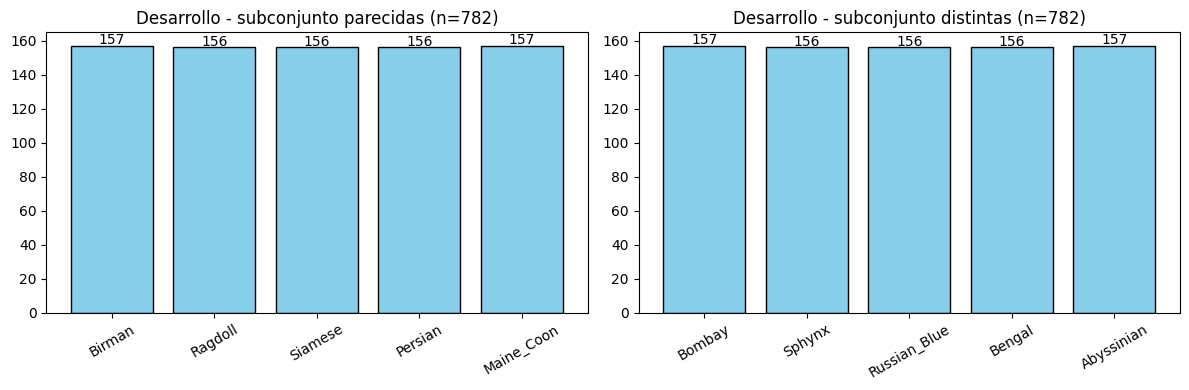


Imágenes por raza en la validación de cada fold - parecidas:
        Birman  Ragdoll  Siamese  Persian  Maine_Coon
fold 1      32       31       32       31          31
fold 2      32       31       31       31          32
fold 3      31       31       31       31          32
fold 4      31       31       31       32          31
fold 5      31       32       31       31          31

Imágenes por raza en la validación de cada fold - distintas:
        Bombay  Sphynx  Russian_Blue  Bengal  Abyssinian
fold 1      32      31            32      31          31
fold 2      32      31            31      31          32
fold 3      31      31            31      31          32
fold 4      31      31            31      32          31
fold 5      31      32            31      31          31


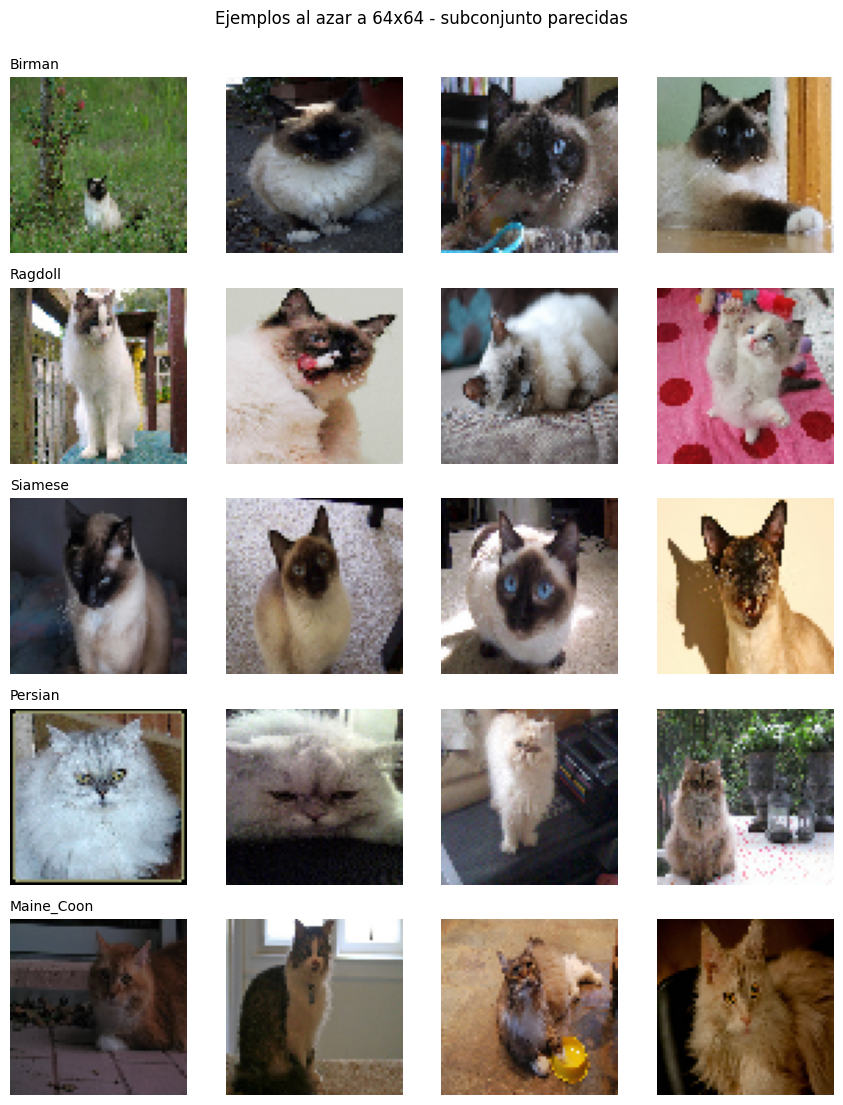

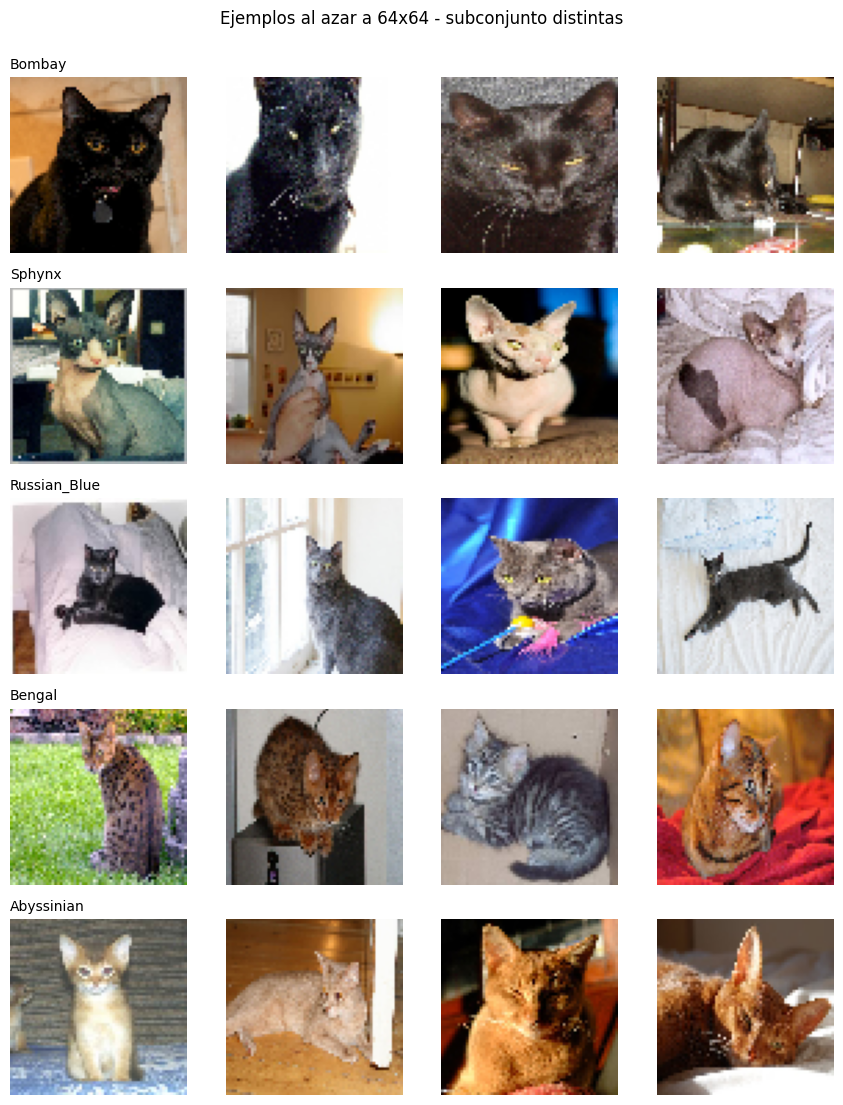

In [5]:
# ==========================================
# ETAPA 5 (EDA): BALANCE DE CLASES Y EJEMPLOS A 64x64 (solo conjunto de desarrollo)
# ==========================================
def graficar_balance(sp, ax, nombre):
    """Barras con la cantidad de imágenes por raza en el conjunto de desarrollo."""
    cuentas = sp["dev"]["raza"].value_counts().reindex(sp["clases"])
    ax.bar(cuentas.index, cuentas.values, color="skyblue", edgecolor="black")
    ax.set_title(f"Desarrollo - subconjunto {nombre} (n={len(sp['dev'])})")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(cuentas.values):
        ax.text(i, v + 1, str(v), ha="center")

def mostrar_ejemplos(nombre, por_raza=4):
    """Muestra por_raza imágenes al azar de cada raza, tal como las recibe la red."""
    sp = SPLITS[nombre]; clases = sp["clases"]
    rng = np.random.default_rng(SEED_SPLIT)
    fig, ejes = plt.subplots(len(clases), por_raza, figsize=(2.2 * por_raza, 2.2 * len(clases)))
    for i, c in enumerate(clases):
        idx = np.where(sp["y_dev"] == i)[0]
        for j, k in enumerate(rng.choice(idx, por_raza, replace=False)):
            ejes[i, j].imshow(sp["X_dev"][k]); ejes[i, j].axis("off")
            if j == 0:
                ejes[i, j].set_title(c, fontsize=10, loc="left")
    plt.suptitle(f"Ejemplos al azar a 64x64 - subconjunto {nombre}", y=1.0)
    plt.tight_layout(); guardar_fig(f"02_ejemplos_{nombre}"); plt.show()

# --- Balance de clases ---
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nombre, sp) in zip(ejes, SPLITS.items()):
    graficar_balance(sp, ax, nombre)
plt.tight_layout(); guardar_fig("01_distribucion_clases"); plt.show()

# --- Balance dentro de cada fold de validación ---
for nombre, sp in SPLITS.items():
    filas = []
    for i, (_, idx_va) in enumerate(sp["folds"], start=1):
        c = pd.Series(sp["y_dev"][idx_va]).value_counts().sort_index()
        filas.append(pd.Series(c.values, index=sp["clases"], name=f"fold {i}"))
    print(f"\nImágenes por raza en la validación de cada fold - {nombre}:")
    print(pd.DataFrame(filas).to_string())

# --- Ejemplos visuales ---
mostrar_ejemplos("parecidas")
mostrar_ejemplos("distintas")

### Interpretación del balance de clases

**Balance en el conjunto de desarrollo.** Cada subconjunto tiene 782 imágenes de desarrollo, con 156 o 157 por raza. Cada raza representa cerca del 20% del conjunto, lo que coincide con la línea base del azar (accuracy de 0,20). Como las clases ya están parejas por diseño (mismo número de imágenes por raza y partición estratificada), no se aplica `class_weight` ni otro tratamiento de desbalance. Este punto era una observación de la retroalimentación de la EP1, y aquí queda resuelto desde el muestreo.

**Balance dentro de los folds.** En la validación de cada fold hay 31 o 32 imágenes por raza (156 o 157 en total). La validación cruzada estratificada cumple su objetivo: ningún fold queda con más o menos razas que otro, por lo que las diferencias de métricas entre folds no se deberían a un desbalance de clases.

**Implicancia para la lectura de las métricas.** Con unas 31 imágenes por raza en cada fold, una sola imagen mal clasificada mueve el recall de una raza en cerca de 3 puntos porcentuales (1/31). Por eso se espera que las métricas por raza varíen bastante entre folds, y es una de las razones por las que se reportan como media ± desviación estándar y no como un único valor.

**Observaciones visuales a 64x64** (4 ejemplos al azar por raza; son impresiones, no conclusiones).

- *PARECIDAS:* Birman, Ragdoll y Siamese comparten el patrón de cuerpo claro con cara, orejas y patas oscuras, por lo que a simple vista son difíciles de separar entre sí. Siamese tiende a mostrar la máscara oscura más marcada y, en uno de los ejemplos, ojos azules visibles, pero Birman y Ragdoll también tienen ese contraste. Persian se distingue como un grupo aparte por el pelaje largo y esponjoso, aunque su color varía (blanco, gris y café), así que el color por sí solo no la identifica. Maine_Coon aparece sobre todo como gatos atigrados de pelaje marrón o gris y pelo semilargo, en interiores con fondos muy distintos (suelo de baldosas, una ventana, un recipiente amarillo); su color se superpone con el de Persian (que también aparece gris y café), así que el color por sí solo tampoco la identifica.
- *DISTINTAS:* Sphynx se reconoce de inmediato por la falta de pelo, las orejas grandes y la piel rosada o grisácea. Bengal y Abyssinian comparten tonos naranjo y café, y podrían confundirse; Bengal debería diferenciarse por las manchas, aunque uno de los cuatro ejemplos de Bengal es un gato gris atigrado que no se parece al patrón de manchas de los demás. Russian_Blue (gris) y Bombay (negro) se parecen por ser gatos oscuros, y en algunas fotos de Russian_Blue el gato se ve casi negro. En los ejemplos de Bombay los gatos son negros, con ojos amarillos o cobrizos; uno aparece sobreexpuesto contra un fondo blanco y en otro el pelaje se ve gris oscuro, lo que refuerza el posible parecido con Russian_Blue.
- *Variabilidad dentro de una misma raza:* los fondos son muy variados (pasto, ventanas, telas azules, camas rosadas con diseños, repisas con libros) y también la postura y el encuadre. En un ejemplo de Birman el gato ocupa una porción muy pequeña de la imagen y casi toda la foto es pasto, y en uno de Persian hay un borde negro alrededor de la foto.
- *Efecto del tamaño:* a 64x64 las imágenes se ven pixeladas, y se pierde detalle fino de ojos, hocico y largo del pelaje, justo lo que ayudaría a separar las razas del trío de colores parecidos. Cuando el gato ocupa poco espacio de la foto (como el Birman en el pasto), casi no queda información útil sobre el animal.

**Implicancia para el modelado.** Hay dos riesgos que se revisan más adelante con la auditoría y Grad-CAM: (1) que el modelo aprenda el fondo o el color en lugar del animal, dado que los fondos varían tanto, y (2) que las razas parecidas de PARECIDAS se confundan sistemáticamente entre sí.

### 5.2 Calidad de datos y dimensiones

Se abren las imágenes originales del conjunto de desarrollo (ambos subconjuntos) y se registran su ancho, alto y modo de color, y se detectan archivos dañados. Es como revisar la mercadería al recibirla: si hay una caja rota o de otro tamaño, conviene saberlo antes de armar el pedido. Esto decide cómo se redimensionan las imágenes: si las fotos originales no son cuadradas, llevarlas a 64x64 las deforma.

Registros duplicados por nombre de imagen: 0
Valores faltantes en columnas clave: {'imagen': 0, 'especie': 0, 'raza': 0, 'ruta': 0}
Imágenes analizadas: 1564
Ancho: min 114 | max 1725 | media 438 | mediana 500
Alto:  min 103 | max 1600 | media 391 | mediana 375
Proporción ancho/alto: mediana 1.33 | 63% más anchas que altas | 29% más altas que anchas
Modos de color: {'RGB': 1563, 'RGBA': 1}
Imágenes corruptas: 0


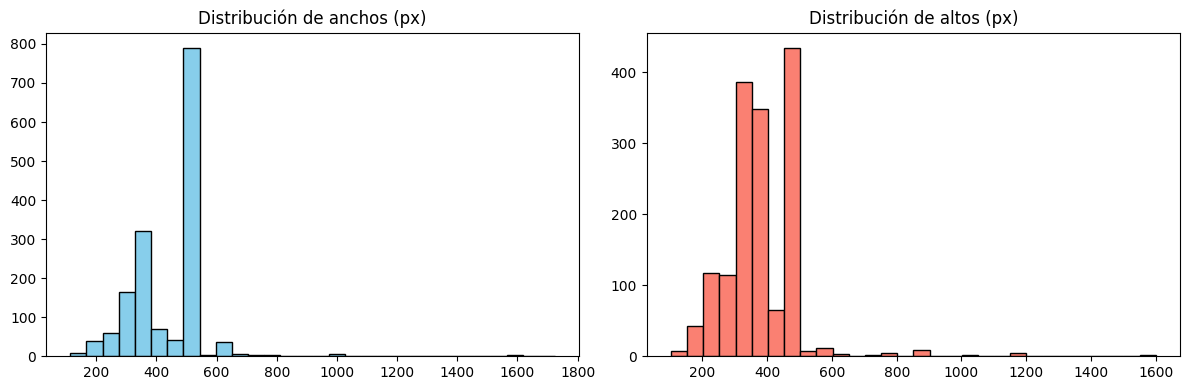

In [6]:
# ==========================================
# ETAPA 5 (EDA): CALIDAD DE DATOS Y DIMENSIONES (conjunto de desarrollo, ambos subconjuntos)
# ==========================================
def analizar_calidad(rutas):
    """Abre cada imagen original y devuelve sus anchos, altos, modos de color y los archivos dañados."""
    anchos, altos, modos, corruptas = [], [], [], []
    for r in rutas:
        try:
            with Image.open(r) as im:
                im.load()                       # fuerza la lectura completa: detecta archivos dañados
                anchos.append(im.size[0]); altos.append(im.size[1]); modos.append(im.mode)
        except Exception as e:
            corruptas.append((r, str(e)))
    return anchos, altos, modos, corruptas

duplicadas = lista["imagen"].duplicated().sum()
faltantes_indice = lista[["imagen", "especie", "raza", "ruta"]].isna().sum()
print("Registros duplicados por nombre de imagen:", int(duplicadas))
print("Valores faltantes en columnas clave:", faltantes_indice.to_dict())
assert duplicadas == 0, "Hay nombres de imagen duplicados en el índice"
assert faltantes_indice.sum() == 0, "Hay datos faltantes en columnas clave"

# EDA de imágenes limitado al conjunto de desarrollo.
rutas_dev = pd.concat([sp["dev"]["ruta"] for sp in SPLITS.values()])
anchos, altos, modos, corruptas = analizar_calidad(rutas_dev)
proporcion = np.array(anchos) / np.array(altos)

print(f"Imágenes analizadas: {len(anchos)}")
print(f"Ancho: min {min(anchos)} | max {max(anchos)} | media {np.mean(anchos):.0f} | mediana {np.median(anchos):.0f}")
print(f"Alto:  min {min(altos)} | max {max(altos)} | media {np.mean(altos):.0f} | mediana {np.median(altos):.0f}")
print(f"Proporción ancho/alto: mediana {np.median(proporcion):.2f} | "
      f"{(proporcion > 1.1).mean() * 100:.0f}% más anchas que altas | "
      f"{(proporcion < 0.9).mean() * 100:.0f}% más altas que anchas")
print(f"Modos de color: {dict(Counter(modos))}")
print(f"Imágenes corruptas: {len(corruptas)}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(anchos, bins=30, color="skyblue", edgecolor="black"); ejes[0].set_title("Distribución de anchos (px)")
ejes[1].hist(altos, bins=30, color="salmon", edgecolor="black"); ejes[1].set_title("Distribución de altos (px)")
plt.tight_layout(); guardar_fig("03_dimensiones"); plt.show()

### Interpretación de la calidad de datos y las dimensiones

**Dimensiones.** Se analizaron las 1.564 imágenes del conjunto de desarrollo (782 por subconjunto). Los anchos van de 114 a 1.725 px (media 438, mediana 500) y los altos de 103 a 1.600 px (media 391, mediana 375). En el histograma de anchos, cerca de la mitad de las imágenes se concentra en una sola barra alrededor de los 500 px (supera las 780 imágenes), con un segundo grupo menor entre 300 y 400 px. Los altos se reparten entre 200 y 500 px, con una cola pequeña de imágenes más grandes (algunas sobre 800 px y una de 1.600 px). Como en el ancho la media es menor que la mediana, el grupo de imágenes pequeñas es el que baja el promedio.

**Proporción.** La proporción ancho/alto tiene mediana 1,33 (es decir, 4:3), pero no es uniforme: el 63% de las imágenes es más ancha que alta, el 29% es más alta que ancha y solo el 8% es casi cuadrada. Al redimensionar a 64x64 todas pasan a ser cuadradas, así que la deformación depende de la foto: las apaisadas (mayoría) se comprimen horizontalmente, en torno a un 25% respecto del alto en el caso típico de 500x375, y las verticales se comprimen en el sentido contrario. No se recorta, para no perder partes del animal; esta decisión puede revisarse más adelante como un hiperparámetro de preprocesamiento (por ejemplo, recorte central que conserva la proporción).

**Calidad de datos.** No hay imágenes corruptas (0 de 1.564). Todas están en modo RGB excepto una en modo RGBA (con canal de transparencia), que `load_img` convierte a RGB al cargarla, por lo que no requiere tratamiento manual.

**Coherencia con la EP2.** Los valores son casi iguales a los de la EP2 (por ejemplo, ancho medio 438 en ambos casos). Las pequeñas diferencias (alto mínimo 103 contra 108, alto medio 391 contra 392) se esperan porque aquí se analiza el conjunto de desarrollo completo (entrenamiento + validación) y antes solo el entrenamiento.

**Implicancia para el modelado.** Un tamaño de entrada fijo de 64x64 reduce las imágenes originales (de 103 a 1.725 px) a una fracción muy pequeña de su resolución, por lo que se pierde detalle fino. Es una limitación que se tendrá en cuenta al interpretar los resultados.

## 6. Alcance experimental: subconjunto PARECIDAS

El pipeline está implementado de forma general y funciona igual para PARECIDAS y DISTINTAS (la partición, la carga y el EDA ya se hicieron para ambos). Sin embargo, la validación cruzada multiplica por 5 el costo de cada entrenamiento y el trabajo se realiza en CPU dentro de un tiempo limitado (5 horas). Por eso la **experimentación (comparación MLP vs CNN, regularización y búsqueda de hiperparámetros) se concentra en el subconjunto PARECIDAS**, el más difícil: sus razas son visualmente similares, por lo que es donde la elección de arquitectura y de regularización más se nota, y donde el análisis de errores, el análisis de sesgos y la explicabilidad aportan más información.

Es como entrenar para un examen practicando con los ejercicios más difíciles: si el método funciona ahí, es razonable esperar que funcione en el caso más fácil. Esa suposición se comprueba al final, ejecutando el pipeline una sola vez sobre DISTINTAS con la configuración elegida, si el tiempo lo permite.

In [7]:
# ==========================================
# ALCANCE EXPERIMENTAL: SUBCONJUNTO PRINCIPAL
# ==========================================
SUBCONJUNTO = "parecidas"
sp = SPLITS[SUBCONJUNTO]
X_dev, y_dev, folds = sp["X_dev"], sp["y_dev"], sp["folds"]
X_test, y_test = sp["X_test"], sp["y_test"]
CLASES = sp["clases"]
N_CLASES = len(CLASES)

print(f"Subconjunto de trabajo: {SUBCONJUNTO} | clases: {CLASES}")
print(f"Desarrollo: {X_dev.shape} | Test: {X_test.shape} | folds: {len(folds)}")
print(f"Línea base del azar (accuracy): {1 / N_CLASES:.2f}")

Subconjunto de trabajo: parecidas | clases: ['Birman', 'Ragdoll', 'Siamese', 'Persian', 'Maine_Coon']
Desarrollo: (782, 64, 64, 3) | Test: (138, 64, 64, 3) | folds: 5
Línea base del azar (accuracy): 0.20


## 7. Etapa de construcción de los modelos

Se definen dos funciones, una para la **MLP** y otra para la **CNN**. Reciben los hiperparámetros como argumentos (neuronas, filtros, dropout, learning rate, regularización L2), de modo que la validación cruzada y la búsqueda de hiperparámetros puedan llamarlas muchas veces sin modificar el código. Es como una máquina de hacer moldes: se cambia el ajuste de la máquina, no la máquina. Todos los modelos se compilan con el optimizador Adam (Kingma y Ba, 2015).

**Arquitecturas de partida (iguales a EP1 y EP2):**
- *MLP:* aplana la imagen (64x64x3 = 12.288 valores) → Dense(128, ReLU) → Dropout → Dense(5, softmax).
- *CNN:* 3 bloques Conv(3x3) + MaxPooling con 32, 64 y 128 filtros → GlobalAveragePooling → Dense(64, ReLU) → Dropout → Dense(5, softmax).

**Regularización y normalización:**
- *Aumento de datos* (giro horizontal, rotación y desplazamiento leves): solo actúa durante el entrenamiento; en validación y test las imágenes entran sin modificar.
- *Dropout* (Srivastava et al., 2014): apaga neuronas al azar durante el entrenamiento para que la red no dependa de unas pocas.
- *Regularización L2:* el constructor estándar la acepta mediante `l2`; la búsqueda principal de la sección 9 no la incluyó. Se evaluó después, con `l2=1e-4`, en el experimento controlado de la sección 9.7.
- *Batch Normalization:* se añadió con constructores específicos y se evaluó en la sección 9.7. No forma parte de los constructores estándar ni se probó combinada con L2.
- *Early Stopping:* se aplica en la función de entrenamiento (siguiente etapa).

**Normalización sin filtración de datos.** Cada modelo aprende la media y la desviación estándar de los píxeles con `Normalization.adapt`. Con validación cruzada esto tiene que hacerse **con los datos de entrenamiento de cada fold, y nunca con los de validación**. Es como estudiar para un examen sin haber visto las preguntas: si la normalización usara también los datos de validación, el modelo "espiaría" el examen. Por eso las funciones reciben `X_adapt`, que en cada fold será solo su set de entrenamiento.


In [8]:
# ==========================================
# ETAPA 7: FUNCIONES QUE CONSTRUYEN LA MLP Y LA CNN
# ==========================================
from tensorflow.keras import regularizers

def _bloque_entrada(X_adapt, aumento, resolucion):
    """Capas comunes a ambos modelos: entrada, aumento de datos (solo en entrenamiento) y normalización.
    La media y desviación se calculan SOLO con X_adapt (el entrenamiento del fold)."""
    capas = [layers.Input(shape=(resolucion, resolucion, 3))]
    if aumento:
        capas += [layers.RandomFlip("horizontal"), layers.RandomRotation(0.055),
                  layers.RandomTranslation(0.1, 0.1)]
    capas.append(layers.Rescaling(1 / 255))
    norm = layers.Normalization(axis=-1)
    norm.adapt(X_adapt.astype("float32") / 255.0)
    capas.append(norm)
    return capas

def _compilar(capas, lr):
    """Arma el modelo Sequential con las capas dadas y lo compila (Adam, entropía cruzada categórica dispersa, accuracy)."""
    m = models.Sequential(capas)
    m.compile(optimizer=optimizers.Adam(learning_rate=lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def crear_mlp(X_adapt, n_clases=N_CLASES, neuronas=128, dropout=0.3, lr=1e-4, l2=0.0,
              aumento=True, resolucion=RES_BASE):
    """MLP: Flatten -> Dense(neuronas, ReLU) -> Dropout -> Dense(n_clases, softmax)."""
    reg = regularizers.l2(l2) if l2 > 0 else None
    capas = _bloque_entrada(X_adapt, aumento, resolucion)
    capas += [layers.Flatten(),
              layers.Dense(neuronas, activation="relu", kernel_regularizer=reg),
              layers.Dropout(dropout),
              layers.Dense(n_clases, activation="softmax")]
    return _compilar(capas, lr)

def crear_cnn(X_adapt, n_clases=N_CLASES, filtros=(32, 64, 128), kernel=3, densa=64,
              dropout=0.3, lr=1e-3, l2=0.0, aumento=True, resolucion=RES_BASE):
    """CNN: [Conv + MaxPooling] x len(filtros) -> GlobalAveragePooling -> Dense(densa) -> Dropout -> softmax."""
    reg = regularizers.l2(l2) if l2 > 0 else None
    capas = _bloque_entrada(X_adapt, aumento, resolucion)
    for i, f in enumerate(filtros, start=1):
        capas += [layers.Conv2D(f, kernel, padding="same", activation="relu",
                                kernel_regularizer=reg, name=f"conv{i}"),
                  layers.MaxPooling2D(2, name=f"pool{i}")]
    capas += [layers.GlobalAveragePooling2D(name="gap"),
              layers.Dense(densa, activation="relu", kernel_regularizer=reg),
              layers.Dropout(dropout),
              layers.Dense(n_clases, activation="softmax")]
    return _compilar(capas, lr)

# --- Verificación: parámetros calculados a mano vs. contados por Keras ---
X_demo = X_dev[folds[0][0]]                        # entrenamiento del fold 1 (solo para construir los modelos)
mlp_demo, cnn_demo = crear_mlp(X_demo), crear_cnn(X_demo)

ENTRADA = RES_BASE * RES_BASE * 3
mlp_mano = 7 + (ENTRADA + 1) * 128 + (128 + 1) * N_CLASES                      # 7 = parámetros de Normalization
cnn_mano = 7 + (3*3*3 + 1) * 32 + (3*3*32 + 1) * 64 + (3*3*64 + 1) * 128 \
             + (128 + 1) * 64 + (64 + 1) * N_CLASES
print(f"MLP: a mano {mlp_mano:,} | Keras {mlp_demo.count_params():,}")
print(f"CNN: a mano {cnn_mano:,} | Keras {cnn_demo.count_params():,}")
assert mlp_mano == mlp_demo.count_params() and cnn_mano == cnn_demo.count_params()
cnn_demo.summary()

MLP: a mano 1,573,644 | Keras 1,573,644
CNN: a mano 101,836 | Keras 101,836


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_1 (Normalization) │ (None, 64, 64, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,836 (397.80 KB)

 Trainable params: 101,829 (397.77 KB)

 Non-trainable params: 7 (32.00 B)

## 8. Etapa de entrenamiento y evaluación con validación cruzada

Se definen tres funciones que trabajan en cadena, como una línea de ensamblaje:

1. **`metricas`**: calcula Accuracy, Precision, Recall y F1 (macro) y el recall mínimo entre razas. Se usa F1 y recall mínimo y no solo Accuracy porque el recall mínimo detecta si el modelo ignora alguna raza, algo que el Accuracy puede esconder.
2. **`entrenar_fold`**: entrena un modelo en un fold. Construye el modelo con los datos de entrenamiento de ese fold (la normalización solo ve esos datos), entrena con **Early Stopping** (se detiene cuando la pérdida de validación deja de mejorar y recupera los mejores pesos) y evalúa en la validación del fold.
3. **`validacion_cruzada`**: repite `entrenar_fold` en los 5 folds y entrega una tabla con una fila por fold, de la cual se calcula la **media ± desviación estándar** de cada métrica.

**Cómo leer media ± desviación estándar.** La media dice cuánto rinde el modelo en promedio. La desviación estándar dice cuánto cambia ese rendimiento de un fold a otro: si es pequeña, el modelo es estable; si es grande, su rendimiento depende mucho de qué imágenes le toquen. Aquí se usa la desviación estándar muestral (ddof=1), que es la que calcula `pandas`.

**Límite honesto de la validación cruzada.** Early Stopping usa la validación del fold para decidir cuándo parar, así que las métricas de validación son levemente optimistas. Por eso el modelo final se evalúa en el **test**, que ningún paso del pipeline ha visto.

**Configuración de entrenamiento.** La MLP usa los valores de la EP1 (hasta 150 épocas, paciencia 20). La CNN usa un tope menor (60 épocas, paciencia 10) porque cada entrenamiento en CPU es mucho más lento y la validación cruzada lo repite 5 veces. Tras medir los tiempos (sección 8.2) se mantuvieron estos topes. En el fold de la sección 9.6 ninguna configuración elegida llegó al máximo (MLP: 113 de 150 épocas; CNN: 42 de 60), aunque las paciencias sí difieren. La comparación principal de los modelos seleccionados no aísla por completo el efecto de arquitectura. La sección 9.7 añade una comparación exploratoria con topes comunes de 60 épocas y paciencia 10.


In [9]:
# ==========================================
# ETAPA 8: ENTRENAMIENTO Y VALIDACIÓN CRUZADA
# ==========================================
BATCH = 32
TRAIN_CFG = {"mlp": dict(epocas_max=150, paciencia=20),     # igual que EP1
             "cnn": dict(epocas_max=60,  paciencia=10)}     # tope menor por costo en CPU
CONSTRUCTORES = {"mlp": crear_mlp, "cnn": crear_cnn}

def metricas(y_true, y_pred):
    """Accuracy, Precision, Recall y F1 (macro) y el recall más bajo entre razas."""
    return dict(acc=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, average="macro", zero_division=0),
                recall=recall_score(y_true, y_pred, average="macro", zero_division=0),
                f1=f1_score(y_true, y_pred, average="macro", zero_division=0),
                recall_min=recall_score(y_true, y_pred, average=None, zero_division=0).min())

def entrenar_fold(tipo, params, idx_tr, idx_va, seed):
    """Entrena un modelo ('mlp' o 'cnn') en un fold con Early Stopping y lo evalúa en la validación del fold.
    La normalización se ajusta SOLO con las imágenes de entrenamiento del fold."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    cfg = TRAIN_CFG[tipo]
    modelo = CONSTRUCTORES[tipo](X_adapt=X_dev[idx_tr], **params)
    es = EarlyStopping(monitor="val_loss", patience=cfg["paciencia"], restore_best_weights=True)
    t0 = time.time()
    h = modelo.fit(X_dev[idx_tr], y_dev[idx_tr], validation_data=(X_dev[idx_va], y_dev[idx_va]),
                   epochs=cfg["epocas_max"], batch_size=BATCH, callbacks=[es], verbose=0)
    seg = time.time() - t0
    pred = modelo.predict(X_dev[idx_va], verbose=0).argmax(axis=1)
    mejor = int(np.argmin(h.history["val_loss"]))
    fila = dict(**metricas(y_dev[idx_va], pred),
                acc_train=h.history["accuracy"][mejor], epoca_mejor=mejor + 1,
                epocas_totales=len(h.history["loss"]), segundos=seg, parametros=modelo.count_params())
    return fila, h.history

def validacion_cruzada(tipo, params, seed=SEEDS_FINAL[0], verbose=True):
    """Repite entrenar_fold en los K folds. Devuelve (tabla con una fila por fold, lista de historiales)."""
    filas, historiales = [], []
    for i, (idx_tr, idx_va) in enumerate(folds, start=1):
        fila, hist = entrenar_fold(tipo, params, idx_tr, idx_va, seed)
        fila["fold"] = i
        filas.append(fila); historiales.append(hist)
        if verbose:
            print(f"  fold {i}: F1 {fila['f1']:.3f} | acc {fila['acc']:.3f} | "
                  f"mejor época {fila['epoca_mejor']} | {fila['segundos']:.0f} s")
    return pd.DataFrame(filas).set_index("fold"), historiales

def resumir(df, columnas=("acc", "precision", "recall", "f1", "recall_min")):
    """Media ± desviación estándar muestral de cada métrica sobre los folds."""
    return pd.Series({c: f"{df[c].mean():.3f} ± {df[c].std():.3f}" for c in columnas})

print("Funciones de entrenamiento y validación cruzada definidas.")

Funciones de entrenamiento y validación cruzada definidas.


### 8.1 Prueba de tiempo en un fold

Antes de lanzar la validación cruzada completa se entrena **un solo fold** de cada modelo con su configuración de partida. El objetivo no es evaluar el rendimiento, sino medir cuánto demora cada entrenamiento en CPU. Es como cronometrar una vuelta de prueba antes de decidir cuántas vueltas caben en el tiempo disponible. Con esa medida se estima cuántos experimentos (cada uno de 5 folds) caben en el presupuesto de 5 horas, y se ajustan los topes de épocas si hace falta.

In [10]:
# ==========================================
# 8.1 PRUEBA DE TIEMPO: UN FOLD POR MODELO (configuración de partida)
# ==========================================
PARAMS_BASE = {"mlp": dict(neuronas=128, dropout=0.3, lr=1e-4),
               "cnn": dict(filtros=(32, 64, 128), dropout=0.3, lr=1e-3)}

idx_tr, idx_va = folds[0]
prueba = {}
for tipo in ["mlp", "cnn"]:
    fila, hist = entrenar_fold(tipo, PARAMS_BASE[tipo], idx_tr, idx_va, seed=SEEDS_FINAL[0])
    prueba[tipo] = fila
    s_epoca = fila["segundos"] / fila["epocas_totales"]
    print(f"{tipo.upper()}: {fila['segundos']:.0f} s | {fila['epocas_totales']} épocas "
          f"(mejor: {fila['epoca_mejor']}) | {s_epoca:.1f} s/época | "
          f"F1 val {fila['f1']:.3f} | acc val {fila['acc']:.3f}")

print("\nEstimación para una validación cruzada de 5 folds:")
for tipo, fila in prueba.items():
    print(f"  {tipo.upper()}: ~{5 * fila['segundos'] / 60:.1f} min por configuración")

MLP: 50 s | 34 épocas (mejor: 14) | 1.5 s/época | F1 val 0.418 | acc val 0.420
CNN: 373 s | 44 épocas (mejor: 34) | 8.5 s/época | F1 val 0.467 | acc val 0.478

Estimación para una validación cruzada de 5 folds:
  MLP: ~4.2 min por configuración
  CNN: ~31.1 min por configuración


### 8.2 Presupuesto de cómputo y estrategia de experimentación

La medición de referencia guardada en esta corrida tomó **50 s para la MLP** (34 épocas; 1,5 s/época) y **373 s para la CNN** (44 épocas; 8,5 s/época). Al multiplicar esos tiempos por cinco folds, la estimación era de ~4,2 min por configuración MLP y ~31,1 min por configuración CNN. En la validación cruzada observada, `MLP_base` tomó **4,5 min** y `CNN_base` **25,6 min**; `CNN_sin_aumento` tomó **31,9 min**. Por tanto, el tiempo real dependió de la configuración y los folds, y la estimación no fue exacta. La estrategia fue:

- **Optimización controlada, un hiperparámetro a la vez.** Se parte de una configuración base y se cambia un factor por vez, para poder atribuir cada diferencia a ese factor.
- **MLP:** 4 factores (learning rate, neuronas, dropout y aumento de datos) con 7 configuraciones adicionales (2 alternativas por factor, salvo el aumento, que solo se prueba sin aumento), porque es más rápida.
- **CNN:** 3 factores (learning rate, dropout y aumento de datos) con 5 configuraciones adicionales y un costo observado de 21,0 a 31,9 min por configuración.
- **Todas las configuraciones se evalúan con la misma validación cruzada de 5 folds**, con los mismos folds y la misma semilla, de modo que sean comparables.
- **Los topes de épocas se mantienen:** la CNN de la prueba terminó por paciencia (época 44, mejor época 34) y no por el tope de 60 épocas, por lo que el tope no limita ese fold.
- **Cada resultado se guarda en `resultados/` apenas termina**, para no perder trabajo si la sesión de Colab se interrumpe.

El F1 del fold de la prueba (MLP 0,418; CNN 0,467) no se interpreta: es un único fold con una única semilla, y la comparación se hace con la validación cruzada completa.


In [11]:
# ETAPA 8.2: CHECKPOINT LOCAL/PERSISTENTE OPCIONAL
import pickle, shutil
RESPALDO = os.environ.get("EP3_BACKUP_DIR",
    "/content/respaldo_local" if os.path.isdir("/content") else str(Path("work") / "respaldo_local"))
Path(RESPALDO).mkdir(parents=True, exist_ok=True)
RES_CSV = "resultados/cv_resumen.csv"
CHECKPOINT_SCHEMA = 2
FINGERPRINT_PIPELINE = "ep3-rbg-v2-seed2604-64px-5fold"
REANUDAR = True

def guardar_estado():
    """Escribe el checkpoint de forma atómica y copia artefactos existentes."""
    estado = {"schema": CHECKPOINT_SCHEMA, "fingerprint": FINGERPRINT_PIPELINE}
    for n in ["RES", "RES_PARAMS", "PROBS_TEST", "FILAS_TEST"]:
        if n in globals(): estado[n] = globals()[n]
    tmp = Path(RESPALDO) / "estado.tmp"
    with open(tmp, "wb") as f: pickle.dump(estado, f)
    tmp.replace(Path(RESPALDO) / "estado.pkl")
    for carpeta in ["resultados", "images", "models"]:
        if Path(carpeta).is_dir():
            shutil.copytree(carpeta, Path(RESPALDO) / carpeta, dirs_exist_ok=True)

def cargar_estado():
    """Solo restaura resultados de checkpoints con versión y configuración compatibles."""
    ruta = Path(RESPALDO) / "estado.pkl"
    if not REANUDAR or not ruta.exists():
        print("Sin checkpoint compatible: ejecución desde cero."); return {}
    try:
        with open(ruta, "rb") as f: estado = pickle.load(f)
    except Exception as e:
        print(f"Checkpoint ilegible; ejecución desde cero ({type(e).__name__})."); return {}
    if estado.get("schema") != CHECKPOINT_SCHEMA or estado.get("fingerprint") != FINGERPRINT_PIPELINE:
        print("Checkpoint antiguo/incompatible: no se reutilizan resultados.")
        return {}
    for carpeta in ["resultados", "images", "models"]:
        origen = Path(RESPALDO) / carpeta
        if origen.is_dir(): shutil.copytree(origen, carpeta, dirs_exist_ok=True)
    print("Checkpoint compatible restaurado.")
    return estado

_estado = cargar_estado()
RES = _estado.get("RES", {})
RES_PARAMS = _estado.get("RES_PARAMS", {})
PROBS_TEST = _estado.get("PROBS_TEST", {})
FILAS_TEST = _estado.get("FILAS_TEST", [])

def guardar_resultado(nombre, tipo, params, df):
    """Guarda el resumen de métricas y el detalle por fold en archivos CSV.

    Args:
        nombre: Identificador de la configuración evaluada.
        tipo: Arquitectura del modelo ("mlp" o "cnn").
        params: Hiperparámetros usados en la configuración.
        df: DataFrame con las métricas obtenidas en cada fold.
    """
    fila = dict(config=nombre, modelo=tipo, params=str(params), segundos_total=df["segundos"].sum())
    for c in ["acc", "precision", "recall", "f1", "recall_min"]:
        fila[c + "_media"], fila[c + "_std"] = df[c].mean(), df[c].std()
    pd.DataFrame([fila]).to_csv(RES_CSV, mode=("a" if RES else "w"), header=(not RES or not os.path.exists(RES_CSV)), index=False)
    df.to_csv(f"resultados/cv_folds_{nombre}.csv")

def correr_config(nombre, tipo, params):
    """Recupera o ejecuta una configuración de validación cruzada.

    Si el checkpoint coincide con la firma actual, reutiliza el resultado;
    si no, entrena los folds, guarda métricas/historiales y actualiza el checkpoint.
    """
    firma = {"tipo": tipo, "params": params, "seed": SEEDS_FINAL[0], "folds": K_FOLDS}
    if nombre in RES and RES_PARAMS.get(nombre) == firma:
        df = RES[nombre][0]
        print(f"[{nombre}] restaurada de checkpoint compatible"); print(resumir(df).to_string()); return df
    if nombre in RES:
        print(f"[{nombre}] configuración de checkpoint distinta; se recalcula")
        RES.pop(nombre, None)
    print(f"[{nombre}] {tipo.upper()} {params}")
    df, hist = validacion_cruzada(tipo, params)
    guardar_resultado(nombre, tipo, params, df)
    RES[nombre] = (df, hist); RES_PARAMS[nombre] = firma
    guardar_estado()
    print(resumir(df).to_string())
    print(f"  tiempo total: {df['segundos'].sum() / 60:.1f} min")
    return df

df_mlp_base = correr_config("MLP_base", "mlp", PARAMS_BASE["mlp"])
df_mlp_base


Sin checkpoint compatible: ejecución desde cero.
[MLP_base] MLP {'neuronas': 128, 'dropout': 0.3, 'lr': 0.0001}
  fold 1: F1 0.418 | acc 0.420 | mejor época 14 | 52 s
  fold 2: F1 0.395 | acc 0.414 | mejor época 12 | 50 s
  fold 3: F1 0.372 | acc 0.372 | mejor época 33 | 78 s
  fold 4: F1 0.360 | acc 0.372 | mejor época 3 | 34 s
  fold 5: F1 0.389 | acc 0.397 | mejor época 15 | 53 s
acc           0.395 ± 0.023
precision     0.391 ± 0.025
recall        0.396 ± 0.023
f1            0.387 ± 0.022
recall_min    0.234 ± 0.084
  tiempo total: 4.5 min


,acc,precision,recall,f1,recall_min,acc_train,epoca_mejor,epocas_totales,segundos,parametros
fold,,,,,,,,,,
1,0.420382,0.422146,0.420968,0.417500,0.281250,0.430400,14,34,52.021719,1573644
2,0.414013,0.407366,0.416331,0.395396,0.156250,0.361600,12,32,50.491895,1573644
3,0.371795,0.372825,0.371774,0.371863,0.354839,0.410543,33,53,78.482780,1573644
4,0.371795,0.362015,0.372177,0.360127,0.161290,0.349840,3,23,34.354968,1573644
5,0.397436,0.388694,0.398589,0.389479,0.218750,0.400958,15,35,52.536311,1573644


### Interpretación de la validación cruzada base de la MLP

**Rendimiento medio.** La MLP base obtiene F1 macro de 0,387 ± 0,022 y accuracy de 0,395 ± 0,023. Como hay 5 razas balanceadas, el azar da un accuracy de 0,20, de modo que la MLP rinde cerca del doble del azar, pero sigue lejos de un clasificador confiable: se equivoca en más de la mitad de las imágenes. Es un valor del mismo orden que el F1 de prueba de la EP1 para este subconjunto (0,363), aunque no son directamente comparables porque aquí se mide en validación cruzada y allá en el set de prueba.

**Estabilidad entre folds.** La desviación estándar del F1 es pequeña (0,022): el F1 va de 0,360 (fold 4) a 0,418 (fold 1), un rango de unos 6 puntos. El rendimiento global de la MLP es estable frente a cambios en los datos de entrenamiento y validación.

**El recall mínimo es mucho menos estable.** El recall de la peor raza promedia 0,234 ± 0,084 y va de 0,156 a 0,355 según el fold. Con unas 31 imágenes por raza en cada fold, una sola imagen mal clasificada mueve el recall de una raza en cerca de 3 puntos porcentuales, así que esta métrica es más ruidosa y no conviene decidir solo con ella. Aun así, en 3 de los 5 folds el recall mínimo queda bajo 0,22, es decir, al menos una raza casi no se reconoce.

**Momento de parada.** La mejor época varía mucho (3, 12, 14, 15 y 33). En el fold 4 el modelo empeoró en validación después de la época 3, lo que indica que la MLP sobreajusta con rapidez y que Early Stopping está cumpliendo un papel importante. La `acc_train` de la tabla se mide con el aumento de datos y el dropout activos, por lo que no es comparable con la accuracy de validación y no se usa para medir el sobreajuste.

**Costo.** La validación cruzada completa tomó 4,5 minutos (entre 34 y 78 s por fold). La medición real fue mayor que la estimación inicial basada en un solo fold.

**Reproducibilidad.** El fold 1 reprodujo exactamente el F1 de la prueba de tiempo (0,418), lo que confirma que las semillas fijan el resultado.


In [12]:
# ==========================================
# 8.3 VALIDACIÓN CRUZADA BASE DE LA CNN (~25,6 min en CPU)
# ==========================================
df_cnn_base = correr_config("CNN_base", "cnn", PARAMS_BASE["cnn"])
df_cnn_base


[CNN_base] CNN {'filtros': (32, 64, 128), 'dropout': 0.3, 'lr': 0.001}
  fold 1: F1 0.467 | acc 0.478 | mejor época 34 | 371 s
  fold 2: F1 0.377 | acc 0.408 | mejor época 26 | 300 s
  fold 3: F1 0.440 | acc 0.449 | mejor época 48 | 476 s
  fold 4: F1 0.262 | acc 0.301 | mejor época 6 | 137 s
  fold 5: F1 0.385 | acc 0.397 | mejor época 19 | 255 s
acc           0.407 ± 0.067
precision     0.419 ± 0.078
recall        0.407 ± 0.067
f1            0.386 ± 0.079
recall_min    0.185 ± 0.121
  tiempo total: 25.6 min


,acc,precision,recall,f1,recall_min,acc_train,epoca_mejor,epocas_totales,segundos,parametros
fold,,,,,,,,,,
1,0.477707,0.513746,0.478024,0.466623,0.290323,0.502400,34,44,371.030978,101836
2,0.407643,0.426168,0.407056,0.377418,0.125000,0.398400,26,36,299.599523,101836
3,0.448718,0.448055,0.447782,0.439948,0.258065,0.565495,48,58,475.963152,101836
4,0.301282,0.300933,0.301411,0.261548,0.000000,0.290735,6,16,136.743097,101836
5,0.397436,0.404196,0.398387,0.385217,0.250000,0.420128,19,29,255.355563,101836


### Interpretación de la validación cruzada base de la CNN y primera comparación con la MLP

**Rendimiento medio.** La CNN base obtiene F1 macro de 0,386 ± 0,079 y accuracy de 0,407 ± 0,067. La MLP base obtuvo 0,387 ± 0,022 y 0,395 ± 0,023. Las medias de F1 son prácticamente idénticas (diferencia de 0,001), y la diferencia de accuracy (0,012) es mucho menor que cualquiera de las desviaciones estándar, por lo que con esta evidencia **no se puede afirmar que una arquitectura supere a la otra**.

**Estabilidad.** La CNN es unas 3,6 veces más variable que la MLP en F1 (desviación de 0,079 contra 0,022). Su F1 va de 0,262 (fold 4) a 0,467 (fold 1), un rango de 20 puntos, contra 6 puntos de la MLP. El rendimiento de la CNN depende mucho más de qué imágenes le toquen para entrenar y validar.

**Comparación fold a fold.** Como ambos modelos usan exactamente los mismos folds, se puede comparar por pares. La diferencia de F1 (CNN menos MLP) fue +0,049 en el fold 1, −0,018 en el 2, +0,068 en el 3, −0,099 en el 4 y −0,004 en el 5. La CNN gana en 2 folds y pierde en 3, y el único fold con una diferencia grande en contra es el 4.

**El fold 4.** En este fold la CNN se detuvo por Early Stopping tras solo 16 épocas, con la mejor en la 6, y su recall mínimo fue 0,000: ninguna imagen de al menos una raza fue clasificada correctamente. La MLP también tuvo su peor fold en el 4 (F1 0,360, mejor época 3), lo que sugiere que ese reparto de imágenes es difícil, y no solo un problema de la CNN. Las curvas de aprendizaje de la siguiente celda permiten ver qué ocurrió.

**Costo.** La validación cruzada de la CNN tomó 25,6 minutos, frente a 4,5 de la MLP (unas 5,7 veces más), y utiliza 101.836 parámetros contra 1.573.644 de la MLP (unas 15 veces menos).

**Lectura.** Con configuraciones de partida, la CNN no mejora a la MLP en promedio y es menos estable. Esto no demuestra que la convolución no sirva para este problema: ambas configuraciones están sin optimizar, y la búsqueda de hiperparámetros de las siguientes etapas es la que permite probar si la CNN mejora al ajustarla.


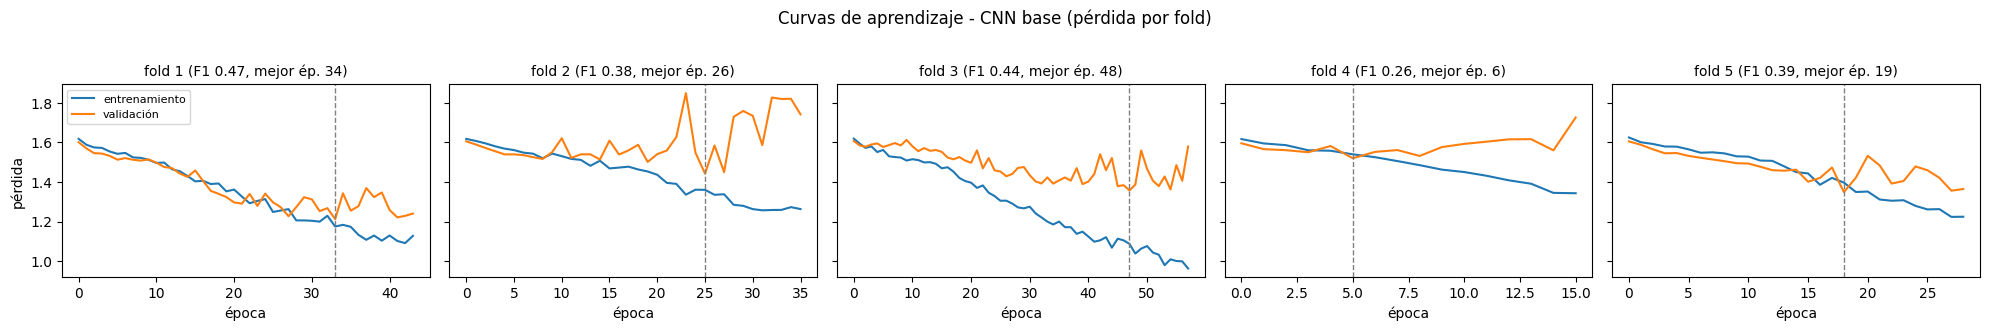

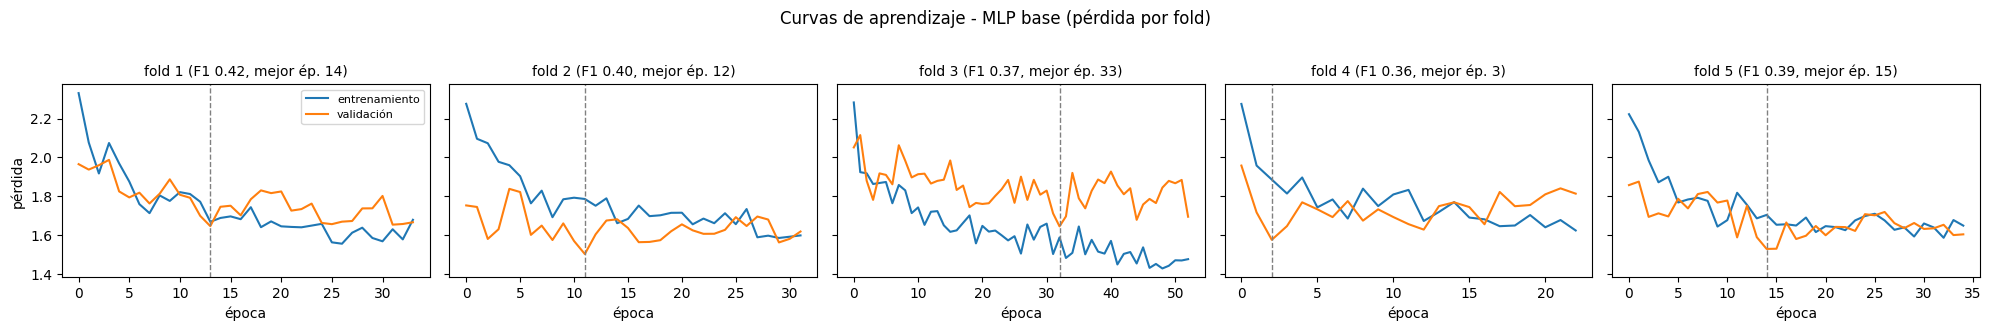

In [13]:
# ==========================================
# 8.4 CURVAS DE APRENDIZAJE DE LA CNN BASE (los 5 folds)
# ==========================================
def graficar_curvas(nombre, titulo):
    """Pérdida de entrenamiento y validación por época en cada fold de una configuración.
    La línea punteada marca la época elegida por Early Stopping (mejor val_loss)."""
    df, historiales = RES[nombre]
    fig, ejes = plt.subplots(1, len(historiales), figsize=(4 * len(historiales), 3.2), sharey=True)
    for i, (ax, h) in enumerate(zip(ejes, historiales), start=1):
        ax.plot(h["loss"], label="entrenamiento")
        ax.plot(h["val_loss"], label="validación")
        mejor = int(np.argmin(h["val_loss"]))
        ax.axvline(mejor, color="gray", linestyle="--", linewidth=1)
        ax.set_title(f"fold {i} (F1 {df.loc[i, 'f1']:.2f}, mejor ép. {mejor + 1})", fontsize=10)
        ax.set_xlabel("época")
        if i == 1:
            ax.set_ylabel("pérdida"); ax.legend(fontsize=8)
    plt.suptitle(titulo, y=1.02)
    plt.tight_layout(); guardar_fig(f"04_curvas_{nombre}"); plt.show()

graficar_curvas("CNN_base", "Curvas de aprendizaje - CNN base (pérdida por fold)")
graficar_curvas("MLP_base", "Curvas de aprendizaje - MLP base (pérdida por fold)")

### Interpretación de las curvas de aprendizaje

En las curvas, la línea punteada marca la época elegida por Early Stopping. Como referencia, una predicción al azar entre 5 razas da una pérdida de ln(5) ≈ 1,61. La pérdida de entrenamiento se mide con el aumento de datos y el dropout activos, por lo que la brecha que se observa subestima la brecha real entre entrenamiento y validación.

**CNN: tres comportamientos distintos según el fold.**
- *Folds 2 y 3 (sobreajuste).* La pérdida de entrenamiento sigue bajando (hasta cerca de 1,25 en el fold 2 y de 0,97 en el fold 3), mientras la de validación se estanca o sube. En el fold 2 la validación sube hasta cerca de 1,8 después de la época 26. El modelo memoriza detalles de las imágenes de entrenamiento que no generalizan.
- *Fold 1 (aprendizaje sano).* Entrenamiento y validación bajan juntas hasta cerca de 1,2 con una brecha pequeña. Es el fold con el mejor F1 (0,467).
- *Fold 4 (aprendizaje que no despega).* La pérdida de validación se mantiene cerca de 1,55 durante casi todo el entrenamiento, es decir, apenas por debajo del azar, y sube al final, mientras la de entrenamiento baja lento. Early Stopping cortó el entrenamiento en la época 16, con la mejor en la 6. Esto es consistente con el recall mínimo de 0,000 y el F1 de 0,262 de ese fold.
- *Ruido.* En los folds 2, 3 y 5 la pérdida de validación oscila bastante de una época a otra. Con solo unas 157 imágenes de validación por fold, parte de ese ruido es natural, pero también podría indicar que el learning rate (1e-3) es alto para esta red.

**MLP.** Las curvas de entrenamiento y validación quedan cerca una de la otra, con oscilaciones, y la pérdida de validación se mueve entre 1,5 y 1,7, es decir, cerca del nivel del azar. Esto es consistente con un F1 bajo (0,387) y con una desviación estándar pequeña: la MLP aprende poco, pero lo hace de forma pareja en todos los folds. Su problema no parece ser el sobreajuste, sino su capacidad de extraer información útil de los píxeles aplanados.

**Implicancias para la optimización.** Las curvas apuntan a dos líneas de trabajo: (1) en la CNN, más regularización para reducir el sobreajuste de los folds 2 y 3, y un learning rate distinto para estabilizar el entrenamiento; (2) en la MLP, explorar si un learning rate mayor o más neuronas le permiten aprender más. Estas hipótesis se ponen a prueba en la búsqueda de hiperparámetros de la siguiente etapa.

## 9. Etapa de optimización de hiperparámetros y análisis de regularización

**Diseño.** Se parte de la configuración base de cada modelo y se cambia **un solo hiperparámetro a la vez**, manteniendo el resto fijo, de modo que cualquier diferencia pueda atribuirse a ese cambio. Es como probar una receta cambiando un ingrediente por vez: si cambias la sal y el azúcar juntas, no sabes cuál mejoró el plato. Todas las configuraciones se evalúan con la misma validación cruzada de 5 folds y la misma semilla. La estrategia es una búsqueda tipo Grid Search sobre un factor a la vez, y las alternativas se eligen a partir de lo que mostraron las curvas de aprendizaje.

**La misma búsqueda mide el impacto de la regularización.** Variar el dropout entre 0,0 (sin dropout), 0,3 (base) y 0,5 permite medir su impacto, y una configuración *sin aumento de datos* mide el impacto del aumento. El impacto de Early Stopping se analiza con los historiales ya guardados, comparando el modelo en la época elegida contra el de la última época.

| Modelo | Factor | Base | Alternativas |
|---|---|---|---|
| MLP | learning rate | 1e-4 | 3e-4, 1e-3 |
| MLP | neuronas | 128 | 64, 256 |
| MLP | dropout | 0,3 | 0,0, 0,5 |
| MLP | aumento de datos | con | sin |
| CNN | learning rate | 1e-3 | 5e-4, 2e-3 |
| CNN | dropout | 0,3 | 0,0, 0,5 |
| CNN | aumento de datos | con | sin |

**Regla de selección (fijada antes de ejecutar).** Se elige la configuración con mayor **F1 macro medio** en la validación cruzada. Si dos configuraciones difieren en menos de 0,01 de F1 medio, se prefiere la de menor desviación estándar. Los resultados de test no participan en esta decisión.

**Alcance de la conclusión.** Como cada factor se varía por separado desde la base, la búsqueda no explora combinaciones entre factores. Si dos cambios ayudan por separado, su efecto combinado no está garantizado y no se verificó en este trabajo (queda como mejora, sección 14.4).

### 9.0 Regularización: técnicas y alcance de la evidencia

La búsqueda principal de hiperparámetros evaluó aumento de datos, Dropout y Early Stopping, además de la normalización de entrada. Después se ejecutó la comparación controlada de la sección 9.7, que añadió **L2 (`1e-4`) y Batch Normalization por separado** para ambas arquitecturas, junto con controles base. Se reportan cinco folds por configuración.

La evaluación adicional fue exploratoria: usa una sola semilla de entrenamiento y los mismos folds del proceso de selección, por lo que las diferencias no son una confirmación independiente ni se sometieron a una prueba inferencial. No se probó una combinación de L2 y Batch Normalization ni otros valores de `l2`. Los efectos observados se resumen después de la celda experimental de la sección 9.7.


In [14]:
# ==========================================
# 9.1 BÚSQUEDA DE HIPERPARÁMETROS DE LA MLP (un factor a la vez, ~43 min en CPU)
# ==========================================
BUSQUEDA_MLP = {
    "MLP_lr3e-4":      dict(lr=3e-4),
    "MLP_lr1e-3":      dict(lr=1e-3),
    "MLP_neuronas64":  dict(neuronas=64),
    "MLP_neuronas256": dict(neuronas=256),
    "MLP_dropout0.0":  dict(dropout=0.0),
    "MLP_dropout0.5":  dict(dropout=0.5),
    "MLP_sin_aumento": dict(aumento=False),
}

for nombre, cambio in BUSQUEDA_MLP.items():
    if nombre in RES:                       # permite reanudar si la sesión se interrumpe
        continue
    correr_config(nombre, "mlp", {**PARAMS_BASE["mlp"], **cambio})

# --- Tabla comparativa (media ± desviación estándar de cada configuración MLP) ---
nombres_mlp = ["MLP_base"] + list(BUSQUEDA_MLP)
tabla_mlp = pd.DataFrame({n: resumir(RES[n][0]) for n in nombres_mlp}).T
tabla_mlp["segundos"] = [round(RES[n][0]["segundos"].sum()) for n in nombres_mlp]
print(tabla_mlp.to_string())


[MLP_lr3e-4] MLP {'neuronas': 128, 'dropout': 0.3, 'lr': 0.0003}
  fold 1: F1 0.408 | acc 0.408 | mejor época 82 | 146 s
  fold 2: F1 0.415 | acc 0.414 | mejor época 41 | 87 s
  fold 3: F1 0.373 | acc 0.372 | mejor época 32 | 77 s
  fold 4: F1 0.371 | acc 0.372 | mejor época 24 | 65 s
  fold 5: F1 0.397 | acc 0.404 | mejor época 15 | 50 s
acc           0.394 ± 0.020
precision     0.397 ± 0.021
recall        0.394 ± 0.020
f1            0.393 ± 0.020
recall_min    0.308 ± 0.040
  tiempo total: 7.1 min
[MLP_lr1e-3] MLP {'neuronas': 128, 'dropout': 0.3, 'lr': 0.001}
  fold 1: F1 0.448 | acc 0.452 | mejor época 93 | 164 s
  fold 2: F1 0.437 | acc 0.446 | mejor época 88 | 155 s
  fold 3: F1 0.356 | acc 0.359 | mejor época 53 | 106 s
  fold 4: F1 0.378 | acc 0.378 | mejor época 88 | 155 s
  fold 5: F1 0.418 | acc 0.423 | mejor época 75 | 136 s
acc           0.412 ± 0.041
precision     0.414 ± 0.038
recall        0.412 ± 0.042
f1            0.407 ± 0.039
recall_min    0.266 ± 0.049
  tiempo to

Mejor F1 medio: MLP_lr1e-3 (0.407) | candidatas dentro de 0.01: ['MLP_lr1e-3']
Configuración elegida: MLP_lr1e-3 (F1 0.407 ± 0.039)


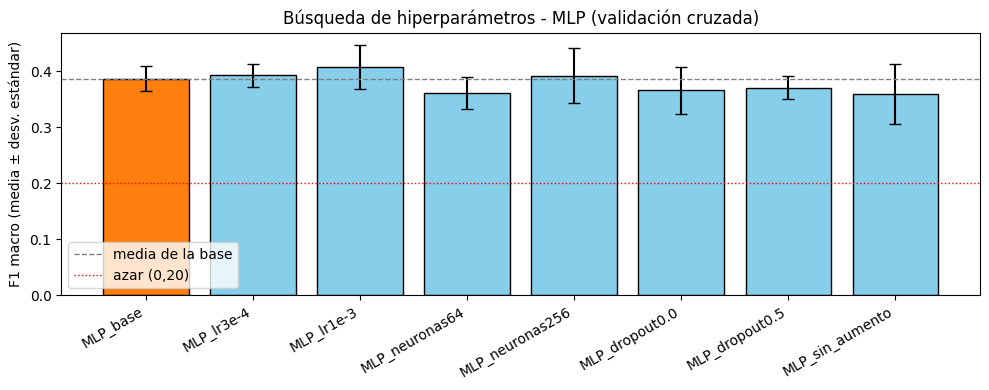

In [15]:
# ==========================================
# 9.2 SELECCIÓN SEGÚN LA REGLA FIJADA + GRÁFICO COMPARATIVO (MLP)
# ==========================================
def seleccionar(nombres, margen=0.01):
    """Regla fijada antes de ejecutar: mayor F1 medio; si hay configuraciones a menos de `margen`
    del mejor, se elige la de menor desviación estándar."""
    medias = {n: RES[n][0]["f1"].mean() for n in nombres}
    stds = {n: RES[n][0]["f1"].std() for n in nombres}
    mejor = max(medias, key=medias.get)
    candidatas = [n for n in nombres if medias[mejor] - medias[n] < margen]
    elegida = min(candidatas, key=stds.get)
    print(f"Mejor F1 medio: {mejor} ({medias[mejor]:.3f}) | candidatas dentro de {margen}: {candidatas}")
    print(f"Configuración elegida: {elegida} (F1 {medias[elegida]:.3f} ± {stds[elegida]:.3f})")
    return elegida

def graficar_comparacion(nombres, base, titulo, archivo):
    """Barras con el F1 medio ± desviación estándar de cada configuración (la base en otro color)."""
    medias = [RES[n][0]["f1"].mean() for n in nombres]
    stds = [RES[n][0]["f1"].std() for n in nombres]
    colores = ["tab:orange" if n == base else "skyblue" for n in nombres]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(range(len(nombres)), medias, yerr=stds, capsize=4, color=colores, edgecolor="black")
    ax.axhline(RES[base][0]["f1"].mean(), color="gray", linestyle="--", linewidth=1, label="media de la base")
    ax.axhline(1 / N_CLASES, color="red", linestyle=":", linewidth=1, label="azar (0,20)")
    ax.set_xticks(range(len(nombres))); ax.set_xticklabels(nombres, rotation=30, ha="right")
    ax.set_ylabel("F1 macro (media ± desv. estándar)"); ax.set_title(titulo); ax.legend()
    plt.tight_layout(); guardar_fig(archivo); plt.show()

ELEGIDA_MLP = seleccionar(nombres_mlp)
graficar_comparacion(nombres_mlp, "MLP_base", "Búsqueda de hiperparámetros - MLP (validación cruzada)", "05_busqueda_mlp")

### Interpretación de la búsqueda de hiperparámetros de la MLP

**Selección.** Aplicando la regla fijada antes de ejecutar (mayor F1 medio), la configuración elegida es `MLP_lr1e-3` (learning rate 1e-3, el resto igual a la base), con F1 macro de 0,407 ± 0,039 y accuracy de 0,412 ± 0,041, frente a 0,387 ± 0,022 y 0,395 ± 0,023 de la base. La siguiente mejor (`MLP_lr3e-4`, 0,393) queda a 0,014, por encima del margen de 0,01, por lo que no se aplicó el criterio de desempate por desviación estándar. Comparada fold a fold con la base, la diferencia de F1 fue +0,030, +0,042, −0,016, +0,018 y +0,029: gana en 4 de 5 folds, con una mejora media de unos 0,02.

**Learning rate.** El F1 medio sube de forma ordenada con el learning rate: 0,387 (1e-4), 0,393 (3e-4) y 0,407 (1e-3). Como el mejor valor es el extremo del rango probado, es posible que un valor aún mayor rinda más; no se probó. Con 1e-3 la mejor época llega mucho más tarde (entre las épocas 53 y 93, contra 3 a 33 en la base) y la validación cruzada completa cuesta 11,9 min (717 s) en vez de 4,5 (268 s), y la desviación estándar sube de 0,022 a 0,039. Con 3e-4 el recall mínimo medio fue el más alto de todas las configuraciones (0,308 ± 0,040), lo que sugiere que ese valor protege mejor a la raza peor reconocida.

**Número de neuronas.** Con 64 neuronas el F1 baja a 0,361 y con 256 sube a 0,392 (± 0,049). Más capacidad ayuda algo, pero 256 es más inestable (mayor desviación estándar) y la diferencia con 128 (0,005) es menor que el margen de 0,01.

**Impacto de la regularización (MLP).**
- *Dropout.* Sin dropout (0,0) el F1 es 0,366 ± 0,042, con 0,3 es 0,387 ± 0,022 y con 0,5 es 0,371 ± 0,020. El valor intermedio rinde mejor; sin dropout la desviación estándar casi se duplica. La diferencia entre los tres valores (unos 0,02) es del tamaño de una desviación estándar, así que el efecto es modesto.
- *Aumento de datos.* Sin aumento el F1 baja a 0,359 ± 0,054 (con aumento: 0,387 ± 0,022) y la mejor época cae a 2–8 (con aumento: 3–33). Es la señal típica de que, sin aumento, la red se sobreajusta casi de inmediato. Por fold el efecto no es uniforme (−0,111, 0,000, −0,002, −0,060 y +0,033): en el fold 5 sin aumento rindió mejor, y la media de la diferencia es −0,028.

**Cautelas.** (1) Las diferencias entre varias configuraciones (0,387, 0,392 y 0,393) son menores que una desviación estándar, por lo que no se pueden distinguir con esta evidencia. (2) Se compararon 8 configuraciones con una sola semilla y se eligió la mejor: el F1 de validación de la elegida es algo optimista, y su rendimiento real se medirá en el test. (3) Cada factor se varió por separado; la combinación de varios cambios no se evaluó.


In [16]:
# ==========================================
# 9.3 BÚSQUEDA DE HIPERPARÁMETROS DE LA CNN: LOTE 1 (~87 min en CPU)
# ==========================================
BUSQUEDA_CNN = {
    "CNN_lr5e-4":      dict(lr=5e-4),
    "CNN_lr2e-3":      dict(lr=2e-3),
    "CNN_dropout0.5":  dict(dropout=0.5),
    "CNN_dropout0.0":  dict(dropout=0.0),
    "CNN_sin_aumento": dict(aumento=False),
}

def correr_busqueda(nombres):
    """Corre las configuraciones indicadas de BUSQUEDA_CNN (omite las que ya terminaron)."""
    for n in nombres:
        if n not in RES:
            correr_config(n, "cnn", {**PARAMS_BASE["cnn"], **BUSQUEDA_CNN[n]})

correr_busqueda(["CNN_lr5e-4", "CNN_lr2e-3", "CNN_dropout0.5"])


[CNN_lr5e-4] CNN {'filtros': (32, 64, 128), 'dropout': 0.3, 'lr': 0.0005}
  fold 1: F1 0.461 | acc 0.478 | mejor época 39 | 424 s
  fold 2: F1 0.333 | acc 0.369 | mejor época 15 | 217 s
  fold 3: F1 0.261 | acc 0.295 | mejor época 16 | 221 s
  fold 4: F1 0.297 | acc 0.327 | mejor época 15 | 230 s
  fold 5: F1 0.432 | acc 0.449 | mejor época 55 | 538 s
acc           0.384 ± 0.078
precision     0.418 ± 0.083
recall        0.383 ± 0.079
f1            0.357 ± 0.087
recall_min    0.140 ± 0.106
  tiempo total: 27.1 min
[CNN_lr2e-3] CNN {'filtros': (32, 64, 128), 'dropout': 0.3, 'lr': 0.002}
  fold 1: F1 0.510 | acc 0.522 | mejor época 44 | 492 s
  fold 2: F1 0.379 | acc 0.408 | mejor época 16 | 225 s
  fold 3: F1 0.387 | acc 0.404 | mejor época 37 | 428 s
  fold 4: F1 0.323 | acc 0.372 | mejor época 12 | 207 s
  fold 5: F1 0.412 | acc 0.417 | mejor época 28 | 344 s
acc           0.424 ± 0.057
precision     0.428 ± 0.067
recall        0.424 ± 0.057
f1            0.402 ± 0.069
recall_min    0.

[CNN_dropout0.0] CNN {'filtros': (32, 64, 128), 'dropout': 0.0, 'lr': 0.001}
  fold 1: F1 0.437 | acc 0.452 | mejor época 31 | 373 s
  fold 2: F1 0.378 | acc 0.395 | mejor época 19 | 250 s
  fold 3: F1 0.376 | acc 0.391 | mejor época 25 | 303 s
  fold 4: F1 0.276 | acc 0.282 | mejor época 3 | 108 s
  fold 5: F1 0.351 | acc 0.365 | mejor época 14 | 225 s
acc           0.377 ± 0.062
precision     0.372 ± 0.054
recall        0.377 ± 0.062
f1            0.364 ± 0.058
recall_min    0.181 ± 0.037
  tiempo total: 21.0 min
[CNN_sin_aumento] CNN {'filtros': (32, 64, 128), 'dropout': 0.3, 'lr': 0.001, 'aumento': False}
  fold 1: F1 0.485 | acc 0.490 | mejor época 32 | 339 s
  fold 2: F1 0.417 | acc 0.427 | mejor época 30 | 356 s
  fold 3: F1 0.451 | acc 0.455 | mejor época 40 | 440 s
  fold 4: F1 0.454 | acc 0.455 | mejor época 27 | 291 s
  fold 5: F1 0.569 | acc 0.571 | mejor época 48 | 486 s
acc           0.480 ± 0.056
precision     0.491 ± 0.050
recall        0.479 ± 0.056
f1            0.475

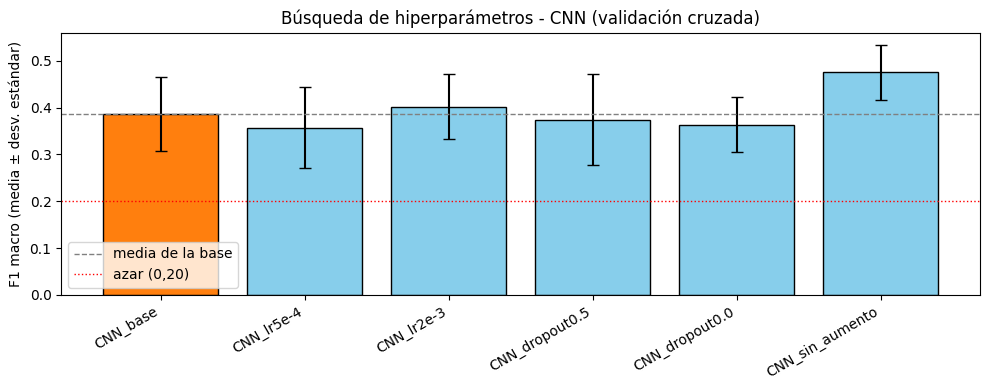

In [17]:
# ==========================================
# 9.3 BÚSQUEDA DE LA CNN: LOTE 2 + TABLA Y SELECCIÓN (~53 min en CPU)
# ==========================================
correr_busqueda(["CNN_dropout0.0", "CNN_sin_aumento"])

nombres_cnn = ["CNN_base"] + list(BUSQUEDA_CNN)
tabla_cnn = pd.DataFrame({n: resumir(RES[n][0]) for n in nombres_cnn}).T
tabla_cnn["segundos"] = [round(RES[n][0]["segundos"].sum()) for n in nombres_cnn]
print(tabla_cnn.to_string())

ELEGIDA_CNN = seleccionar(nombres_cnn)
graficar_comparacion(nombres_cnn, "CNN_base", "Búsqueda de hiperparámetros - CNN (validación cruzada)", "06_busqueda_cnn")


### Interpretación de la búsqueda de hiperparámetros de la CNN

**Selección.** Aplicando la regla fijada antes de ejecutar (mayor F1 medio), la configuración elegida es `CNN_sin_aumento` (sin aumento de datos, el resto igual a la base: filtros 32-64-128, dropout 0,3, learning rate 1e-3), con F1 macro de 0,475 ± 0,058 y accuracy de 0,480 ± 0,056, frente a 0,386 ± 0,079 y 0,407 ± 0,067 de la base. Ninguna otra configuración queda a menos de 0,01 del mejor F1, por lo que no se aplicó el desempate por desviación estándar.

**Aumento de datos (el factor con mayor impacto).** Quitar el aumento subió el F1 en los cinco folds: +0,018, +0,040, +0,011, +0,192 y +0,184 (media +0,089). Las mejoras mayores ocurrieron en los folds 4 y 5, y el fold 4, que en la base tenía F1 0,262 y recall mínimo de 0,000, pasó a F1 0,454. El recall mínimo medio también subió, de 0,185 a 0,327, el más alto de todas las configuraciones de la CNN. En cambio, en la MLP el efecto fue el contrario (el aumento mejoraba el F1 medio de 0,359 a 0,387), de modo que una técnica de regularización puede ayudar a una arquitectura y perjudicar a otra.

**Posibles explicaciones (hipótesis, no probadas).** (1) El aumento usado (giro horizontal, rotación de hasta ±20° y desplazamiento de ±10%) puede ser demasiado fuerte para una red pequeña de ~100.000 parámetros entrenada con 625 imágenes de 64x64: a esa resolución un desplazamiento de ±10% mueve la imagen unos 6 píxeles y puede sacar parte del gato del encuadre. (2) La convolución con pooling ya es en parte tolerante al desplazamiento, por lo que el desplazamiento aleatorio podría aportar poco a la CNN, mientras que la MLP, que no tiene esa propiedad, sí se beneficia. Para separar qué componente del aumento perjudica habría que probar cada uno por separado (por ejemplo, solo el giro horizontal), lo que no se hizo por costo de cómputo.

**Learning rate.** El F1 medio sube con el learning rate: 0,357 (5e-4), 0,386 (1e-3) y 0,402 (2e-3). Con 2e-3 la CNN mejora en 4 de 5 folds respecto de la base, con una diferencia media de +0,016. Como el mejor valor vuelve a ser el extremo del rango probado, no se sabe si un valor mayor rendiría más.

**Dropout.** Tanto 0,0 (F1 0,364) como 0,5 (F1 0,374) rinden menos que 0,3 (0,386) en promedio, y cada una mejora la base en solo 2 de 5 folds. El dropout 0,5 ayudó en los folds 1 y 2 y empeoró en el 3 (0,440 a 0,346). Con diferencias de 0,012 a 0,022 y desviaciones estándar de 0,06 a 0,10, no hay evidencia de que el dropout cambie el rendimiento de forma apreciable en este rango.

**Estabilidad.** La desviación estándar del F1 de la CNN elegida (0,058) es menor que la de la base (0,079), pero sigue siendo más del doble que la de la MLP base (0,022).

**Costo.** `CNN_sin_aumento` tomó 31,9 min de validación cruzada contra 25,6 min de la base, porque con menos ruido en el entrenamiento la mejor época llega más tarde (27 a 48 contra 6 a 48).

**Cautelas.** (1) Las barras de error de la CNN elegida y de la base se solapan: con solo 5 folds, y folds que comparten datos de entrenamiento entre sí, la mejora es consistente (positiva en 5 de 5 folds), pero su significancia estadística se evalúa de forma explícita más abajo. (2) Se probaron 6 configuraciones y se eligió la mejor sobre la misma validación cruzada, así que su F1 de validación es algo optimista y su rendimiento real se medirá en el test. (3) Cada factor se varió por separado: no se probó, por ejemplo, el learning rate 2e-3 combinado con la ausencia de aumento.


                  comparacion                       dif_por_fold  dif_media folds_ganados     t  p_valor
  CNN_sin_aumento vs CNN_base +0.019 +0.039 +0.011 +0.192 +0.184      0.089           5/5  2.18    0.094
       CNN_lr2e-3 vs CNN_base +0.043 +0.002 -0.053 +0.061 +0.027      0.016           4/5  0.82    0.460
       MLP_lr1e-3 vs MLP_base +0.030 +0.042 -0.015 +0.018 +0.028      0.020           4/5  2.10    0.104
  MLP_sin_aumento vs MLP_base -0.111 -0.001 -0.002 -0.060 +0.033     -0.028           1/5 -1.10    0.332
CNN_sin_aumento vs MLP_lr1e-3 +0.038 -0.021 +0.094 +0.076 +0.152      0.068           4/5  2.36    0.078


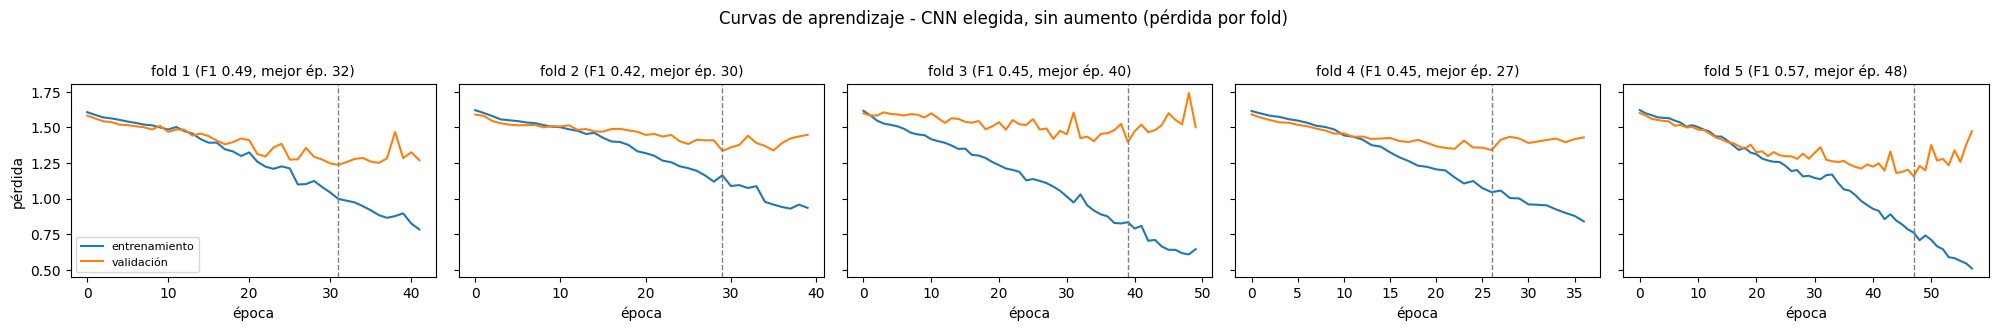

In [18]:
# ==========================================
# 9.4 PRUEBAS PAREADAS ENTRE CONFIGURACIONES (mismos folds) + CURVAS DE LA CNN ELEGIDA
# ==========================================
from scipy import stats

def comparar_pareado(a, b):
    """Compara dos configuraciones fold a fold (F1): diferencias, media, folds ganados y
    prueba t pareada. Como los folds comparten datos de entrenamiento, el p-valor es solo orientativo."""
    d = RES[a][0]["f1"].values - RES[b][0]["f1"].values
    t, p = stats.ttest_rel(RES[a][0]["f1"].values, RES[b][0]["f1"].values)
    return dict(comparacion=f"{a} vs {b}", dif_por_fold=" ".join(f"{x:+.3f}" for x in d),
                dif_media=round(d.mean(), 3), folds_ganados=f"{(d > 0).sum()}/{len(d)}",
                t=round(t, 2), p_valor=round(p, 3))

pares = [("CNN_sin_aumento", "CNN_base"), ("CNN_lr2e-3", "CNN_base"),
         ("MLP_lr1e-3", "MLP_base"), ("MLP_sin_aumento", "MLP_base"),
         (ELEGIDA_CNN, ELEGIDA_MLP)]
print(pd.DataFrame([comparar_pareado(a, b) for a, b in pares]).to_string(index=False))

graficar_curvas("CNN_sin_aumento", "Curvas de aprendizaje - CNN elegida, sin aumento (pérdida por fold)")

### Interpretación de las pruebas pareadas y de las curvas de la CNN elegida

**Cómo leer la tabla.** Cada fila compara dos configuraciones fold a fold, con los mismos folds. Se muestra la diferencia de F1 en cada fold, su media, en cuántos folds gana la primera configuración, y una prueba t pareada. El p-valor se interpreta solo como una referencia: con 5 folds hay muy pocos datos y los folds comparten imágenes de entrenamiento entre sí, por lo que no son independientes y el p-valor tiende a ser optimista.

**Resultados.**
- *CNN sin aumento vs CNN base:* diferencia media de +0,089 en F1, a favor en 5 de 5 folds (t = 2,18; p = 0,094).
- *CNN lr 2e-3 vs CNN base:* +0,016, a favor en 4 de 5 folds (p = 0,460). La diferencia es pequeña y no se distingue del ruido.
- *MLP lr 1e-3 vs MLP base:* +0,020, a favor en 4 de 5 folds (p = 0,104).
- *MLP sin aumento vs MLP base:* −0,028, a favor solo en 1 de 5 folds (p = 0,332). Quitar el aumento no ayuda a la MLP, pero tampoco se puede afirmar que la perjudique de forma sistemática.
- *CNN elegida vs MLP elegida:* +0,068, a favor de la CNN en 4 de 5 folds (t = 2,36; p = 0,078). El fold 2 es el único en contra (−0,021).

**Conclusión de las pruebas.** Ninguna comparación alcanza p < 0,05. Las dos más claras (la CNN sin aumento frente a su base, y la CNN elegida frente a la MLP elegida) tienen p entre 0,07 y 0,10 y una dirección consistente (5/5 y 4/5 folds), por lo que hay una **tendencia a favor de la CNN optimizada, pero no evidencia concluyente**. Esta tendencia se verifica en el conjunto de prueba, que ningún paso de la selección ha visto.

**Curvas de aprendizaje de la CNN sin aumento** (valores leídos del gráfico, aproximados). En los cinco folds, la pérdida de entrenamiento baja de forma sostenida hasta cerca de 0,5 a 0,8 sin estancarse, mientras que la de validación deja de bajar alrededor de 1,2 a 1,45 y luego oscila o sube. La brecha entre ambas es amplia: la red se sobreajusta con claridad, y es más visible que en la CNN base. Early Stopping elige la época de menor pérdida de validación (entre la 27 y la 48 según el fold), antes de que la validación empeore, por lo que es lo que impide que ese sobreajuste dañe el modelo final.

**Un resultado que parece contradictorio.** Sin aumento, la brecha entre pérdidas aumenta, pero el F1 mejora. La brecha mide cuánto más ajustada está la red a los datos de entrenamiento que a los de validación, y no cuánto acierta en validación. Aquí el aumento parece estar dificultando que la red aprenda las razas, no regularizándola de forma útil (hipótesis ya señalada en la búsqueda). La pérdida de validación mínima de cada fold, en torno a 1,2–1,4, sigue alejada de 0, lo que es consistente con un F1 de 0,475: el modelo acierta menos de la mitad de las veces.

**Impacto de cada técnica de regularización (resumen de la búsqueda).**
| Técnica | MLP | CNN |
|---|---|---|
| Aumento de datos | Ayuda: sin aumento, F1 −0,028 | Perjudica: sin aumento, F1 +0,089 |
| Dropout | Valor intermedio (0,3) rinde mejor, efecto modesto | Sin evidencia de efecto en el rango probado |
| Early Stopping | Efecto marginal en F1 (0,448 con ES contra 0,432 sin ES en un fold); la pérdida de validación queda plana y ES ahorra ~47 s (sección 9.6) | Útil: sin ES la pérdida de validación sube de 1,24 (época 32) a 1,72 al final; el F1 del fold es parecido (0,485 contra 0,477) (sección 9.6) |


### 9.5 Curvas de aprendizaje: impacto de cada técnica y de las configuraciones finales

La rúbrica pide analizar el impacto de cada técnica de regularización con curvas de aprendizaje. Los historiales de entrenamiento de todas las configuraciones ya se guardaron, así que no hace falta reentrenar: se grafica la **pérdida media por época sobre los 5 folds** para cada factor (aumento de datos, dropout y learning rate), en la MLP y en la CNN. La línea continua es la pérdida de validación y la punteada la de entrenamiento; la línea gris es el nivel del azar (ln 5 ≈ 1,61). Solo se grafican las épocas en que al menos 3 folds seguían entrenando, porque Early Stopping corta cada fold en una época distinta.

Una cautela al leer las curvas: la pérdida de entrenamiento se mide con el aumento de datos y el dropout activos, por lo que no es comparable de forma exacta con la de validación ni entre configuraciones que difieren en esas técnicas.

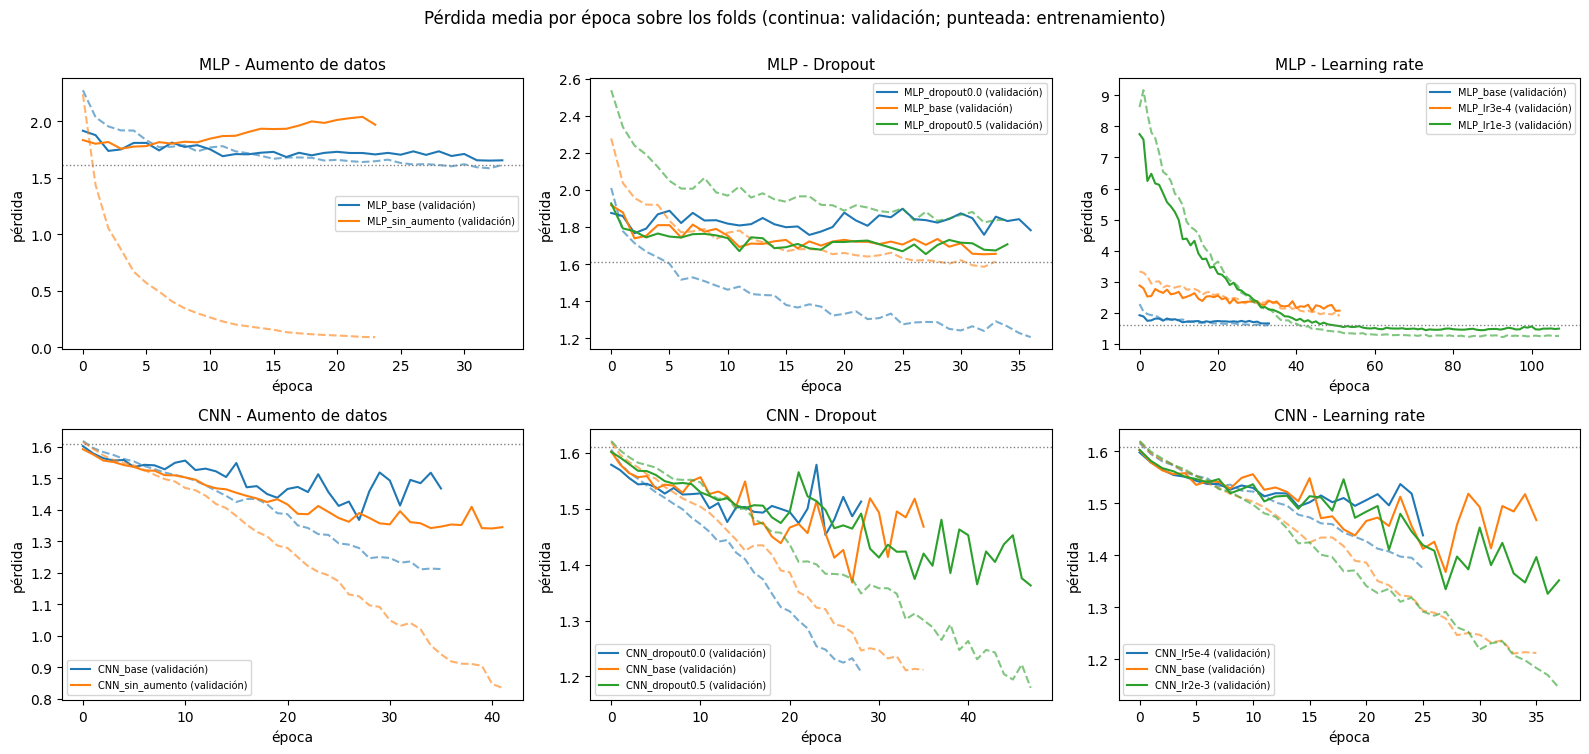

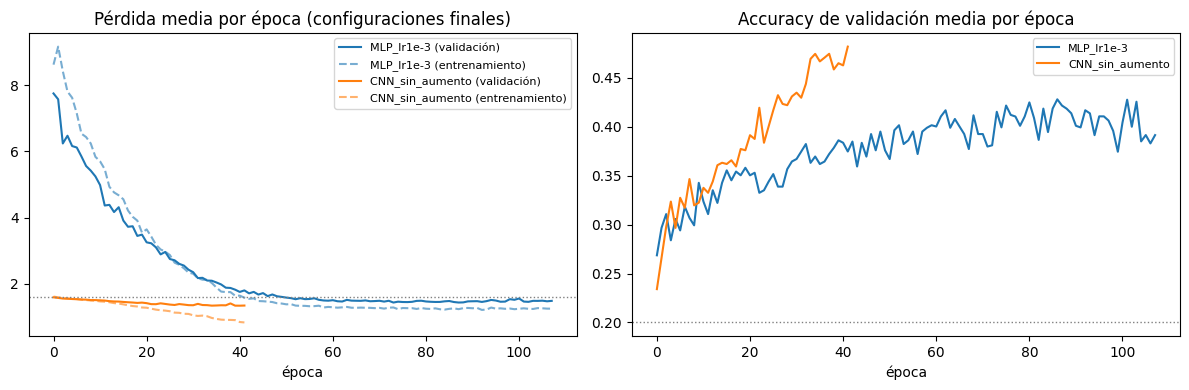

         config  loss_entrenamiento  loss_validacion  acc_entrenamiento  acc_validacion
       MLP_base               1.727            1.581              0.391           0.395
     MLP_lr3e-4               2.240            1.937              0.401           0.394
     MLP_lr1e-3               1.250            1.411              0.501           0.412
 MLP_neuronas64               1.597            1.550              0.384           0.364
MLP_neuronas256               1.769            1.742              0.425           0.395
 MLP_dropout0.0               1.464            1.662              0.454           0.370
 MLP_dropout0.5               1.945            1.563              0.341           0.378
MLP_sin_aumento               0.876            1.736              0.688           0.361
       CNN_base               1.312            1.376              0.435           0.407
     CNN_lr5e-4               1.376            1.414              0.403           0.384
     CNN_lr2e-3               1.

In [19]:
# ==========================================
# 9.5 CURVAS DE APRENDIZAJE POR TÉCNICA Y DE LAS CONFIGURACIONES FINALES
# ==========================================
def curva_media(nombre, clave, min_folds=3):
    """Promedio por época de una curva (p. ej. 'val_loss') sobre los folds de una configuración.
    Solo se conservan las épocas en que al menos min_folds folds seguían entrenando."""
    hist = RES[nombre][1]
    largo = max(len(h[clave]) for h in hist)
    M = np.full((len(hist), largo), np.nan)
    for i, h in enumerate(hist):
        M[i, :len(h[clave])] = h[clave]
    activos = (~np.isnan(M)).sum(axis=0) >= min_folds
    return np.nanmean(M, axis=0)[activos]

GRUPOS = {
    "MLP": {"Aumento de datos": ["MLP_base", "MLP_sin_aumento"],
            "Dropout": ["MLP_dropout0.0", "MLP_base", "MLP_dropout0.5"],
            "Learning rate": ["MLP_base", "MLP_lr3e-4", "MLP_lr1e-3"]},
    "CNN": {"Aumento de datos": ["CNN_base", "CNN_sin_aumento"],
            "Dropout": ["CNN_dropout0.0", "CNN_base", "CNN_dropout0.5"],
            "Learning rate": ["CNN_lr5e-4", "CNN_base", "CNN_lr2e-3"]},
}

fig, ejes = plt.subplots(2, 3, figsize=(16, 7.5))
for i, (modelo, factores) in enumerate(GRUPOS.items()):
    for j, (factor, nombres) in enumerate(factores.items()):
        ax = ejes[i, j]
        for k, n in enumerate(nombres):
            ax.plot(curva_media(n, "val_loss"), color=f"C{k}", label=f"{n} (validación)")
            ax.plot(curva_media(n, "loss"), color=f"C{k}", linestyle="--", alpha=0.6)
        ax.axhline(np.log(N_CLASES), color="gray", linestyle=":", linewidth=1)
        ax.set_title(f"{modelo} - {factor}", fontsize=11)
        ax.set_xlabel("época"); ax.set_ylabel("pérdida"); ax.legend(fontsize=7)
plt.suptitle("Pérdida media por época sobre los folds (continua: validación; punteada: entrenamiento)", y=1.0)
plt.tight_layout(); guardar_fig("10_curvas_por_tecnica"); plt.show()

# --- Curvas de las configuraciones finales: pérdida y accuracy de validación ---
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for k, n in enumerate([ELEGIDA_MLP, ELEGIDA_CNN]):
    ejes[0].plot(curva_media(n, "val_loss"), color=f"C{k}", label=f"{n} (validación)")
    ejes[0].plot(curva_media(n, "loss"), color=f"C{k}", linestyle="--", alpha=0.6, label=f"{n} (entrenamiento)")
    ejes[1].plot(curva_media(n, "val_accuracy"), color=f"C{k}", label=n)
ejes[0].axhline(np.log(N_CLASES), color="gray", linestyle=":", linewidth=1)
ejes[0].set_title("Pérdida media por época (configuraciones finales)"); ejes[0].set_xlabel("época"); ejes[0].legend(fontsize=8)
ejes[1].axhline(1 / N_CLASES, color="gray", linestyle=":", linewidth=1)
ejes[1].set_title("Accuracy de validación media por época"); ejes[1].set_xlabel("época"); ejes[1].legend(fontsize=8)
plt.tight_layout(); guardar_fig("11_curvas_modelos_finales"); plt.show()

# --- Brecha entrenamiento-validación en la época elegida por Early Stopping (media de folds) ---
def brecha(nombre):
    """Pérdida y accuracy de entrenamiento y validación en la época elegida por Early Stopping (media de los folds)."""
    filas = []
    for h in RES[nombre][1]:
        b = int(np.argmin(h["val_loss"]))
        filas.append((h["loss"][b], h["val_loss"][b], h["accuracy"][b], h["val_accuracy"][b]))
    a = np.mean(filas, axis=0)
    return dict(config=nombre, loss_entrenamiento=round(a[0], 3), loss_validacion=round(a[1], 3),
                acc_entrenamiento=round(a[2], 3), acc_validacion=round(a[3], 3))

print(pd.DataFrame([brecha(n) for n in nombres_mlp + nombres_cnn]).to_string(index=False))

### Interpretación de las curvas por técnica y de la brecha entrenamiento-validación

Los valores de pérdida se leen de la figura, por lo que son aproximados; los de accuracy vienen de la tabla de brecha.

**Aumento de datos.** En la MLP es la técnica con el efecto más visible. Sin aumento, la pérdida de entrenamiento cae hasta cerca de 0,1 mientras la de validación sube de ~1,8 a ~2,0: sobreajuste extremo. Con aumento, entrenamiento y validación se mantienen cerca de 1,6 a 1,7 (el azar da 1,61). La tabla de brecha lo confirma: sin aumento la accuracy de entrenamiento es 0,688 y la de validación 0,361 (brecha de 0,33); con aumento son 0,391 y 0,395. En la CNN pasa algo distinto: en la época elegida, sin aumento la pérdida de validación es menor (1,29 contra 1,38 de la base) aunque la de entrenamiento también baja más (0,96 contra 1,31), y la accuracy de entrenamiento y de validación es 0,606 y 0,480 (brecha de 0,13). Aquí el aumento no reduce el sobreajuste de forma útil, en línea con la hipótesis de la sección 9.3.

**Dropout.** En la MLP, sin dropout la pérdida de entrenamiento baja a ~1,2 mientras la de validación se queda cerca de 1,8 (accuracy 0,454 contra 0,370, brecha de 0,08); con 0,3 y 0,5 las curvas de entrenamiento y validación quedan juntas, cerca de 1,6 a 1,7. En la CNN las curvas de los tres valores se parecen y oscilan, sin un orden claro, lo que coincide con que no haya evidencia de efecto en el rango probado (sección 9.3).

**Learning rate.** En la MLP con lr 1e-3 la pérdida parte en ~8 a 9, muy por encima de ln 5 ≈ 1,61 (hipótesis no probada: pasos grandes sobre 12.288 entradas generan predicciones extremas al inicio). Después baja y se estabiliza hacia la época 60; en la época elegida su pérdida de validación es 1,41 contra 1,58 de la base, lo que es consistente con su mejor F1. Con 3e-4 la pérdida de validación en la mejor época queda más arriba (1,94). En la CNN, lr 2e-3 alcanza la pérdida de validación más baja de las tres (~1,33 a 1,35) pero oscila; con 5e-4 el entrenamiento se detiene antes (~25 épocas).

**Brecha en la época elegida por Early Stopping.** Las mayores brechas de accuracy (entrenamiento menos validación) son `MLP_sin_aumento` (0,33), `CNN_sin_aumento` (0,13), `MLP_lr1e-3` (0,09) y `MLP_dropout0.0` (0,08); el resto queda en 0,04 o menos. Una brecha alta no implica peor validación: `CNN_sin_aumento` tiene la mayor brecha de la CNN y también la mejor accuracy de validación (0,480), y la MLP elegida (`MLP_lr1e-3`) tiene una brecha de 0,09 junto con la mejor validación de la MLP (0,412).

**Cautelas.** La pérdida y la accuracy de entrenamiento se miden con aumento y dropout activos, por lo que subestiman la brecha real y no son comparables entre configuraciones que difieren en esas técnicas. Las curvas medias incluyen solo las épocas en que al menos 3 folds seguían entrenando.

### 9.6 Efecto de Early Stopping: entrenar con y sin parada

Early Stopping detiene el entrenamiento cuando la pérdida de validación deja de mejorar y recupera los pesos de la mejor época. Es como dejar de estudiar cuando los simulacros dejan de mejorar, en vez de seguir hasta el día del examen. Para medir su efecto se entrena un fold (el fold 1, con la semilla 101) de cada modelo elegido **sin Early Stopping**, hasta el tope de épocas, y se compara con el mismo entrenamiento **con** Early Stopping, que ya se ejecutó en la validación cruzada. Como la semilla y los datos son los mismos, las primeras épocas coinciden y la única diferencia es dónde se detiene el entrenamiento. Es un solo fold y una sola semilla, así que es una ilustración y no una estimación general.

config                      MLP_lr1e-3  CNN_sin_aumento
epocas_con_ES                      113               42
epoca_elegida_ES                    93               32
F1_con_ES                        0.448            0.485
seg_con_ES                         164              339
epocas_sin_ES                      150               60
epoca_menor_perdida_sin_ES          93               32
F1_sin_ES                        0.432            0.477
seg_sin_ES                         211              496
perdida_val_minima                1.37            1.236
perdida_val_final                1.479            1.724


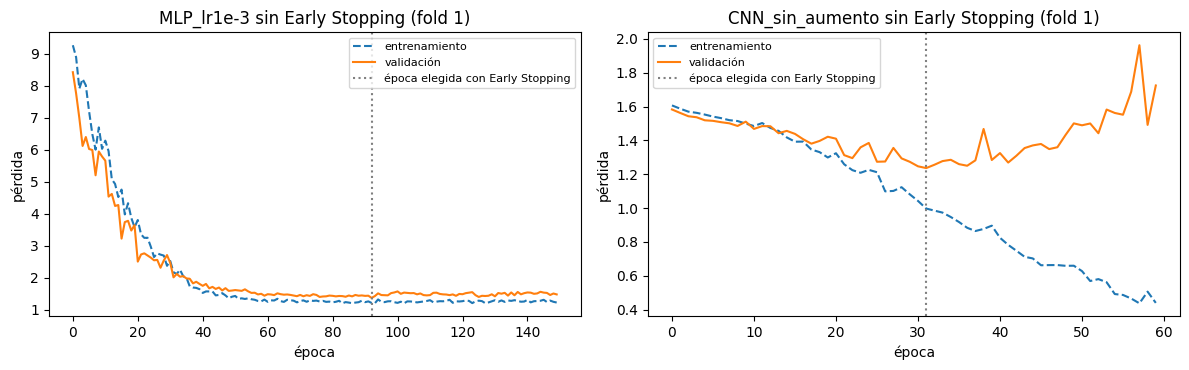

In [20]:
# ==========================================
# 9.6 EFECTO DE EARLY STOPPING: UN FOLD CON Y SIN PARADA (~20 min en CPU)
# ==========================================
def entrenar_sin_es(tipo, params, idx_fold=0, seed=SEEDS_FINAL[0]):
    """Entrena un fold hasta el tope de épocas, SIN Early Stopping. Devuelve métricas en la última época,
    el historial y los segundos usados."""
    idx_tr, idx_va = folds[idx_fold]
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    m = CONSTRUCTORES[tipo](X_adapt=X_dev[idx_tr], **params)
    t0 = time.time()
    h = m.fit(X_dev[idx_tr], y_dev[idx_tr], validation_data=(X_dev[idx_va], y_dev[idx_va]),
              epochs=TRAIN_CFG[tipo]["epocas_max"], batch_size=BATCH, verbose=0)
    seg = time.time() - t0
    pred = m.predict(X_dev[idx_va], verbose=0).argmax(axis=1)
    return metricas(y_dev[idx_va], pred), h.history, seg

filas, HIST_SIN_ES = [], {}
for tipo, nombre, busqueda in [("mlp", ELEGIDA_MLP, BUSQUEDA_MLP), ("cnn", ELEGIDA_CNN, BUSQUEDA_CNN)]:
    params = {**PARAMS_BASE[tipo], **busqueda.get(nombre, {})}
    met, hist, seg = entrenar_sin_es(tipo, params)
    HIST_SIN_ES[nombre] = hist
    con = RES[nombre][0].loc[1]                       # mismo fold, misma semilla, con Early Stopping
    filas.append(dict(config=nombre,
                      epocas_con_ES=int(con["epocas_totales"]), epoca_elegida_ES=int(con["epoca_mejor"]),
                      F1_con_ES=round(con["f1"], 3), seg_con_ES=round(con["segundos"]),
                      epocas_sin_ES=len(hist["loss"]), epoca_menor_perdida_sin_ES=int(np.argmin(hist["val_loss"])) + 1,
                      F1_sin_ES=round(met["f1"], 3), seg_sin_ES=round(seg),
                      perdida_val_minima=round(min(hist["val_loss"]), 3), perdida_val_final=round(hist["val_loss"][-1], 3)))
print(pd.DataFrame(filas).T.to_string(header=False))

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nombre, hist) in zip(ejes, HIST_SIN_ES.items()):
    ax.plot(hist["loss"], "--", color="C0", label="entrenamiento")
    ax.plot(hist["val_loss"], color="C1", label="validación")
    ax.axvline(int(RES[nombre][0].loc[1, "epoca_mejor"]) - 1, color="gray", linestyle=":", label="época elegida con Early Stopping")
    ax.set_title(f"{nombre} sin Early Stopping (fold 1)"); ax.set_xlabel("época"); ax.set_ylabel("pérdida"); ax.legend(fontsize=8)
plt.tight_layout(); guardar_fig("12_early_stopping"); plt.show()


### Interpretación del efecto de Early Stopping

| | MLP (`MLP_lr1e-3`) | CNN (`CNN_sin_aumento`) |
|---|---|---|
| Épocas con ES / sin ES | 113 / 150 | 42 / 60 |
| Época elegida por ES | 93 | 32 |
| F1 del fold con ES / sin ES | 0,448 / 0,432 | 0,485 / 0,477 |
| Segundos con ES / sin ES | 164 / 211 | 339 / 496 |
| Pérdida de validación: mínima / final sin ES | 1,37 / 1,48 | 1,24 / 1,72 |

**CNN.** Sin Early Stopping la pérdida de validación sube de 1,24 (época 32) a 1,72 al final mientras la de entrenamiento sigue bajando: la red memoriza. Early Stopping evita ese deterioro y ahorra unos 157 s (32% del tiempo). El F1 del fold casi no cambia (0,485 contra 0,477): la diferencia de 0,008 es del tamaño del ruido.

**MLP.** La pérdida de validación queda plana (entre ~1,4 y ~1,5) desde la época 60 hasta la 150, así que seguir entrenando no la daña. Early Stopping mejora el F1 del fold en 0,016 y ahorra unos 47 s (22% del tiempo): efecto marginal.

**Lectura.** Early Stopping es útil sobre todo en la CNN, donde la validación sí empeora al seguir entrenando, y en la MLP actúa más bien como ahorro de cómputo. Esto corrige la lectura previa de que fuera esencial en ambos modelos.

**Cautela.** Es un solo fold y una sola semilla, una ilustración y no una estimación general. Además, con Early Stopping la elección de la mejor época usa la validación del fold, por lo que su F1 es levemente optimista.


## 9.7 Experimento controlado: arquitecturas y regularización

Esta comparación se ejecutó antes de la evaluación final de test. Incluye seis configuraciones con cinco folds: MLP y CNN base, cada una con L2 y con Batch Normalization. Se mantuvieron comunes la semilla 101, tamaño de lote, aumento de datos, learning rate, Dropout y presupuesto de **60 épocas como máximo / paciencia 10**. La comparación estima el efecto en estas configuraciones controladas; no es una búsqueda exhaustiva de los mejores hiperparámetros.

L2 y Batch Normalization se evaluaron por separado, una técnica a la vez. La normalización de entrada se adaptó solo con los datos de entrenamiento de cada fold. El experimento usó `X_dev` y `y_dev`, sin consultar `X_test` ni `y_test`; por tanto, sus resultados no cambian la selección final hecha antes de abrir el test.

El código guardó el detalle fold a fold en un CSV local reanudable y completó los 30 ajustes. La tabla e interpretación que siguen informan media y desviación estándar entre folds. No se guardaron los historiales de entrenamiento de estas seis configuraciones, por lo que no hay curvas de aprendizaje para L2 y Batch Normalization; su análisis se basa en las métricas por fold. Dado que hay cinco folds correlacionados y una sola semilla, la evidencia es exploratoria.


In [21]:
# ==========================================
# EXPERIMENTO CONTROLADO: MLP/CNN, L2 Y BATCH NORMALIZATION
# Solo validación cruzada en X_dev; el test final no se usa aquí.
# ==========================================
import time
from tensorflow.keras import regularizers

EXP_EPOCHS = 60
EXP_PATIENCE = 10
EXP_SEED = int(SEEDS_FINAL[0])
EXP_BATCH = BATCH
EXP_FINGERPRINT = "ep3-exp-reg-v1-60ep-p10-5fold-seed101"
EXP_CSV = Path("resultados") / "experimentos_regularizacion_folds.csv"
EXP_CSV.parent.mkdir(parents=True, exist_ok=True)

# El mismo protocolo de entrada evita leakage: adapt() ve solo el fold de entrenamiento.
def _exp_input(x_train, augmentation=True):
    """Construye el preprocesamiento y adapta normalización solo al fold de entrenamiento.

    Args:
        x_train: Imágenes del fold de entrenamiento usadas por adapt().
        augmentation: Si es True, incluye transformaciones aleatorias de entrenamiento.
    Returns:
        Lista de capas Keras lista para incorporarse al modelo.
    """
    seq = [layers.Input(shape=(RES_BASE, RES_BASE, 3))]
    if augmentation:
        seq += [layers.RandomFlip("horizontal"), layers.RandomRotation(0.055),
                layers.RandomTranslation(0.1, 0.1)]
    seq += [layers.Rescaling(1 / 255)]
    norm = layers.Normalization(axis=-1)
    norm.adapt(x_train.astype("float32") / 255.0)
    seq += [norm]
    return seq

def _exp_build(kind, x_train, l2_value=0.0, batch_norm=False):
    """Construye y compila una MLP o CNN del experimento de regularización.

    Args:
        kind: Arquitectura, "mlp" o "cnn".
        x_train: Imágenes del fold de entrenamiento para adaptar la normalización.
        l2_value: Coeficiente L2; 0 desactiva esta regularización.
        batch_norm: Si es True, añade Batch Normalization a las capas ocultas.
    Returns:
        Modelo Keras compilado con Adam y entropía cruzada categórica dispersa.
    """
    reg = regularizers.l2(l2_value) if l2_value else None
    seq = _exp_input(x_train, augmentation=True)
    if kind == "mlp":
        seq += [layers.Flatten(),
                layers.Dense(128, kernel_regularizer=reg, use_bias=not batch_norm)]
        if batch_norm:
            seq += [layers.BatchNormalization()]
        seq += [layers.Activation("relu"), layers.Dropout(0.3),
                layers.Dense(N_CLASES, activation="softmax")]
    elif kind == "cnn":
        for j, filters in enumerate((32, 64, 128), start=1):
            seq += [layers.Conv2D(filters, 3, padding="same", kernel_regularizer=reg,
                                  use_bias=not batch_norm, name=f"exp_conv{j}")]
            if batch_norm:
                seq += [layers.BatchNormalization(name=f"exp_bn{j}")]
            seq += [layers.Activation("relu"), layers.MaxPooling2D(2)]
        seq += [layers.GlobalAveragePooling2D(),
                layers.Dense(64, kernel_regularizer=reg, use_bias=not batch_norm)]
        if batch_norm:
            seq += [layers.BatchNormalization()]
        seq += [layers.Activation("relu"), layers.Dropout(0.3),
                layers.Dense(N_CLASES, activation="softmax")]
    else:
        raise ValueError(f"Arquitectura desconocida: {kind}")
    model = models.Sequential(seq)
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

EXP_CONFIGS = [
    {"config": "MLP_base_control", "tipo": "mlp", "l2": 0.0, "batch_norm": False},
    {"config": "MLP_L2",           "tipo": "mlp", "l2": 1e-4, "batch_norm": False},
    {"config": "MLP_BatchNorm",    "tipo": "mlp", "l2": 0.0, "batch_norm": True},
    {"config": "CNN_base_control", "tipo": "cnn", "l2": 0.0, "batch_norm": False},
    {"config": "CNN_L2",           "tipo": "cnn", "l2": 1e-4, "batch_norm": False},
    {"config": "CNN_BatchNorm",    "tipo": "cnn", "l2": 0.0, "batch_norm": True},
]

# Recuperar solo filas creadas con este protocolo; el CSV principal/checkpoint no se toca.
if EXP_CSV.exists():
    _exp_old = pd.read_csv(EXP_CSV)
    if "fingerprint" in _exp_old.columns:
        _exp_rows = _exp_old[_exp_old["fingerprint"] == EXP_FINGERPRINT].to_dict("records")
    else:
        _exp_rows = []
else:
    _exp_rows = []
_exp_done = {(r["config"], int(r["fold"])) for r in _exp_rows}

for spec in EXP_CONFIGS:
    for fold_num, (idx_tr, idx_va) in enumerate(folds, start=1):
        if (spec["config"], fold_num) in _exp_done:
            print(f"{spec['config']} | fold {fold_num}: recuperado del CSV")
            continue
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(EXP_SEED)
        model = _exp_build(spec["tipo"], X_dev[idx_tr], spec["l2"], spec["batch_norm"])
        callback = EarlyStopping(monitor="val_loss", patience=EXP_PATIENCE,
                                 restore_best_weights=True)
        started = time.time()
        history = model.fit(X_dev[idx_tr], y_dev[idx_tr],
                            validation_data=(X_dev[idx_va], y_dev[idx_va]),
                            epochs=EXP_EPOCHS, batch_size=EXP_BATCH,
                            callbacks=[callback], verbose=0)
        elapsed = time.time() - started
        pred = model.predict(X_dev[idx_va], verbose=0).argmax(axis=1)
        row = {"fingerprint": EXP_FINGERPRINT, "config": spec["config"],
               "tipo": spec["tipo"], "l2": spec["l2"],
               "batch_norm": spec["batch_norm"], "fold": fold_num,
               **metricas(y_dev[idx_va], pred),
               "epocas": len(history.history["loss"]),
               "epoca_mejor_val_loss": int(np.argmin(history.history["val_loss"])) + 1,
               "segundos": round(elapsed, 2), "parametros": model.count_params()}
        pd.DataFrame([row]).to_csv(EXP_CSV, mode="a", header=not EXP_CSV.exists(), index=False)
        _exp_rows.append(row)
        _exp_done.add((spec["config"], fold_num))
        print(f"{spec['config']} | fold {fold_num}/5 | F1 {row['f1']:.3f} | "
              f"recall mínimo {row['recall_min']:.3f} | {elapsed:.0f} s")
        del model

exp_folds = pd.DataFrame(_exp_rows)
exp_folds = exp_folds[exp_folds["fingerprint"] == EXP_FINGERPRINT].copy()
exp_summary = (exp_folds.groupby(["config", "tipo", "l2", "batch_norm"], as_index=False)
               .agg(f1_media=("f1", "mean"), f1_sd=("f1", "std"),
                    acc_media=("acc", "mean"), recall_min_media=("recall_min", "mean"),
                    segundos_totales=("segundos", "sum"),
                    parametros=("parametros", "first"), folds_completados=("fold", "count")))
print("\nResumen exploratorio (media ± desviación estándar entre folds):")
print(exp_summary.to_string(index=False, formatters={
    "f1_media": "{:.3f}".format, "f1_sd": "{:.3f}".format,
    "acc_media": "{:.3f}".format, "recall_min_media": "{:.3f}".format}))
print(f"\nDetalle guardado en: {EXP_CSV}")


MLP_base_control | fold 1/5 | F1 0.389 | recall mínimo 0.323 | 86 s
MLP_base_control | fold 2/5 | F1 0.436 | recall mínimo 0.290 | 87 s
MLP_base_control | fold 3/5 | F1 0.356 | recall mínimo 0.226 | 86 s
MLP_base_control | fold 4/5 | F1 0.382 | recall mínimo 0.290 | 89 s
MLP_base_control | fold 5/5 | F1 0.385 | recall mínimo 0.129 | 88 s
MLP_L2 | fold 1/5 | F1 0.385 | recall mínimo 0.281 | 91 s
MLP_L2 | fold 2/5 | F1 0.446 | recall mínimo 0.355 | 87 s
MLP_L2 | fold 3/5 | F1 0.373 | recall mínimo 0.258 | 90 s
MLP_L2 | fold 4/5 | F1 0.395 | recall mínimo 0.290 | 88 s
MLP_L2 | fold 5/5 | F1 0.418 | recall mínimo 0.194 | 89 s
MLP_BatchNorm | fold 1/5 | F1 0.421 | recall mínimo 0.323 | 46 s
MLP_BatchNorm | fold 2/5 | F1 0.441 | recall mínimo 0.281 | 35 s
MLP_BatchNorm | fold 3/5 | F1 0.345 | recall mínimo 0.258 | 75 s
MLP_BatchNorm | fold 4/5 | F1 0.391 | recall mínimo 0.312 | 73 s
MLP_BatchNorm | fold 5/5 | F1 0.467 | recall mínimo 0.323 | 86 s
CNN_base_control | fold 1/5 | F1 0.467 | reca

### Resultados e interpretación del experimento 9.7

| Arquitectura/configuración | F1 macro medio ± DE | Accuracy media | Recall mínimo medio |
|---|---:|---:|---:|
| MLP base control | 0,390 ± 0,029 | 0,394 | 0,252 |
| MLP + L2 (`1e-4`) | 0,403 ± 0,029 | 0,407 | 0,276 |
| MLP + Batch Normalization | 0,413 ± 0,047 | 0,414 | 0,299 |
| CNN base control | 0,386 ± 0,079 | 0,407 | 0,185 |
| CNN + L2 (`1e-4`) | 0,395 ± 0,085 | 0,424 | 0,133 |
| CNN + Batch Normalization | 0,294 ± 0,156 | 0,341 | 0,146 |

**Lectura.** Bajo el presupuesto común, los controles base tienen resultados de F1 parecidos (MLP 0,390; CNN 0,386), de modo que esta prueba no muestra una ventaja clara de arquitectura en condiciones equiparadas. L2 elevó el F1 medio en 0,013 para la MLP y 0,009 para la CNN; esos cambios son pequeños frente a la incertidumbre entre folds. Batch Normalization elevó el F1 medio de la MLP en 0,023, pero lo redujo en 0,092 en la CNN y produjo una desviación entre folds alta (0,156). Su efecto depende de la arquitectura y esta corrida no permite concluir que sea beneficiosa en general.

Estos promedios no se usaron para reemplazar la MLP/CNN seleccionadas ni para tocar el test. Como el estudio usa una semilla y folds correlacionados, los cambios son descriptivos: conviene repetirlos con más semillas y, si se exploran otras intensidades de L2, incluir esa búsqueda dentro del protocolo de validación.


## 10. Etapa de evaluación final en el conjunto de prueba

Las dos configuraciones elegidas por la búsqueda (`MLP_lr1e-3` y `CNN_sin_aumento`) se evalúan **una sola vez** en el conjunto de prueba, que ningún paso del pipeline ha usado. Es el examen final: se rinde una vez, con lo que ya se decidió, y no se vuelve atrás a cambiar el modelo según la nota.

**Protocolo.** Se reutiliza el de la EP1 y la EP2: entrenamiento con el 70% de los datos (644 imágenes), 15% de validación solo para Early Stopping, y evaluación en el 15% de prueba (138 imágenes). Cada modelo se entrena con **5 semillas distintas** (101 a 105) y se reporta la media ± desviación estándar en prueba. Así se mide también cuánto cambia el resultado según la inicialización de los pesos, que es una fuente de variabilidad distinta de la de los folds.

**Métricas.** Accuracy, Precision, Recall, F1 macro, recall mínimo entre razas y ROC-AUC (macro, uno contra el resto), que usa las probabilidades del modelo y no solo su clase predicha. Las predicciones y probabilidades se guardan para la auditoría, la matriz de confusión, la comparación estadística y la explicabilidad.

In [22]:
# ==========================================
# 10.1 EVALUACIÓN FINAL EN TEST: MLP ELEGIDA (5 semillas, ~11 min; retoma desde el checkpoint)
# ==========================================
from sklearn.metrics import roc_auc_score

N_TR = int(round(N_POR_CLASE * N_CLASES * 0.70))       # 644: entrenamiento original de EP1/EP2
assert N_TR == 644 and len(X_dev) - N_TR == 138
Path(RESPALDO, "models").mkdir(parents=True, exist_ok=True)

def evaluacion_final(nombre_config, tipo, params, semillas=SEEDS_FINAL):
    """Entrena con el 70% (Early Stopping sobre el 15% de validación) y evalúa en test, una vez por semilla.
    Guarda probabilidades, métricas y el modelo de cada semilla. Si una semilla ya está en el checkpoint,
    no se reentrena."""
    idx_tr, idx_va = np.arange(N_TR), np.arange(N_TR, len(X_dev))
    cfg = TRAIN_CFG[tipo]
    for s in semillas:
        if (nombre_config, s) in PROBS_TEST:
            fila = next(r for r in FILAS_TEST if r["config"] == nombre_config and r["semilla"] == s)
            print(f"  semilla {s}: restaurada del checkpoint (F1 test {fila['f1']:.3f})")
            continue
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(s)
        m = CONSTRUCTORES[tipo](X_adapt=X_dev[idx_tr], **params)
        es = EarlyStopping(monitor="val_loss", patience=cfg["paciencia"], restore_best_weights=True)
        t0 = time.time()
        h = m.fit(X_dev[idx_tr], y_dev[idx_tr], validation_data=(X_dev[idx_va], y_dev[idx_va]),
                  epochs=cfg["epocas_max"], batch_size=BATCH, callbacks=[es], verbose=0)
        seg = time.time() - t0
        probs = m.predict(X_test, verbose=0)
        met = metricas(y_test, probs.argmax(axis=1))
        met["roc_auc"] = roc_auc_score(y_test, probs, multi_class="ovr", average="macro")
        PROBS_TEST[(nombre_config, s)] = probs
        FILAS_TEST.append(dict(config=nombre_config, semilla=s, **met, segundos=seg,
                               epoca_mejor=int(np.argmin(h.history["val_loss"])) + 1))
        ruta = f"models/{nombre_config}_s{s}.keras"
        m.save(ruta)
        shutil.copy(ruta, f"{RESPALDO}/models/")
        pd.DataFrame(FILAS_TEST).to_csv("resultados/test_final.csv", index=False)
        guardar_estado()
        print(f"  semilla {s}: F1 test {met['f1']:.3f} | acc {met['acc']:.3f} | AUC {met['roc_auc']:.3f} | {seg:.0f} s")

print("MLP elegida:", ELEGIDA_MLP)
evaluacion_final("MLP_final", "mlp", {**PARAMS_BASE["mlp"], **BUSQUEDA_MLP[ELEGIDA_MLP]})


MLP elegida: MLP_lr1e-3
  semilla 101: F1 test 0.394 | acc 0.391 | AUC 0.704 | 148 s
  semilla 102: F1 test 0.378 | acc 0.377 | AUC 0.716 | 130 s
  semilla 103: F1 test 0.365 | acc 0.370 | AUC 0.706 | 147 s
  semilla 104: F1 test 0.361 | acc 0.362 | AUC 0.673 | 101 s
  semilla 105: F1 test 0.381 | acc 0.391 | AUC 0.719 | 155 s


In [23]:
# ==========================================
# 10.2 EVALUACIÓN FINAL EN TEST: CNN ELEGIDA + TABLA (5 semillas, ~26 min)
# ==========================================
print("CNN elegida:", ELEGIDA_CNN)
evaluacion_final("CNN_final", "cnn", {**PARAMS_BASE["cnn"], **BUSQUEDA_CNN[ELEGIDA_CNN]})

df_test = pd.DataFrame(FILAS_TEST)
cols = ["acc", "precision", "recall", "f1", "recall_min", "roc_auc"]
tabla_test = pd.DataFrame({c: [f"{df_test[df_test.config == n][c].mean():.3f} ± {df_test[df_test.config == n][c].std():.3f}"
                               for n in ["MLP_final", "CNN_final"]] for c in cols},
                          index=["MLP_final", "CNN_final"])
tabla_test["segundos_medio"] = [round(df_test[df_test.config == n]["segundos"].mean()) for n in ["MLP_final", "CNN_final"]]
print(tabla_test.to_string())


CNN elegida: CNN_sin_aumento
  semilla 101: F1 test 0.457 | acc 0.457 | AUC 0.778 | 496 s
  semilla 102: F1 test 0.337 | acc 0.362 | AUC 0.732 | 231 s
  semilla 103: F1 test 0.383 | acc 0.377 | AUC 0.724 | 274 s
  semilla 104: F1 test 0.385 | acc 0.399 | AUC 0.746 | 304 s
  semilla 105: F1 test 0.320 | acc 0.333 | AUC 0.731 | 284 s
                     acc      precision         recall             f1     recall_min        roc_auc  segundos_medio
MLP_final  0.378 ± 0.013  0.386 ± 0.018  0.378 ± 0.012  0.376 ± 0.013  0.259 ± 0.045  0.704 ± 0.018             136
CNN_final  0.386 ± 0.046  0.397 ± 0.062  0.385 ± 0.046  0.376 ± 0.053  0.206 ± 0.075  0.742 ± 0.022             318


### Interpretación de la evaluación final en test

**Resultado.** En el conjunto de prueba (138 imágenes, 5 semillas), la MLP elegida obtiene F1 macro de 0,376 ± 0,013 y la CNN elegida 0,376 ± 0,053: **empatan en F1**. La accuracy es 0,378 ± 0,013 para la MLP y 0,386 ± 0,046 para la CNN. Ambas rinden aproximadamente el doble que el azar (accuracy de 0,20), pero siguen lejos de un clasificador confiable.

**Diferencias entre arquitecturas.**
- *ROC-AUC:* la CNN obtiene 0,742 ± 0,022 y la MLP 0,704 ± 0,018, con la CNN por encima en las 5 semillas (diferencia media de +0,039). Aunque no acierta más veces, la CNN asigna probabilidades que ordenan mejor las razas.
- *Estabilidad:* la desviación estándar del F1 entre semillas es 0,053 para la CNN y 0,013 para la MLP, unas 4 veces mayor. El F1 de la CNN va de 0,320 a 0,457 según la semilla; el de la MLP, de 0,361 a 0,394.
- *Recall mínimo:* la MLP obtiene 0,259 ± 0,045 y la CNN 0,206 ± 0,075. Con la CNN, al menos una raza queda peor reconocida.
- *Costo:* la CNN promedia 318 s por entrenamiento de test, unas 2,3 veces más que la MLP (136 s), aunque tiene unas 15 veces menos parámetros (101.836 contra 1.573.644).

**Comparación semilla a semilla (F1, CNN menos MLP):** +0,063, −0,041, +0,018, +0,024 y −0,061. La media es cercana a 0 y la CNN gana en 3 de 5 semillas.

**Contraste con la validación cruzada.** En validación cruzada la CNN elegida superaba a la MLP elegida (F1 0,475 contra 0,407, a favor en 4 de 5 folds) y se dejó como tendencia por verificar en test. En test **esa ventaja no se confirma en F1**. El F1 de la CNN cae de 0,475 a 0,376 (−0,099) y el de la MLP de 0,407 a 0,376 (−0,031). Posibles razones (hipótesis, no probadas): (1) se eligió la mejor de 6 configuraciones de la CNN sobre las mismas validaciones, por lo que el valor de validación cruzada es optimista; (2) la validación cruzada se corrió con una sola semilla (101), y esa semilla es la que mejor le fue a la CNN en test (0,457), mientras que con las otras cuatro el F1 queda entre 0,320 y 0,385. Esto sugiere que parte de la ventaja observada era variabilidad de la inicialización y no un efecto de la configuración.

**Cuánto confiar en estas diferencias.** El conjunto de prueba tiene 138 imágenes: una sola imagen mal clasificada mueve la accuracy en unos 0,7 puntos porcentuales, y el error estándar de una accuracy de 0,38 con 138 imágenes es de unos 0,04. Diferencias de ese tamaño o menores (como la de accuracy, 0,008, o la de F1, prácticamente 0) no se pueden distinguir del azar.

**Comparación con la EP1.** El F1 de prueba de la MLP de la EP1 en este subconjunto fue 0,363. La MLP optimizada obtiene 0,376: una mejora de 0,013 comparable a la desviación estándar entre semillas (0,013), por lo que no se puede afirmar que la optimización haya mejorado a la MLP en test.

**Conclusión provisional.** Con esta evidencia, ninguna arquitectura supera claramente a la otra en F1. La CNN ofrece mejor ordenamiento de probabilidades (AUC) y menos parámetros, pero es más inestable entre semillas, tiene peor recall mínimo y demora más en entrenar. La elección final se discute en las secciones de auditoría, explicabilidad y comparación, que incorporan la matriz de confusión, el análisis de sesgos y Grad-CAM.


## 11. Etapa de auditoría del modelo

### 11.1 Matriz de confusión y recall por raza

La matriz de confusión muestra, para cada raza real (filas), con qué raza la confundió el modelo (columnas). La diagonal indica los aciertos. Es como la libreta de correcciones de un examen: además de saber cuántas respuestas fueron incorrectas, muestra cuáles se confundieron con cuáles. Se suman las predicciones de las 5 semillas y cada fila se normaliza, de modo que cada celda es la proporción de imágenes de esa raza clasificadas como cada raza, y la diagonal es el recall por raza.

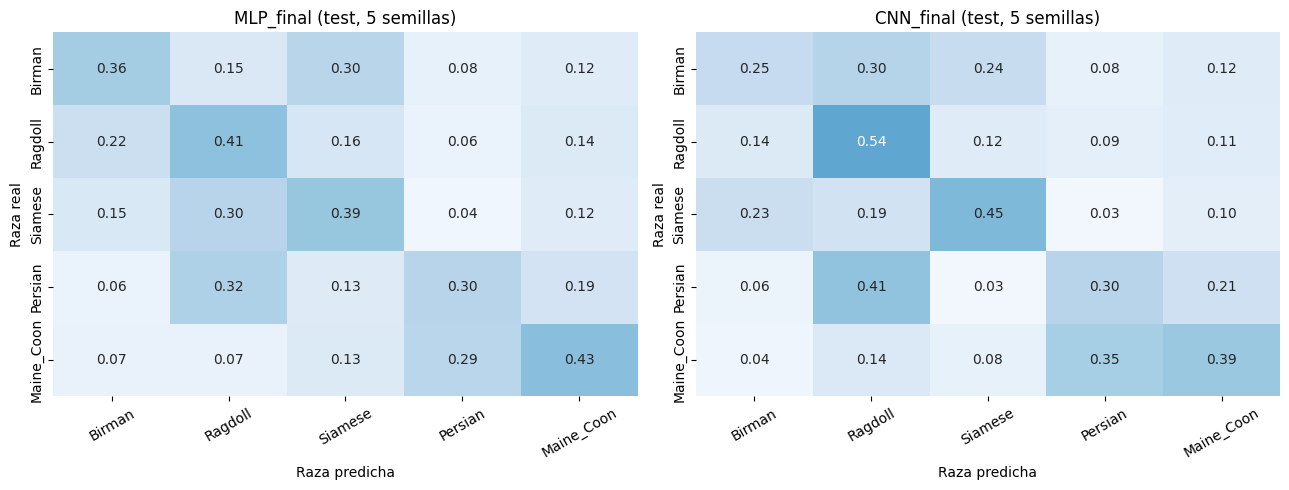

Recall por raza (test, 5 semillas agregadas):
            MLP_final  CNN_final
Birman          0.356      0.252
Ragdoll         0.414      0.536
Siamese         0.393      0.450
Persian         0.300      0.300
Maine_Coon      0.430      0.385


In [24]:
# ==========================================
# 11.1 MATRICES DE CONFUSIÓN (5 semillas agregadas, normalizadas por fila) Y RECALL POR RAZA
# ==========================================
def matriz_agregada(nombre):
    """Suma las matrices de confusión de las 5 semillas en el test."""
    return sum(confusion_matrix(y_test, PROBS_TEST[(nombre, s)].argmax(axis=1), labels=range(N_CLASES))
               for s in SEEDS_FINAL)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
recalls = {}
for ax, n in zip(ejes, ["MLP_final", "CNN_final"]):
    M = matriz_agregada(n)
    Mn = M / M.sum(axis=1, keepdims=True)
    recalls[n] = np.diag(Mn)
    sns.heatmap(Mn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=CLASES, yticklabels=CLASES, ax=ax)
    ax.set_title(f"{n} (test, 5 semillas)")
    ax.set_xlabel("Raza predicha"); ax.set_ylabel("Raza real")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); guardar_fig("07_matrices_confusion"); plt.show()

print("Recall por raza (test, 5 semillas agregadas):")
print(pd.DataFrame(recalls, index=CLASES).round(3).to_string())

### Interpretación de las matrices de confusión y del recall por raza

**Rendimiento por raza.** Ninguna raza se reconoce bien. En la MLP el recall por raza va de 0,300 (Persian) a 0,430 (Maine_Coon) y en la CNN de 0,252 (Birman) a 0,536 (Ragdoll). El promedio de los cinco recalls coincide con la accuracy de cada modelo (0,379 la MLP y 0,385 la CNN). Las dos arquitecturas aciertan en promedio lo mismo, pero **en razas distintas**: la CNN reconoce mejor Ragdoll (+0,12) y Siamese (+0,06), y peor Birman (−0,10) y Maine_Coon (−0,05); Persian queda igual (0,300). Una sola métrica global esconde estas diferencias.

**Confusión dentro del trío Birman, Ragdoll y Siamese.** Es el patrón más claro, y coincide con la similitud visual que se observó en el EDA (cuerpo claro con cara, orejas y patas oscuras). En la CNN, el 54% de las imágenes de Birman se clasifica como Ragdoll (0,30) o Siamese (0,24), y solo el 25% se acierta. En la MLP, Birman se confunde sobre todo con Siamese (0,30) y Siamese con Ragdoll (0,30).

**Persian y Maine_Coon se confunden entre sí.** Maine_Coon se clasifica como Persian en 0,29 de los casos en la MLP y 0,35 en la CNN, y Persian como Maine_Coon en 0,19 y 0,21. Las dos tienen pelaje largo y esponjoso. Esto matiza la impresión del EDA de que Persian se distingue como un grupo aparte: los modelos no la separan bien de Maine_Coon ni de Ragdoll (Persian se clasifica como Ragdoll en 0,32 con la MLP y en 0,41 con la CNN).

**Ragdoll funciona como clase "imán".** La columna de Ragdoll tiene valores altos en casi todas las filas. Como el test está casi balanceado, el promedio de esa columna es una estimación aproximada de qué porcentaje de las predicciones recibe Ragdoll: unos 32% con la CNN y 25% con la MLP, cuando a cada raza le corresponde 20%. Esto relativiza el recall de 0,536 de Ragdoll en la CNN: parte de ese acierto viene de que el modelo predice Ragdoll con demasiada frecuencia. La precisión aproximada de Ragdoll en la CNN es de solo ~0,34 (0,536 dividido por 1,58, la suma de la columna), y en la MLP ~0,33. Un recall alto por sí solo no basta: hay que mirarlo junto con la precisión.

**Recall mínimo: dos medidas distintas.** En la tabla de la evaluación final, el recall mínimo de la CNN fue 0,206 y el de la MLP 0,259: son el promedio, entre semillas, del recall de la peor raza de cada semilla. Aquí las predicciones de las 5 semillas están agrupadas, por lo que los mínimos son más altos (0,252 en la CNN con Birman y 0,300 en la MLP con Persian). Ambas medidas apuntan a lo mismo: la peor raza se reconoce en 1 de cada 4 o 5 imágenes.

**Cautela.** El conjunto de prueba tiene unas 27 o 28 imágenes por raza, y las 5 semillas evalúan las mismas imágenes, por lo que no aportan imágenes nuevas. Cada imagen mueve el recall de su raza en unos 3,6 puntos porcentuales, y diferencias de 0,05 a 0,12 equivalen a 1 a 3 imágenes. Por eso estos patrones se leen como descriptivos y no como diferencias demostradas entre arquitecturas.

**Implicancias.** Los errores se concentran en dos grupos (Birman, Ragdoll y Siamese por un lado; Persian y Maine_Coon por el otro), que son los que más se parecen entre sí. Resta ver si los modelos se apoyan en el animal o en el fondo y el color, lo que se revisa con explicabilidad en la siguiente sección.

### 11.2 Precisión, recall y F1 por raza, y curvas ROC

La matriz de confusión muestra los errores, pero no resume cuán confiable es cada predicción. Para cada raza se calculan tres números con las predicciones de las 5 semillas juntas: el **recall** (de las imágenes de esa raza, cuántas se reconocieron), la **precisión** (de las imágenes que el modelo llamó con ese nombre, cuántas lo eran) y el **F1** (que combina ambas). La **curva ROC** de cada raza (esa raza contra las demás) muestra el equilibrio entre aciertos y falsas alarmas al variar el umbral de decisión, y su área (AUC) resume qué tan bien separa la raza del resto: 1 es perfecta y 0,5 es el azar.


MLP_final: precisión, recall y F1 por raza (690 predicciones)
              precision  recall  f1-score  support
Birman            0.403   0.356     0.378  135.000
Ragdoll           0.331   0.414     0.368  140.000
Siamese           0.357   0.393     0.374  140.000
Persian           0.396   0.300     0.341  140.000
Maine_Coon        0.426   0.430     0.428  135.000
accuracy          0.378   0.378     0.378    0.378
macro avg         0.383   0.378     0.378  690.000
weighted avg      0.382   0.378     0.378  690.000

CNN_final: precisión, recall y F1 por raza (690 predicciones)
              precision  recall  f1-score  support
Birman            0.343   0.252     0.291  135.000
Ragdoll           0.342   0.536     0.418  140.000
Siamese           0.492   0.450     0.470  140.000
Persian           0.359   0.300     0.327  140.000
Maine_Coon        0.409   0.385     0.397  135.000
accuracy          0.386   0.386     0.386    0.386
macro avg         0.389   0.385     0.380  690.000
weighte

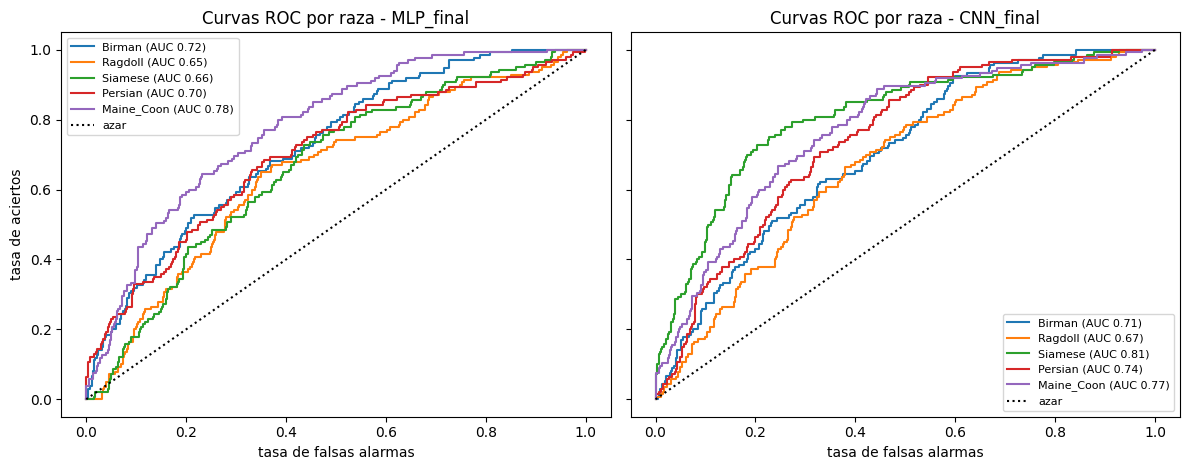

In [25]:
# ==========================================
# 11.2 PRECISIÓN, RECALL Y F1 POR RAZA + CURVAS ROC (5 semillas agregadas, test)
# ==========================================
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

def agrupar(nombre):
    """Junta las probabilidades de test de las 5 semillas y repite las etiquetas reales."""
    return (np.concatenate([PROBS_TEST[(nombre, s)] for s in SEEDS_FINAL]),
            np.tile(y_test, len(SEEDS_FINAL)))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, n in zip(ejes, ["MLP_final", "CNN_final"]):
    P, y = agrupar(n)
    rep = pd.DataFrame(classification_report(y, P.argmax(axis=1), target_names=CLASES,
                                             output_dict=True, zero_division=0)).T
    print(f"\n{n}: precisión, recall y F1 por raza (690 predicciones)")
    print(rep.round(3).to_string())
    rep.round(3).to_csv(f"resultados/reporte_por_raza_{n}.csv")

    Y = label_binarize(y, classes=range(N_CLASES))
    for c in range(N_CLASES):
        fpr, tpr, _ = roc_curve(Y[:, c], P[:, c])
        ax.plot(fpr, tpr, label=f"{CLASES[c]} (AUC {auc(fpr, tpr):.2f})")
    ax.plot([0, 1], [0, 1], "k:", label="azar")
    ax.set_title(f"Curvas ROC por raza - {n}"); ax.set_xlabel("tasa de falsas alarmas"); ax.legend(fontsize=8)
ejes[0].set_ylabel("tasa de aciertos")
plt.tight_layout(); guardar_fig("13_curvas_roc"); plt.show()

### Interpretación de precisión, recall y F1 por raza y de las curvas ROC

**Por raza (5 semillas agrupadas).** En la MLP el F1 va de 0,341 (Persian) a 0,428 (Maine_Coon) y la precisión de 0,331 (Ragdoll) a 0,426 (Maine_Coon): rinde de forma bastante pareja entre razas. En la CNN el F1 va de 0,291 (Birman) a 0,470 (Siamese), más desigual. Siamese es la raza que mejor reconoce la CNN, con precisión 0,492 y recall 0,450. Ragdoll muestra el efecto "imán": recall de 0,536 pero precisión de 0,342, por lo que su F1 (0,418) es mucho menor de lo que sugiere el recall. Birman es la más débil de la CNN (precisión 0,343, recall 0,252).

**Curvas ROC.** Cada curva compara una raza contra las demás, y el AUC resume cuánto la separa del resto (0,5 es el azar). Los AUC por raza son, en la MLP, Birman 0,72, Ragdoll 0,65, Siamese 0,66, Persian 0,70 y Maine_Coon 0,78; en la CNN, Birman 0,71, Ragdoll 0,67, Siamese 0,81, Persian 0,74 y Maine_Coon 0,77. La CNN mejora sobre todo Siamese (+0,15) y algo Persian (+0,04); en las demás la diferencia es de ±0,02. Ragdoll es la raza peor separada en ambos modelos (0,65 y 0,67), lo que confirma que el recall alto de la CNN en Ragdoll no viene de separarla bien sino de predecirla en exceso. Todos los AUC por raza quedan sobre el azar pero lejos de 1.

**Cautela.** Las curvas usan 690 predicciones que provienen de solo 138 imágenes (5 semillas sobre el mismo test), por lo que no son independientes y las diferencias de 0,01 a 0,04 no son concluyentes.

## 12. Etapa de explicabilidad (XAI)
### 12.1 Grad-CAM (CNN) y mapa de saliencia por gradiente (MLP), cuantificados con las máscaras del dataset

Una red neuronal es una "caja negra": se sabe qué predice, pero no en qué se fijó para decidir. Las técnicas XAI (Inteligencia Artificial Explicable) iluminan en qué zonas de la imagen se apoyó el modelo, como pedirle a un alumno que señale en el enunciado dónde encontró la respuesta.

- **Grad-CAM (CNN)** (Selvaraju et al., 2017): combina los mapas de activación de la última capa convolucional (`conv3`) ponderados por cuánto influye cada uno en la clase predicha. Produce un mapa de calor de baja resolución (16x16, ampliado a 64x64).
- **Saliencia por gradiente (MLP):** la MLP no tiene mapas convolucionales, así que se usa el valor absoluto del gradiente de la probabilidad de la clase predicha respecto de cada píxel de entrada. Es un método distinto y más ruidoso, por lo que la comparación con Grad-CAM es orientativa.

**Cuantificación.** El dataset trae para cada imagen una máscara (`trimap`) con tres valores: animal, fondo y borde. Se define como zona del animal todo lo que no es fondo (animal más borde). Para cada imagen se calcula qué **fracción de la atención** del modelo cae en esa zona y se compara con la **fracción de la imagen** que esa zona ocupa. El **cociente de foco** es la primera dividida por la segunda: un valor de 1 significa que el modelo mira todo por igual, mayor que 1 que se concentra en el animal, y menor que 1 que mira más el fondo. Se calcula con las 5 semillas de cada modelo y se separa entre predicciones correctas e incorrectas.

**Limitaciones.** Estos mapas muestran dónde se apoya el modelo y no demuestran causalidad. Con 64x64 píxeles los mapas son muy gruesos, y las máscaras redimensionadas pierden precisión en los bordes.


Máscaras: (138, 64, 64) | área media de la zona del animal: 0.49
modelo                   CNN_final  MLP_final
atencion_en_animal mean      0.540      0.524
                   std       0.030      0.002
area_animal        mean      0.494      0.494
                   std       0.000      0.000
cociente           mean      1.100      1.080
                   std       0.067      0.003
cociente_aciertos  mean      1.212      1.058
                   std       0.074      0.012
cociente_errores   mean      1.032      1.093
                   std       0.068      0.005


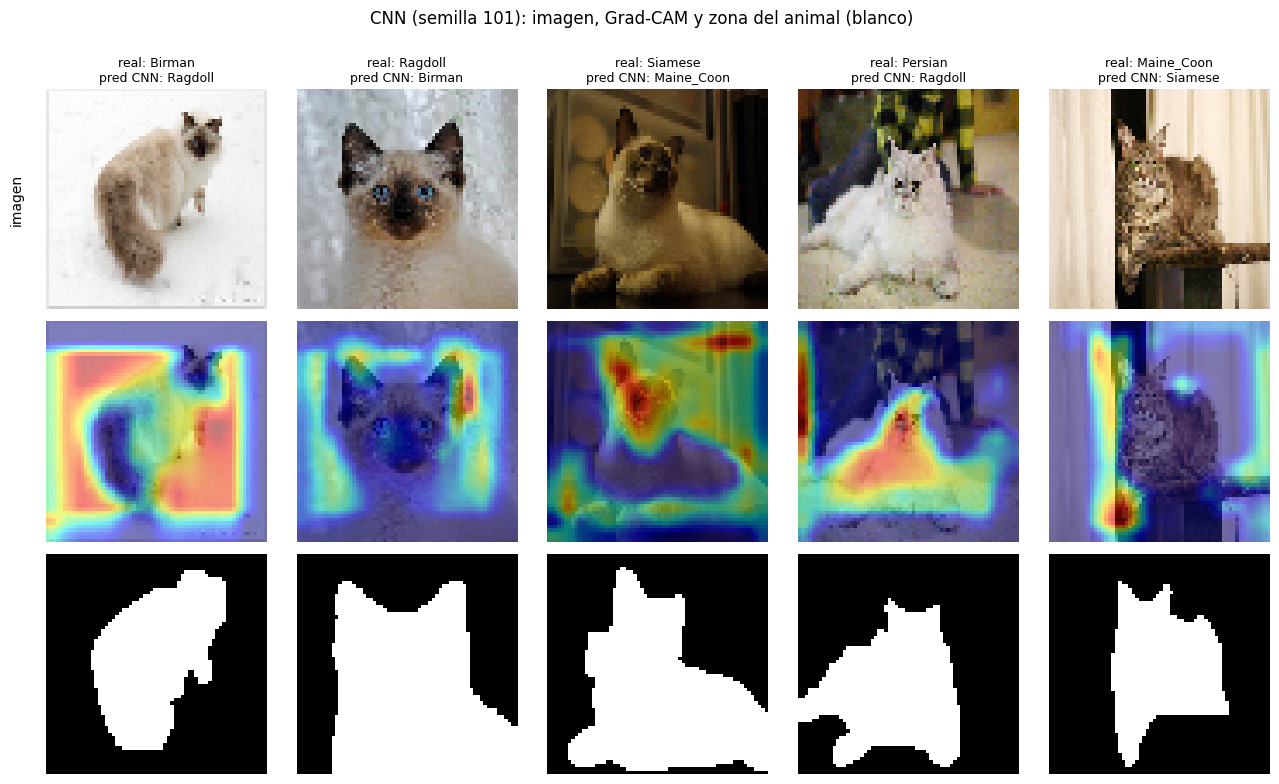

In [26]:
# ==========================================
# 12.1 GRAD-CAM (CNN) Y SALIENCIA (MLP), CUANTIFICADOS CON LOS TRIMAPS
# ==========================================
def cargar_mascaras(df, lado=RES_BASE):
    """Máscara booleana 'no es fondo' (animal + borde) de cada imagen, redimensionada como las fotos."""
    ms = []
    for nombre in df["imagen"]:
        tri = Image.open(f"{RAIZ}/annotations/trimaps/{nombre}.png")
        tri = np.array(tri.resize((lado, lado), Image.NEAREST))
        ms.append(tri != 2)                      # trimap: 1 = animal, 2 = fondo, 3 = borde
    return np.stack(ms)

def mapa_gradcam(m, X, clases):
    """Grad-CAM sobre la capa conv3 para la clase indicada. Devuelve mapas (n, 64, 64).
    Pasa la imagen por las capas una a una (no depende del grafo del modelo cargado)."""
    x = tf.convert_to_tensor(X.astype("float32"))
    with tf.GradientTape() as tape:
        for capa in m.layers:
            x = capa(x, training=False)
            if capa.name == "conv3":
                conv = x                                   # salida de conv3 (n, 16, 16, 128)
        probs = x                                          # salida final (softmax)
        sel = tf.gather(probs, clases, batch_dims=1)
    grads = tape.gradient(sel, conv)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(conv * w, axis=-1, keepdims=True))
    return tf.image.resize(cam, (RES_BASE, RES_BASE))[..., 0].numpy()

def mapa_saliencia(m, X, clases):
    """Valor absoluto del gradiente de la probabilidad de la clase respecto de los píxeles (máximo entre canales)."""
    x = tf.convert_to_tensor(X.astype("float32"))
    with tf.GradientTape() as tape:
        tape.watch(x)
        probs = m(x, training=False)
        sel = tf.gather(probs, clases, batch_dims=1)
    return tf.reduce_max(tf.abs(tape.gradient(sel, x)), axis=-1).numpy()

def foco(mapas, mascaras):
    """Fracción de la atención dentro de la zona del animal, fracción de área y cociente de foco."""
    mapas = mapas / (mapas.sum(axis=(1, 2), keepdims=True) + 1e-9)
    en_animal = (mapas * mascaras).sum(axis=(1, 2))
    area = mascaras.mean(axis=(1, 2))
    return en_animal, area, en_animal / np.maximum(area, 1e-9)

MASCARAS = cargar_mascaras(sp["test"])
print(f"Máscaras: {MASCARAS.shape} | área media de la zona del animal: {MASCARAS.mean():.2f}")

METODOS = {"MLP_final": mapa_saliencia, "CNN_final": mapa_gradcam}
filas, MAPAS_101 = [], {}
for nombre, fn in METODOS.items():
    for s in SEEDS_FINAL:
        m = tf.keras.models.load_model(f"models/{nombre}_s{s}.keras")
        pred = PROBS_TEST[(nombre, s)].argmax(axis=1).astype("int32")
        mapas = fn(m, X_test, pred)
        if s == SEEDS_FINAL[0]:
            MAPAS_101[nombre] = (mapas, pred)
        en_animal, area, cociente = foco(mapas, MASCARAS)
        ok = pred == y_test
        filas.append(dict(modelo=nombre, semilla=s, atencion_en_animal=en_animal.mean(), area_animal=area.mean(),
                          cociente=cociente.mean(), cociente_aciertos=cociente[ok].mean(),
                          cociente_errores=cociente[~ok].mean()))

df_foco = pd.DataFrame(filas)
print(df_foco.groupby("modelo")[["atencion_en_animal", "area_animal", "cociente",
                                 "cociente_aciertos", "cociente_errores"]].agg(["mean", "std"]).round(3).T.to_string())

# --- Ejemplos visuales (semilla 101): una imagen de test por raza ---
fig, ejes = plt.subplots(3, N_CLASES, figsize=(2.6 * N_CLASES, 7.8))
elegidas = [int(np.where(y_test == c)[0][0]) for c in range(N_CLASES)]
mapas_cnn, pred_cnn = MAPAS_101["CNN_final"]
for j, i in enumerate(elegidas):
    cam = mapas_cnn[i] / (mapas_cnn[i].max() + 1e-9)
    ejes[0, j].imshow(X_test[i]); ejes[0, j].set_title(f"real: {CLASES[y_test[i]]}\npred CNN: {CLASES[pred_cnn[i]]}", fontsize=9)
    ejes[1, j].imshow(X_test[i]); ejes[1, j].imshow(cam, cmap="jet", alpha=0.5)
    ejes[2, j].imshow(MASCARAS[i], cmap="gray")
    for f in range(3): ejes[f, j].axis("off")
ejes[0, 0].text(-0.1, 0.5, "imagen", transform=ejes[0, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("CNN (semilla 101): imagen, Grad-CAM y zona del animal (blanco)", y=1.0)
plt.tight_layout(); guardar_fig("08_gradcam_ejemplos"); plt.show()

### Interpretación de la explicabilidad

**Qué muestra la figura.** Los cinco ejemplos corresponden a la primera imagen de test de cada raza, y la CNN (semilla 101) se equivocó en todas, por lo que ilustran errores y no el comportamiento típico del modelo. En ellos, la atención de Grad-CAM (zonas rojas y naranjas) cae a menudo sobre elementos que no son el animal:
- *Birman* (predicho Ragdoll): la atención se concentra en el fondo blanco, a la izquierda y abajo a la derecha del gato, y el cuerpo del gato aparece casi sin atención.
- *Ragdoll* (predicho Birman): la atención se distribuye por los bordes y el fondo de la foto, y la cara, que es lo más distintivo, casi no se activa.
- *Maine_Coon* (predicho Siamese): el punto más caliente está en el fondo, abajo a la izquierda, sobre un poste oscuro, y también a lo largo de la cortina de la izquierda.
- *Siamese* (predicho Maine_Coon) y *Persian* (predicho Ragdoll): la atención sí cae sobre el animal (cara y cuerpo), y aun así la predicción es incorrecta. Mirar al animal no garantiza acertar, porque la dificultad también está en que estas razas se parecen entre sí.

**Cuantificación con las máscaras del dataset** (promedio de las 5 semillas). La zona del animal (animal más borde) ocupa el 49,4% de la imagen. La CNN pone el 54,0% de su atención en esa zona (cociente de foco 1,10 ± 0,07) y la MLP el 52,4% (cociente 1,08 ± 0,00). Un cociente de 1 significa que el modelo mira todo por igual, y el máximo posible con esta área sería 2,0 (toda la atención sobre el animal). Ambos modelos quedan **apenas por encima de 1: casi no prefieren al animal sobre el fondo.**

**Aciertos contra errores.** En la CNN el cociente es 1,21 en las predicciones correctas y 1,03 en las incorrectas: cuando acierta, el modelo se concentra más en el animal, y cuando se equivoca reparte su atención casi de forma uniforme. Esto es consistente con los ejemplos de la figura: en los errores, el modelo reparte su atención sin concentrarse en el animal. Si eso significa que se apoya en el fondo para decidir se contrasta con una prueba directa en la sección 12.2. En la MLP no hay diferencia clara (1,06 en aciertos y 1,09 en errores, e incluso al revés), por lo que su saliencia no distingue los aciertos de los errores.

**Comparación de explicabilidad MLP vs CNN.** Grad-CAM produce mapas espacialmente coherentes (zonas continuas que se pueden ubicar sobre el gato o el fondo) y permite relacionar la atención con el acierto, algo que la saliencia por gradiente de la MLP no logra (su cociente es casi constante entre semillas, 1,08 ± 0,00, lo que podría indicar mapas dispersos y limita su utilidad cualitativa en esta resolución). Los cocientes de ambos métodos no son estrictamente comparables, porque Grad-CAM entrega un mapa suave de 16x16 ampliado y la saliencia un mapa a nivel de píxel, más ruidoso. En términos de interpretabilidad, la CNN ofrece una explicación más útil.

**Limitaciones.** (1) Grad-CAM tiene resolución de 16x16 sobre una imagen de 64x64, por lo que no delimita bordes con precisión. (2) Los mapas muestran dónde se apoya el modelo, pero no demuestran causalidad. (3) La zona del animal incluye el borde del trimap, lo que la agranda un poco. (4) La diferencia entre aciertos y errores en la CNN (0,18) es mayor que la desviación estándar entre semillas (0,07), pero son solo 5 semillas sobre las mismas 138 imágenes. La sección 12.2 contrasta con una prueba directa si los modelos dependen del fondo.
**Qué muestra la figura.** Los cinco ejemplos corresponden a la primera imagen de test de cada raza, y la CNN (semilla 101) se equivocó en todas, por lo que ilustran errores y no el comportamiento típico del modelo. En ellos, la atención de Grad-CAM (zonas rojas y naranjas) cae a menudo sobre elementos que no son el animal:
- *Birman* (predicho Ragdoll): la atención se concentra en el fondo blanco, a la izquierda y abajo a la derecha del gato, y el cuerpo del gato aparece casi sin atención.
- *Ragdoll* (predicho Birman): la atención se distribuye por los bordes y el fondo de la foto, y la cara, que es lo más distintivo, casi no se activa.
- *Maine_Coon* (predicho Siamese): el punto más caliente está en el fondo, abajo a la izquierda, sobre un poste oscuro, y también a lo largo de la cortina de la izquierda.
- *Siamese* (predicho Maine_Coon) y *Persian* (predicho Ragdoll): la atención sí cae sobre el animal (cara y cuerpo), y aun así la predicción es incorrecta. Mirar al animal no garantiza acertar, porque la dificultad también está en que estas razas se parecen entre sí.

**Cuantificación con las máscaras del dataset** (promedio de las 5 semillas). La zona del animal (animal más borde) ocupa el 49,4% de la imagen. La CNN pone el 54,0% de su atención en esa zona (cociente de foco 1,10 ± 0,07) y la MLP el 52,4% (cociente 1,08 ± 0,00). Un cociente de 1 significa que el modelo mira todo por igual, y el máximo posible con esta área sería 2,0 (toda la atención sobre el animal). Ambos modelos quedan **apenas por encima de 1: casi no prefieren al animal sobre el fondo.**

**Aciertos contra errores.** En la CNN el cociente es 1,21 en las predicciones correctas y 1,03 en las incorrectas: cuando acierta, el modelo se concentra más en el animal, y cuando se equivoca reparte su atención casi de forma uniforme. Esto es consistente con los ejemplos de la figura: en los errores, el modelo reparte su atención sin concentrarse en el animal. Si eso significa que se apoya en el fondo para decidir se contrasta con una prueba directa en la sección 12.2. En la MLP no hay diferencia clara (1,06 en aciertos y 1,09 en errores, e incluso al revés), por lo que su saliencia no distingue los aciertos de los errores.

**Comparación de explicabilidad MLP vs CNN.** Grad-CAM produce mapas espacialmente coherentes (zonas continuas que se pueden ubicar sobre el gato o el fondo) y permite relacionar la atención con el acierto, algo que la saliencia por gradiente de la MLP no logra (su cociente es casi constante entre semillas, 1,08 ± 0,00, lo que podría indicar mapas dispersos, lo que limita su utilidad cualitativa en esta resolución.. Los cocientes de ambos métodos no son estrictamente comparables, porque Grad-CAM entrega un mapa suave de 16x16 ampliado y la saliencia un mapa a nivel de píxel, más ruidoso. En términos de interpretabilidad, la CNN ofrece una explicación más útil.

**Limitaciones.** (1) Grad-CAM tiene resolución de 16x16 sobre una imagen de 64x64, por lo que no delimita bordes con precisión. (2) Los mapas muestran dónde se apoya el modelo, pero no demuestran causalidad. (3) La zona del animal incluye el borde del trimap, lo que la agranda un poco. (4) La diferencia entre aciertos y errores en la CNN (0,18) es mayor que la desviación estándar entre semillas (0,07), pero son solo 5 semillas sobre las mismas 138 imágenes. La sección 12.2 contrasta con una prueba directa si los modelos dependen del fondo.

### 12.2 Prueba de fondo: ¿qué información tiene el animal y cuál el fondo?

Los mapas de atención muestran dónde se apoya el modelo, pero no si el fondo le basta para decidir. Para comprobarlo sin reentrenar, los modelos ya entrenados se evalúan en tres versiones del test: la original, una donde solo queda el animal (el fondo se rellena con el color medio del conjunto) y una donde solo queda el fondo (se rellena el animal). Si el modelo dependiera del fondo, la versión "solo fondo" mantendría un rendimiento alto, y la versión "solo animal" lo haría caer.

                         acc            f1       
                        mean    std   mean    std
modelo    variante                               
CNN_final original     0.386  0.046  0.376  0.053
          solo_animal  0.390  0.051  0.351  0.083
          solo_fondo   0.245  0.035  0.232  0.034
MLP_final original     0.378  0.013  0.376  0.013
          solo_animal  0.400  0.035  0.393  0.025
          solo_fondo   0.235  0.021  0.202  0.020


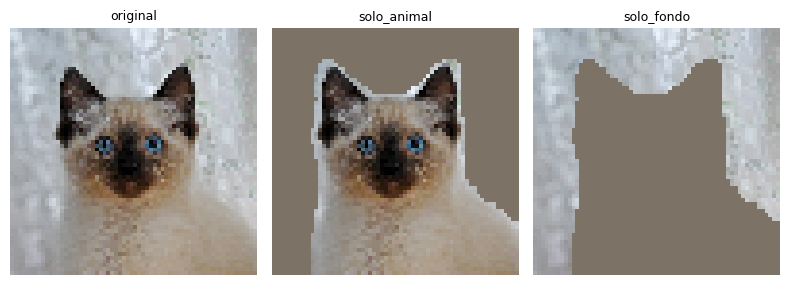

In [27]:
# ==========================================
# 12.2 PRUEBA DE FONDO: ¿QUÉ INFORMACIÓN TIENE EL ANIMAL Y CUÁL EL FONDO? (sin reentrenar)
# ==========================================
GRIS = X_dev.reshape(-1, 3).mean(axis=0).astype("float32")     # color medio del conjunto de desarrollo

def variante(X, mascara, conservar):
    """Conserva solo el 'animal' o solo el 'fondo' y rellena el resto con el color medio."""
    zona = mascara[..., None] if conservar == "animal" else ~mascara[..., None]
    return np.where(zona, X.astype("float32"), GRIS)

VARIANTES = {"original": X_test.astype("float32"),
             "solo_animal": variante(X_test, MASCARAS, "animal"),
             "solo_fondo": variante(X_test, MASCARAS, "fondo")}

filas = []
for nombre in ["MLP_final", "CNN_final"]:
    for s in SEEDS_FINAL:
        m = tf.keras.models.load_model(f"models/{nombre}_s{s}.keras")
        for v, Xv in VARIANTES.items():
            pred = m.predict(Xv, verbose=0).argmax(axis=1)
            filas.append(dict(modelo=nombre, semilla=s, variante=v, **metricas(y_test, pred)))

df_oclusion = pd.DataFrame(filas)
df_oclusion.to_csv("resultados/prueba_fondo.csv", index=False)
print(df_oclusion.groupby(["modelo", "variante"])[["acc", "f1"]].agg(["mean", "std"]).round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(8, 2.8))
for a, (v, Xv) in zip(ax, VARIANTES.items()):
    a.imshow(Xv[0].astype("uint8")); a.set_title(v, fontsize=9); a.axis("off")
plt.tight_layout(); guardar_fig("09_variantes_fondo"); plt.show()

### Interpretación de la prueba de fondo

**Qué se hizo.** Sin reentrenar, los modelos ya entrenados (5 semillas) se evaluaron en tres versiones del test: la original, una con solo el animal (el fondo se rellena con el color medio) y una con solo el fondo (se rellena el animal). Si el modelo dependiera del fondo, "solo fondo" mantendría un rendimiento alto y "solo animal" lo haría caer.

**Resultados (media de 5 semillas).**
| Modelo | Original (F1 / acc) | Solo animal (F1 / acc) | Solo fondo (F1 / acc) |
|---|---|---|---|
| MLP | 0,376 / 0,378 | 0,393 / 0,400 | 0,202 / 0,235 |
| CNN | 0,376 / 0,386 | 0,351 / 0,390 | 0,232 / 0,245 |

**Lectura.**
- *Con solo el animal el rendimiento se mantiene:* la accuracy no cae en ninguno de los dos modelos (la MLP sube 0,022 y la CNN 0,004), y el F1 cambia en +0,017 (MLP) y −0,025 (CNN, con una desviación estándar de 0,083 entre semillas, por lo que esa caída no es distinguible del ruido). La información que usan los modelos está en la zona del animal.
- *Con solo el fondo el rendimiento queda cerca del azar:* accuracy de 0,235 (MLP) y 0,245 (CNN) frente a 0,20 del azar, y F1 de 0,202 y 0,232. Con 138 imágenes el error estándar de una accuracy cercana al azar es de unos 0,034, así que estas diferencias son del tamaño del ruido de muestreo.
- *Conclusión:* **no hay evidencia de que los modelos usen el fondo como atajo.** Esto matiza la lectura de los ejemplos de Grad-CAM, donde en varios errores la atención caía sobre el fondo: una atención dispersa (cociente de foco cercano a 1) no implica que el modelo dependa del fondo para decidir.

**Cautelas.** (1) Rellenar con gris crea imágenes que los modelos no vieron al entrenar, y esa diferencia de condiciones puede afectar los resultados por sí sola. (2) La máscara conserva la silueta del animal: en "solo animal" se ve la forma completa del gato y en "solo fondo" el hueco con su contorno, por lo que "solo fondo" no está completamente libre de información sobre el animal, y si algo, sobreestima lo que aporta el fondo. (3) La zona del animal incluye el borde del trimap. (4) Es una prueba sobre 138 imágenes y 5 semillas que evalúan las mismas fotos. (5) Que el fondo no sea un atajo no significa que no haya otros sesgos de color o contexto: solo se descartó el efecto del fondo completo.

## 13. Análisis de sesgos y medidas de mitigación

Un sesgo es una distorsión sistemática, ya sea en los datos o en los resultados, que hace que el modelo funcione peor o distinto en unos casos que en otros. Se revisan los de este proyecto, con la evidencia que se tiene de cada uno.

### 13.1 Sesgos en los datos
1. **Cobertura limitada (muestreo).** El problema de negocio es una clínica que quiere proponer la raza de gatos al registrar pacientes, pero el conjunto solo contiene 10 razas puras seleccionadas por nosotros (5 por subconjunto) y el modelo solo puede elegir entre 5 de ellas. Un gato mestizo o de una raza no incluida se clasificará igual como una de las 5, sin forma de indicar "ninguna". En la práctica una clínica ve muchos gatos mestizos, por lo que este es el mayor límite de cobertura del proyecto.
2. **Tamaño y balance.** Cada raza tiene 156 o 157 imágenes en desarrollo y 27 o 28 en test. El balance se logró recortando todas las razas a 184 imágenes (Bombay limita), lo que mejora la equidad entre razas pero deja pocos datos y un test pequeño (138 imágenes) con alta incertidumbre.
3. **Variabilidad no controlada en las fotos.** El EDA mostró fondos, iluminación, encuadres y calidad muy distintos (gatos pequeños en una foto grande, bordes negros, objetos que tapan al animal) y la compresión a 64x64 con deformación de la proporción. No se auditó el origen de las fotos ni si cada raza proviene de fuentes con estilos distintos.
4. **Etiquetas y definición de "parecidas".** La raza viene del nombre del archivo y no se verificó. La agrupación PARECIDAS/DISTINTAS la definimos nosotros y se respaldó en entregas anteriores solo con medidas de color y apariencia global (no se repiten aquí). La diferencia de dificultad entre ambos subconjuntos se observó en la EP1 (F1 macro de la MLP de 0,363 en PARECIDAS contra 0,487 en DISTINTAS, sección 1.5); en este notebook solo se evaluó PARECIDAS.

### 13.2 Sesgos en los resultados
1. **Rendimiento desigual entre razas.** El recall por raza va de 0,25 (Birman) a 0,54 (Ragdoll) en la CNN y de 0,30 (Persian) a 0,43 (Maine_Coon) en la MLP. Las razas no se reconocen con la misma calidad, y las dos arquitecturas fallan en razas distintas.
2. **Clase "imán" (Ragdoll).** La CNN predice Ragdoll en cerca del 32% de los casos cuando le corresponde el 20%, por lo que su recall alto (0,54) viene con una precisión baja (~0,34). Para una clínica significa que una ficha con "Ragdoll" tiene muchas probabilidades de estar mal.
3. **Confusión entre razas parecidas.** Los errores se concentran en dos grupos: Birman, Ragdoll y Siamese por un lado, y Persian y Maine_Coon por el otro.
4. **Fondo.** La prueba de fondo no encontró evidencia de que el modelo use el fondo como atajo (con solo el fondo el rendimiento queda cerca del azar), pero la atención de ambos modelos está poco concentrada en el animal (cociente de foco de 1,08 a 1,10).

### 13.3 Implicancias éticas y de uso
Con un F1 cercano a 0,38, el modelo se equivoca en más de la mitad de las imágenes. La raza condiciona controles preventivos y riesgos conocidos, por lo que aceptar sin revisar una raza incorrecta puede llevar a registrar información clínica errónea. Por eso el sistema solo se justifica como **apoyo con confirmación humana**, y no como decisión automática.

### 13.4 Medidas de mitigación propuestas
| Sesgo o riesgo | Medida concreta | Estado |
|---|---|---|
| Errores con confianza baja | **Abstención:** no proponer raza cuando la probabilidad máxima sea menor que un umbral y dejar el campo vacío para que lo complete el personal | Evaluada en 13.5: mejora modesta (accuracy de 0,38 a ~0,44 al responder el 50%) |
| Cobertura (mestizos, razas no incluidas) | Agregar una clase "otra / mestizo" con imágenes de otras razas y reentrenar; informar al usuario que el sistema solo cubre las razas del entrenamiento | Propuesta |
| Pocos datos y baja resolución | Transfer learning (por ejemplo, MobileNetV2 preentrenada) y mayor resolución, más imágenes por raza (hay hasta 200 por raza en el dataset) | Propuesta |
| Clase "imán" y recall desigual | Ajustar los umbrales o pesos por clase para equilibrar precisión y recall, y reportar el recall por raza como KPI (no solo el F1 global) | Propuesta |
| Influencia del fondo y del encuadre | Recortar al animal con un detector o con el trimap antes de clasificar, y probar aumentos de datos más suaves (solo giro horizontal) | Propuesta |
| Test pequeño | Aumentar el conjunto de prueba o usar validación cruzada anidada para reportar intervalos de confianza | Propuesta |
| Uso en producción | Monitorear el recall por raza con datos reales y reentrenar periódicamente | Propuesta |

### 13.5 Mitigación por abstención: ¿sube la precisión si el modelo no responde cuando duda?

La primera medida de la tabla anterior se puede probar sin reentrenar nada, con las probabilidades de test que ya se guardaron. Se descarta un porcentaje de las predicciones con menor confianza (probabilidad máxima del modelo) y se mide la accuracy y el F1 de las que sí se responden, junto con la cobertura (qué fracción de los casos recibe respuesta). Se usan las predicciones de las 5 semillas juntas.

In [28]:
# ==========================================
# 13.5 MITIGACIÓN POR ABSTENCIÓN: ¿SUBE LA PRECISIÓN SI EL MODELO "NO RESPONDE" CUANDO DUDA?
# ==========================================
def curva_abstencion(nombre, descartar=(0.0, 0.25, 0.50, 0.75)):
    """Con las predicciones de las 5 semillas juntas, descarta el q% de casos con menor confianza
    (probabilidad máxima) y mide accuracy y F1 de lo que sí se responde, junto con la cobertura."""
    P = np.concatenate([PROBS_TEST[(nombre, s)] for s in SEEDS_FINAL])
    y = np.tile(y_test, len(SEEDS_FINAL))
    conf, pred = P.max(axis=1), P.argmax(axis=1)
    filas = []
    for q in descartar:
        umbral = np.quantile(conf, q)
        usar = conf >= umbral
        filas.append(dict(modelo=nombre, descartado=f"{q:.0%}", umbral_confianza=round(float(umbral), 3),
                          cobertura=round(float(usar.mean()), 2),
                          acc=round(float((pred[usar] == y[usar]).mean()), 3),
                          f1=round(float(f1_score(y[usar], pred[usar], average="macro")), 3)))
    return filas

df_abst = pd.DataFrame(curva_abstencion("MLP_final") + curva_abstencion("CNN_final"))
print(df_abst.to_string(index=False))
df_abst.to_csv("resultados/abstencion.csv", index=False)

   modelo descartado  umbral_confianza  cobertura   acc    f1
MLP_final         0%             0.238       1.00 0.378 0.378
MLP_final        25%             0.384       0.75 0.414 0.416
MLP_final        50%             0.478       0.50 0.429 0.432
MLP_final        75%             0.616       0.25 0.405 0.375
CNN_final         0%             0.219       1.00 0.386 0.380
CNN_final        25%             0.359       0.75 0.406 0.399
CNN_final        50%             0.444       0.50 0.443 0.426
CNN_final        75%             0.557       0.25 0.445 0.418


### Interpretación de la mitigación por abstención (sección 13.5)

**Qué se hizo.** Con las probabilidades de test de las 5 semillas juntas (690 predicciones por modelo), se descarta un porcentaje de las predicciones con menor confianza (probabilidad máxima) y se mide la accuracy y el F1 de las que sí se responden. Es como un alumno que deja en blanco las preguntas que no sabe: si la confianza informa algo, lo que sí contesta debería acertar más.

**Resultados.**
| Cobertura (se responde) | MLP: accuracy / F1 | CNN: accuracy / F1 |
|---|---|---|
| 100% (sin abstención) | 0,378 / 0,378 | 0,386 / 0,380 |
| 75% | 0,414 / 0,416 | 0,406 / 0,399 |
| 50% | 0,429 / 0,432 | 0,443 / 0,426 |
| 25% | 0,405 / 0,375 | 0,445 / 0,418 |

**Lectura.**
- *La confianza es algo informativa.* Al responder solo la mitad de los casos más seguros, la accuracy sube de 0,378 a 0,429 en la MLP (+0,051) y de 0,386 a 0,443 en la CNN (+0,057). En la CNN el efecto se mantiene al quedarse solo con el 25% más seguro (0,445). En la MLP, en cambio, deja de mejorar en ese tramo (0,405, y el F1 vuelve a 0,375), por lo que su confianza ordena peor los casos.
- *La mejora es modesta.* Aun respondiendo solo la mitad de los casos, el modelo se equivoca en más de la mitad de lo que contesta (accuracy de 0,43 a 0,44). La abstención reduce errores, pero no hace al sistema confiable.
- *Los modelos están sobreconfiados.* En el tramo del 25% con mayor confianza, todas las predicciones tienen una probabilidad máxima de al menos 0,62 (MLP) y 0,56 (CNN), pero aciertan solo el 40,5% y el 44,5% de las veces. La probabilidad que declaran supera su acierto real, por lo que no deben interpretarse como probabilidades calibradas.

**Cautelas.** (1) Con cobertura del 25% quedan unas 170 predicciones (de 690), y el error estándar de una accuracy cercana a 0,44 con ese tamaño es de al menos 0,04, de modo que la mayoría de las diferencias entre coberturas (de 0,02 a 0,06) son del tamaño del ruido. El error estándar real es mayor, porque las 5 semillas evalúan las mismas 138 imágenes y esas predicciones no son independientes. (2) Los umbrales se calcularon con los cuantiles de las propias confianzas del test, así que esto es una evaluación descriptiva. En un uso real el umbral debe fijarse con datos de validación y probarse luego en datos nuevos. (3) Abstenerse no corrige el sesgo de fondo, solo evita proponer raza en los casos dudosos, por lo que se combina con las demás medidas de la sección 13.4.

**Conclusión.** La abstención es una medida de bajo costo y razonable para el uso previsto (apoyo con confirmación humana: si el modelo duda, deja el campo vacío), pero su efecto es limitado, y el problema de fondo (poco rendimiento con pocos datos y baja resolución) requiere las otras medidas propuestas, en especial transfer learning y más datos.

## 14. Comparación final MLP vs CNN y modelo recomendado

### 14.1 Tabla comparativa final

Se reúnen en una sola tabla los resultados de las dos configuraciones elegidas por la búsqueda: validación cruzada (usada para elegirlas), evaluación en test (usada una sola vez para medirlas), cantidad de parámetros y tiempos de entrenamiento. Es como el resumen de notas de un semestre: muestra no solo el promedio, sino también cuánto varió y cuánto costó obtenerlo.

In [29]:
# ==========================================
# 14.1 TABLA COMPARATIVA FINAL: MLP ELEGIDA vs CNN ELEGIDA
# ==========================================
filas = []
for nombre_cv, nombre_test, etiqueta in [(ELEGIDA_MLP, "MLP_final", "MLP"),
                                         (ELEGIDA_CNN, "CNN_final", "CNN")]:
    cv = RES[nombre_cv][0]
    t = df_test[df_test.config == nombre_test]
    filas.append({
        "modelo": etiqueta,
        "configuración elegida": nombre_cv,
        "parámetros": f"{int(cv['parametros'].iloc[0]):,}",
        "F1 validación cruzada": f"{cv['f1'].mean():.3f} ± {cv['f1'].std():.3f}",
        "F1 test (5 semillas)": f"{t['f1'].mean():.3f} ± {t['f1'].std():.3f}",
        "Accuracy test": f"{t['acc'].mean():.3f} ± {t['acc'].std():.3f}",
        "ROC-AUC test": f"{t['roc_auc'].mean():.3f} ± {t['roc_auc'].std():.3f}",
        "Recall mínimo test": f"{t['recall_min'].mean():.3f} ± {t['recall_min'].std():.3f}",
        "Segundos por entrenamiento (validación cruzada)": round(cv["segundos"].mean()),
        "Segundos por entrenamiento (test)": round(t["segundos"].mean()),
    })

tabla_final = pd.DataFrame(filas).set_index("modelo").T
print(tabla_final.to_string())
tabla_final.to_csv("resultados/comparacion_final.csv")

modelo                                                     MLP              CNN
configuración elegida                               MLP_lr1e-3  CNN_sin_aumento
parámetros                                           1,573,644          101,836
F1 validación cruzada                            0.407 ± 0.039    0.475 ± 0.058
F1 test (5 semillas)                             0.376 ± 0.013    0.376 ± 0.053
Accuracy test                                    0.378 ± 0.013    0.386 ± 0.046
ROC-AUC test                                     0.704 ± 0.018    0.742 ± 0.022
Recall mínimo test                               0.259 ± 0.045    0.206 ± 0.075
Segundos por entrenamiento (validación cruzada)            143              382
Segundos por entrenamiento (test)                          136              318


### 14.1b Cumplimiento de los KPIs

Se verifica el cumplimiento de los KPIs definidos en la sección 1.3, con el promedio de las 5 semillas en el conjunto de prueba y, además, en cuántas de las 5 semillas se cumple cada meta.

In [30]:
# ==========================================
# 14.1b CUMPLIMIENTO DE LOS KPIs (prueba, 5 semillas)
# ==========================================
KPI_F1, KPI_RECALL_MIN = 0.40, 0.20
filas = []
for n in ["MLP_final", "CNN_final"]:
    t = df_test[df_test.config == n]
    f1, rm = t["f1"].mean(), t["recall_min"].mean()
    filas.append({"modelo": n,
                  "F1 macro": f"{f1:.3f}", "meta F1": f">= {KPI_F1}", "cumple F1": "Sí" if f1 >= KPI_F1 else "No",
                  "semillas con F1 >= meta": f"{(t['f1'] >= KPI_F1).sum()}/{len(t)}",
                  "recall mínimo": f"{rm:.3f}", "meta recall": f">= {KPI_RECALL_MIN}",
                  "cumple recall": "Sí" if rm >= KPI_RECALL_MIN else "No",
                  "semillas con recall mín. >= meta": f"{(t['recall_min'] >= KPI_RECALL_MIN).sum()}/{len(t)}"})
print(pd.DataFrame(filas).set_index("modelo").T.to_string())

modelo                           MLP_final CNN_final
F1 macro                             0.376     0.376
meta F1                             >= 0.4    >= 0.4
cumple F1                               No        No
semillas con F1 >= meta                0/5       1/5
recall mínimo                        0.259     0.206
meta recall                         >= 0.2    >= 0.2
cumple recall                           Sí        Sí
semillas con recall mín. >= meta       5/5       3/5


### Interpretación del cumplimiento de los KPIs

Las metas se mantienen desde la EP1 (sección 1.3) y se miden en el conjunto de prueba con 5 semillas.

| KPI | Meta | MLP | CNN | Veredicto |
|---|---|---|---|---|
| F1 macro (principal) | ≥ 0,40 | 0,376 (0/5 semillas) | 0,376 (1/5 semillas) | **No se cumple en ninguno** |
| Recall de la raza peor reconocida (secundario) | ≥ 0,20 | 0,259 (5/5 semillas) | 0,206 (3/5 semillas) | Se cumple en promedio en ambos |

**KPI principal.** La meta de 0,40 equivale al doble del azar (sección 1.3): alcanzarla indicaría rendir el doble que adivinar, pero no demostraría por sí sola que el modelo sirve para el uso previsto. Ambos modelos quedan 0,024 bajo la meta. Esa diferencia es menor que la desviación estándar de la CNN entre semillas (0,053), por lo que no se puede descartar que un reentrenamiento la supere, pero el promedio queda bajo la meta y solo la semilla 101 de la CNN (F1 0,457) la alcanza. La conclusión honesta es que **el proyecto no logra la meta de rendimiento definida**.

**KPI secundario.** La MLP lo cumple con holgura. La CNN lo cumple por apenas 0,006 en promedio y en 2 de 5 semillas alguna raza queda bajo 0,20, por lo que su cumplimiento es frágil.

**Implicancia para el problema de negocio.** Con un F1 de 0,38 el sistema no puede prellenar la ficha de forma automática. Por eso se justifica solo como apoyo con confirmación humana y con abstención (sección 13.5), y las mejoras de la sección 14.4 apuntan a cerrar la brecha con la meta. Para una próxima iteración conviene sumar un KPI de negocio, como el porcentaje de fichas prellenadas que el personal acepta sin corregir, medido con datos reales.


### 14.2 Interpretación de las métricas: fortalezas y limitaciones de cada modelo

**Qué dicen las métricas.** En el conjunto de prueba ambos modelos obtienen un F1 macro de 0,376: la MLP con una desviación estándar de 0,013 entre semillas y la CNN con 0,053. La accuracy es parecida (0,378 y 0,386) y la diferencia es mucho menor que la incertidumbre de un test de 138 imágenes (error estándar de unos 0,04). El ROC-AUC, que evalúa qué tan bien ordena el modelo las probabilidades de las razas y no solo su elección final, sí separa a los modelos: 0,742 para la CNN contra 0,704 para la MLP, con la CNN por encima en las cinco semillas (diferencias de +0,074, +0,016, +0,018, +0,073 y +0,012). Ambos valores quedan sobre el azar (0,50) pero lejos de un clasificador confiable. En validación cruzada la CNN elegida superaba a la MLP elegida (F1 0,475 contra 0,407), y esa ventaja no se confirmó en test (se discute en la sección 10).

| Criterio | Ventaja | Evidencia |
|---|---|---|
| Rendimiento en F1 y accuracy | Empate | F1 0,376 en ambos; la diferencia de accuracy (0,008) es menor que el ruido |
| Ordenamiento de probabilidades | CNN | ROC-AUC 0,742 contra 0,704, mejor en 5 de 5 semillas |
| Estabilidad entre semillas | MLP | Desviación estándar del F1 de 0,013 contra 0,053 |
| Raza peor reconocida | MLP | Recall mínimo de 0,259 contra 0,206 |
| Utilidad de la confianza (abstención) | CNN (tendencia) | Accuracy de 0,445 contra 0,405 al responder solo el 25% más seguro |
| Explicabilidad | CNN | Grad-CAM entrega mapas ubicables sobre la imagen y distingue aciertos de errores (cociente de foco 1,21 contra 1,03); la saliencia de la MLP no los distingue |
| Tamaño del modelo | CNN | 101.836 parámetros contra 1.573.644 (unas 15 veces menos) |
| Costo de entrenamiento | MLP | 136 s contra 318 s por entrenamiento en test (la CNN demora unas 2,3 veces más) |

**Fortalezas de la CNN:** mejor ordenamiento de probabilidades, confianza más informativa, explicabilidad más útil y un modelo mucho más pequeño. **Limitaciones de la CNN:** es más inestable entre semillas, reconoce peor a su raza más débil (Birman, recall de 0,25) y tarda más en entrenar. **Fortalezas de la MLP:** es estable, rápida y deja menos razas desprotegidas. **Limitaciones de la MLP:** tiene unas 15 veces más parámetros para un rendimiento equivalente, su saliencia no distingue aciertos de errores y su confianza informa menos.

### 14.3 Modelo recomendado

**Recomendación: la CNN (configuración `CNN_sin_aumento`), usada con abstención y con confirmación humana, y como base para la siguiente iteración.** Esta recomendación es **provisional**: con la evidencia disponible ninguna de las dos arquitecturas es mejor en F1 ni en accuracy, y el AUC es consistente en las 5 semillas; la confianza y la explicabilidad son tendencias. Se elige la CNN por cuatro razones:
1. *Es la mejor base para mejorar.* Las mejoras propuestas con más potencial (transfer learning con redes preentrenadas, mayor resolución, recorte al animal) son convolucionales y no se pueden aplicar a una MLP sobre píxeles aplanados.
2. *Su confianza parece más útil para el uso previsto (tendencia).* En la CNN la accuracy sube de 0,386 a 0,445 al responder solo el 25% más seguro, mientras que en la MLP no mejora en ese tramo (0,405). Esa diferencia es del tamaño del ruido (sección 13.5), por lo que es una tendencia y no evidencia concluyente.
3. *Es explicable de forma más útil.* Grad-CAM permite auditar casos concretos y detectar cuándo el modelo no se concentra en el animal, lo que corresponde a las implicancias éticas de un sistema que propone datos clínicos.
4. *Es más eficiente en parámetros* (unas 15 veces menos para el mismo F1), lo que importa si se despliega en equipos modestos.

**Lo que la recomendación no oculta:** la CNN es más inestable entre semillas (F1 entre 0,32 y 0,46) y deja peor a su raza más débil (recall mínimo de 0,206 contra 0,259 de la MLP). Además, ninguno de los dos modelos cumple el KPI principal (F1 macro ≥ 0,40; sección 14.1b). Si la prioridad del cliente fuera la regularidad y el menor tiempo de entrenamiento, la MLP es una alternativa igual de válida con la evidencia actual. En ningún caso se recomienda su uso como decisión automática: con un F1 cercano a 0,38 el modelo se equivoca en más de la mitad de las imágenes.

### 14.4 Mejoras propuestas para futuras iteraciones
1. **Transfer learning** con una red preentrenada (por ejemplo, MobileNetV2), que parte con rasgos visuales ya aprendidos y necesita menos imágenes, y **mayor resolución** de entrada (128x128 o más), ya que a 64x64 se pierde el detalle de ojos, hocico y largo del pelaje.
2. **Más datos por raza**: el dataset tiene hasta 200 imágenes por raza (se usaron 184 por el límite de Bombay).
3. **Aumento de datos más suave**, probando por separado cada transformación (solo giro horizontal, solo rotación leve), ya que el aumento completo perjudicó a la CNN.
4. **Repetir la validación cruzada con varias semillas** y combinar factores en la búsqueda (por ejemplo, learning rate 2e-3 sin aumento) o usar búsqueda aleatoria. Repetir el estudio de L2 y Batch Normalization con varias semillas; explorar más de un valor de L2 y comparar, mediante validación anidada o un conjunto de desarrollo nuevo, antes de considerar cambiar el modelo final.
5. **Calibrar las probabilidades** (por ejemplo, con escalado de temperatura) para que la confianza declarada refleje el acierto real, y fijar el umbral de abstención con datos de validación.
6. **Clase "otra / mestizo"**, recorte al animal antes de clasificar y evaluación con un conjunto de prueba más grande.


## 15. Evaluación crítica del Pipeline Integrado

### 15.1 Fortalezas
- **Modular y reutilizable.** Cada etapa es una función (`cargar_anotaciones`, `preparar_datos`, `crear_mlp`, `crear_cnn`, `entrenar_fold`, `validacion_cruzada`, `correr_config`, `seleccionar`, `evaluacion_final`, entre otras) que recibe los hiperparámetros como argumentos. La misma línea de ensamblaje entrena la MLP, la CNN y cualquier configuración de la búsqueda, y los resultados de cada una se guardan en `resultados/` apenas terminan.
- **Sin fuga de información (data leakage).** El conjunto de prueba se separa antes de cualquier decisión, la normalización se ajusta en cada fold solo con el entrenamiento de ese fold, y los asserts de la partición verifican que el test no comparta imágenes con el desarrollo y que cada imagen valide exactamente una vez.
- **Comparación con dos alcances.** Los modelos optimizados comparten los folds y la evaluación de test, pero sus topes/paciencia difieren (MLP 150/20; CNN 60/10) y la configuración CNN seleccionada no usa aumento. Por eso esa comparación final no aísla solo la arquitectura. La sección 9.7 añade una comparación controlada de las arquitecturas base con 60 épocas/paciencia 10 y los demás factores comunes.
- **Decisiones respaldadas por evidencia.** La regla de selección se fijó antes de ejecutar la búsqueda, se cambió un factor a la vez y se reportan la media y la desviación estándar de cada configuración, además de pruebas pareadas fold a fold. Se verificó la reproducibilidad (el fold 1 reprodujo el mismo F1 en dos ejecuciones).
- **Auditoría y explicabilidad integradas.** Matrices de confusión, recall por raza, Grad-CAM y saliencia cuantificados con las máscaras del dataset, prueba directa del efecto del fondo y medida de mitigación evaluada con datos.
- **Costo medido.** La corrida completa se ejecutó en CPU. Los tiempos reales superaron las estimaciones iniciales; por ejemplo, MLP_base tomó 4,5 min y CNN_base 25,6 min en cinco folds.

### 15.2 Limitaciones y riesgos
- **Datos escasos.** Con 782 imágenes de desarrollo y 138 de prueba, cada imagen mueve el recall de una raza en unos 3 puntos porcentuales y el error estándar de la accuracy en test es de unos 0,04. Muchas diferencias observadas son del tamaño del ruido.
- **Selección optimista.** Se eligió la mejor de 8 configuraciones de la MLP y de 6 de la CNN sobre las mismas validaciones, y Early Stopping usa también la validación de cada fold. El F1 de validación cruzada de la CNN elegida (0,475) cayó a 0,376 en test, lo que muestra la magnitud de ese optimismo.
- **Una sola semilla en la validación cruzada.** Se usó la semilla 101, que resultó ser la mejor de la CNN en test (F1 0,457 contra 0,32 a 0,39 en las demás). Parte de la ventaja observada en validación pudo ser suerte de inicialización.
- **Los folds no son independientes** (comparten imágenes de entrenamiento), por lo que los p-valores de las pruebas pareadas son solo orientativos y ninguna alcanzó p < 0,05.
- **Búsqueda limitada.** Se varió un factor a la vez con 2 alternativas (1 en el aumento de datos), no se exploraron combinaciones, y los mejores learning rates fueron los extremos del rango probado, por lo que podrían existir valores mejores.
- **Regularización adicional.** L2 y Batch Normalization se evaluaron por separado en la sección 9.7. Los resultados son exploratorios (una semilla, cinco folds correlacionados), no se probó su combinación ni se usaron para reseleccionar el modelo final.
- **Calibración.** Los modelos están sobreconfiados: sus probabilidades más altas aciertan menos de lo que declaran.
- **Dependencia del entorno.** El notebook descarga el dataset desde el sitio del Oxford VGG y se ejecutó en Colab con TensorFlow 2.21 y Python 3.13, por lo que otras versiones podrían dar resultados algo distintos (aunque se activó el modo determinista y se fijaron las semillas). En esta corrida no hubo GPU disponible.

### 15.3 Oportunidades de mejora del pipeline
1. Repetir la validación cruzada con varias semillas y reportar intervalos de confianza (por ejemplo, con validación cruzada anidada, que separa la selección de la evaluación).
2. Agregar una etapa de calibración de probabilidades y de fijación del umbral de abstención con datos de validación.
3. Incorporar transfer learning como una tercera arquitectura en las mismas funciones, ya que el diseño modular lo permite.
4. Automatizar la búsqueda (aleatoria o bayesiana) para explorar combinaciones, con un presupuesto de cómputo definido de antemano.
5. Agregar pruebas automáticas de las etapas (por ejemplo, que no haya fuga entre folds) y guardar las versiones de las librerías junto con los resultados.
6. Monitoreo con datos reales: el recall por raza y la proporción de abstenciones, para reentrenar cuando el rendimiento caiga.


## 16. Conclusiones

1. **El pipeline.** Se construyó un Pipeline Integrado modular que cubre carga de datos, EDA, preprocesamiento, construcción de modelos, entrenamiento con regularización, validación cruzada, optimización, evaluación final, auditoría y explicabilidad. Se aplicó a la clasificación de 5 razas de gatos parecidas del Oxford-IIIT Pet.
2. **Resultados.** En el conjunto de prueba, la MLP y la CNN optimizadas empatan en F1 macro (0,376). La CNN ordena mejor las probabilidades (ROC-AUC de 0,742 contra 0,704, en las 5 semillas), pero es más inestable (desviación estándar del F1 de 0,053 contra 0,013) y reconoce peor a su raza más débil. Ambos modelos aciertan menos de la mitad de las imágenes, aunque rinden casi el doble que el azar. El KPI principal (F1 macro ≥ 0,40) no se cumple en ninguno (0,376; 0/5 semillas la MLP y 1/5 la CNN), mientras que el KPI de recall mínimo (≥ 0,20) sí se cumple en promedio en ambos (5/5 y 3/5 semillas).
3. **Optimización y regularización.** El aumento de datos ayudó a la MLP y perjudicó a la CNN seleccionada; el Dropout mostró un efecto modesto. En la comparación controlada (sección 9.7), L2 (`1e-4`) elevó levemente el F1 medio de ambas redes; Batch Normalization elevó el de la MLP y redujo el de la CNN, con mucha variabilidad. Son resultados exploratorios de una sola semilla. En el único fold usado para estudiar Early Stopping, ayudó a la pérdida de validación de la CNN y ahorró cómputo en la MLP; no es una estimación general.
4. **Lo que la validación cruzada permitió ver.** Mostró que la CNN era mucho más variable entre folds que la MLP (desviaciones de 0,079 contra 0,022 en las configuraciones base), algo que un único conjunto de validación habría escondido, y que la ventaja de la CNN elegida en validación (0,475) no se sostenía en test (0,376).
5. **Auditoría y sesgos.** Los errores se concentran en dos grupos de razas parecidas (Birman, Ragdoll y Siamese; Persian y Maine_Coon), y la CNN tiende a predecir Ragdoll con exceso. La prueba de fondo no encontró evidencia de que los modelos lo usen como atajo, pero ambos distribuyen su atención de forma casi uniforme entre el animal y el fondo (cociente de foco de 1,08 a 1,10). El mayor sesgo del proyecto es la cobertura: el sistema solo conoce 5 razas.
6. **Modelo recomendado.** La CNN `CNN_sin_aumento`, con abstención y confirmación humana, y como base para transfer learning. Es una recomendación provisional, ya que no hay evidencia de que supere a la MLP en F1.
7. **Siguiente paso.** Repetir la comparación de L2/Batch Normalization con varias semillas y más de un valor de L2; luego evaluar transfer learning, mayor resolución, más datos por raza, calibración y una clase "otra / mestizo", con validación apropiada y un test externo si está disponible.


## 17. Referencias

- Parkhi, O. M., Vedaldi, A., Zisserman, A. y Jawahar, C. V. (2012). *Cats and Dogs*. IEEE Conference on Computer Vision and Pattern Recognition (CVPR). Oxford-IIIT Pet Dataset: <https://www.robots.ox.ac.uk/~vgg/data/pets/>
- Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. y Batra, D. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization*. IEEE International Conference on Computer Vision (ICCV).
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I. y Salakhutdinov, R. (2014). *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*. Journal of Machine Learning Research, 15, 1929-1958.
- Kingma, D. P. y Ba, J. (2015). *Adam: A Method for Stochastic Optimization*. International Conference on Learning Representations (ICLR).
- Chapman, P. et al. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*.
- Documentación de TensorFlow/Keras y de scikit-learn (`StratifiedKFold`, `classification_report`, `roc_auc_score`).
- TensorFlow. Documentación de tf.keras.layers.Normalization y adapt(): https://www.tensorflow.org/api_docs/python/tf/keras/layers/Normalization?version=stable
- TensorFlow. Documentación de tf.keras.callbacks.EarlyStopping: https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping?version=stable
- scikit-learn. StratifiedKFold: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html

- TensorFlow. 	f.keras.layers.BatchNormalization: https://www.tensorflow.org/api_docs/python/tf/keras/layers/BatchNormalization
- TensorFlow. 	f.keras.regularizers.L2: https://www.tensorflow.org/api_docs/python/tf/keras/regularizers/L2


### Anexo: respaldo de resultados

Los archivos generados por el notebook (`resultados/`, `images/` y `models/`) viven en el disco temporal de Colab, que se borra si la sesión se reinicia. Esta celda los copia a Google Drive para conservarlos.

In [31]:
# RESPALDO OPCIONAL EN GOOGLE DRIVE (solo Colab)
GUARDAR_EN_DRIVE = False
if GUARDAR_EN_DRIVE:
    try:
        from google.colab import drive
        import shutil
        drive.mount("/content/drive")
        DESTINO = Path("/content/drive/MyDrive/EP3_TLY1101_respaldo")
        DESTINO.mkdir(parents=True, exist_ok=True)
        for carpeta in ["resultados", "images", "models"]:
            if Path(carpeta).is_dir():
                shutil.copytree(carpeta, DESTINO / carpeta, dirs_exist_ok=True)
        origen_estado = Path(RESPALDO) / "estado.pkl"
        if origen_estado.exists(): shutil.copy2(origen_estado, DESTINO / "estado.pkl")
        print("Respaldo listo en:", DESTINO)
    except Exception as e:
        print(f"Respaldo Drive omitido ({type(e).__name__}); los archivos locales se conservan.")
else:
    print("Respaldo Drive desactivado; el notebook continúa normalmente.")

Respaldo Drive desactivado; el notebook continúa normalmente.
